In [1]:
# =====================================================================================
# PART 0 — Configuration, seeds and output folders
# -------------------------------------------------------------------------------------
# One pipeline for every number in the paper: one data snapshot, one GARCH estimator
# (Section 4.2), one GPD fit, one seed rule. Run the parts in order (0 -> 11).
# Set QUICK = True for a fast smoke test (minutes); False for the paper run (hours).
# =====================================================================================
from __future__ import annotations

import hashlib
import json
import math
import os
import platform
import sys
import time
import warnings
import zlib
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import optimize, special, stats
from scipy.signal import lfilter

warnings.filterwarnings("ignore")

QUICK = False            # True: small bootstrap/draw/replication counts, for checking only

CFG = dict(
    # ---- data (Section 4.1) -------------------------------------------------------
    # Price dates are INCLUSIVE. Prices from 1 Jan 2005 give a first return on 4 Jan 2005.
    # The end date applies to every series, including Bitcoin (which trades at weekends),
    # so no series runs past 29 Dec 2023.                       [fixes: Bitcoin sample end]
    start="2005-01-01",
    end="2023-12-29",
    data_dir="data/clean",           # archived snapshots: <ASSET>_clean.csv or <TICKER>.csv
    out_dir="ldrift_results",
    download_if_missing=True,        # uses yfinance once and archives the snapshot
    assets={"SP500": "^GSPC", "EURUSD": "EURUSD=X", "GOLD": "GC=F",
            "WTI": "CL=F", "UST10Y": "ZN=F", "BTC": "BTC-USD"},
    proxies={"GLD": "GLD", "USO": "USO", "IEF": "IEF"},     # Section 5.6
    simple_return_assets=("WTI",),   # 100 (P_t - P_{t-1}) / |P_{t-1}| for WTI throughout
    windows={"full": (None, None),
             "GFC": ("2007-07-01", "2009-12-31"),
             "COVID": ("2020-01-01", "2020-12-31"),
             "Inflation": ("2022-01-01", "2023-12-31")},
    crisis_sample=("2006-03-01", "2009-12-31"),   # Section 5.5 / Table 9
    crisis_split="2007-11-19",
    min_obs=200,
    # ---- seeds: EVERY random draw uses rng_for(<labels>) built from this base seed ----
    base_seed=20240601,                                     # [fixes: seeds]
    # ---- GARCH(1,1)-t estimator (Section 4.2) --------------------------------------
    nu_min=2.05, p_max=0.9999,
    # ---- Kesten gamma intervals: ONE rule for full samples and windows -------------
    # draw `n` times, keep admissible draws, report kept and discarded.  [fixes: A2]
    gamma_draws_full=1000, gamma_draws_window=150,
    # ---- tail estimates (Section 4.3) ----------------------------------------------
    hill_fracs=(0.01, 0.025, 0.05), boot=500, block=50,
    # ---- drift test (Section 4.4): Fisher, Katz and circular shift in ONE run -------
    drift_qs=(0.90, 0.95, 0.975, 0.99), n_shift=2000, min_shift=50,   # [fixes: Table 3 p]
    # ---- rolling backtests (Section 4.5) -------------------------------------------
    window=1500, refit=20, pot_q=0.90, var_p=0.99, es_p=0.975, top_share=0.20,
    dq_lags=4, mf_boot=5000,
    es_xi_ge1="exclude",             # days whose GPD fit has xi >= 1 are excluded from ES tests
    # ---- simulations ---------------------------------------------------------------
    size_reps=200,                   # A3: size of the drift tests under the null
    appC_reps=500, appC_npop=10_000_000,
    table5_paths=20, table5_n=300_000, table5_ks=(100, 500, 2000, 10000, 30000),
    appD_reps=200,
    appE_npop=10_000_000, appE_reps=300,
    table1_alpha=0.09, table1_persistence=(0.95, 0.98, 0.99, 0.995, 0.999, 0.9999),
)

if QUICK:
    CFG.update(refit=100, boot=40, gamma_draws_full=60, gamma_draws_window=30, n_shift=200, mf_boot=500,
               size_reps=10, appC_reps=20, appC_npop=400_000, table5_paths=3, table5_n=60_000,
               table5_ks=(100, 500, 2000), appD_reps=5, appE_npop=400_000, appE_reps=20)

OUT = Path(CFG["out_dir"])
for sub in ("tables", "figures", "forecasts", "logs"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

RESULTS: dict = {}          # every table is stored here and written to OUT/tables
PROVENANCE: dict = {}       # table name -> part/function that produced it


def rng_for(*labels) -> np.random.Generator:
    """Deterministic generator from the base seed and any labels (asset, window, task...).
    The same labels always give the same stream, in any run order."""
    key = [CFG["base_seed"]] + [zlib.crc32(str(x).encode()) for x in labels]
    return np.random.default_rng(np.random.SeedSequence(key))


def log(msg: str) -> None:
    line = f"[{time.strftime('%H:%M:%S')}] {msg}"
    print(line, flush=True)
    with open(OUT / "logs" / "run.log", "a", encoding="utf-8") as f:
        f.write(line + "\n")


def save_table(name: str, df: pd.DataFrame, source: str) -> pd.DataFrame:
    """Store a result table, write it as CSV, and record where it came from."""
    RESULTS[name] = df
    PROVENANCE[name] = source
    df.to_csv(OUT / "tables" / f"{name}.csv", index=False)
    return df


log(f"Part 0 done. QUICK={QUICK}. Output folder: {OUT.resolve()}")

[15:31:35] Part 0 done. QUICK=False. Output folder: C:\Users\igwanani.EMPOWERBANK1\ldrift_results


In [2]:

# =====================================================================================
# PART 0B — Download and archive the data (safe to re-run)
# -------------------------------------------------------------------------------------
# * Downloads every series from Yahoo Finance with yfinance (open, high, low, close,
#   adjusted close, volume) and saves the FULL raw download in a dated folder:
#       data/raw/<YYYY-MM-DD>/<NAME>.csv  +  download_meta.json
# * Creates data/clean/<NAME>_clean.csv (Date, close) ONLY if it does not exist yet.
#   Existing clean snapshots are NEVER overwritten (unless FORCE_REPLACE_CLEAN = True),
#   because Yahoo revises history and the paper must keep using the archived snapshot.
# * Compares each new download with the archived snapshot and reports revisions.
# * Writes data/clean/CHECKSUMS.csv: SHA-256 of every archived file, for the Data
#   Availability Statement (others can re-download and verify they have identical data).
# Licence: Yahoo data are for personal use; publish code + checksums, not the price files.
# =====================================================================================
RUN_DOWNLOAD = True             # False: skip downloading, just (re)write the checksums
FORCE_REPLACE_CLEAN = False     # True only if you deliberately move the paper to new data


def _read_snapshot(path: Path) -> pd.Series:
    df = pd.read_csv(path)
    date_col = next((c for c in df.columns if c.lower() in ("date", "datetime", "unnamed: 0")), df.columns[0])
    val_col = next((c for c in df.columns if c.lower() in ("close", "adj close", "price")), df.columns[-1])
    idx = pd.DatetimeIndex(pd.to_datetime(df[date_col], utc=True)).tz_localize(None).normalize()
    s = pd.Series(pd.to_numeric(df[val_col], errors="coerce").values, index=idx)
    return s[~s.index.duplicated(keep="last")].sort_index()


def _file_sha256(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def download_and_archive():
    import yfinance as yf
    today = time.strftime("%Y-%m-%d")
    raw_dir = Path("data") / "raw" / today
    clean_dir = Path(CFG["data_dir"])
    raw_dir.mkdir(parents=True, exist_ok=True); clean_dir.mkdir(parents=True, exist_ok=True)
    end_excl = (pd.Timestamp(CFG["end"]) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    meta = dict(downloaded=time.strftime("%Y-%m-%d %H:%M:%S"), yfinance=yf.__version__,
                start=CFG["start"], end_inclusive=CFG["end"], series={})
    rows = []
    for name, ticker in {**CFG["assets"], **CFG["proxies"]}.items():
        try:
            df = yf.download(ticker, start=CFG["start"], end=end_excl, progress=False,
                             auto_adjust=False, actions=True, threads=False)
        except Exception as e:                               # noqa: BLE001
            log(f"  download {name} failed: {e!r}"); continue
        if df is None or df.empty:
            log(f"  download {name}: no data returned"); continue
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        idx = pd.DatetimeIndex(df.index)
        df.index = (idx.tz_localize(None) if idx.tz is not None else idx).normalize()
        df.index.name = "Date"
        raw_path = raw_dir / f"{name}.csv"
        df.to_csv(raw_path)
        close = df["Close"].astype(float).dropna()
        clean_path = clean_dir / f"{name}_clean.csv"
        status, n_diff, max_diff = "new snapshot written", 0, 0.0
        if clean_path.exists() and not FORCE_REPLACE_CLEAN:
            old = _read_snapshot(clean_path).loc[CFG["start"]:CFG["end"]].dropna()
            common = old.index.intersection(close.index)
            d = (close.loc[common] - old.loc[common]).abs()
            n_diff, max_diff = int((d > 1e-8).sum()), float(d.max()) if len(d) else 0.0
            added = len(close.index.difference(old.index)); removed = len(old.index.difference(close.index))
            status = (f"archive kept; Yahoo now differs on {n_diff} days (max |diff| {max_diff:.4g}), "
                      f"{added} dates added, {removed} removed")
        else:
            close.rename("close").to_frame().to_csv(clean_path)
        meta["series"][name] = dict(ticker=ticker, rows=len(df), first=str(df.index[0].date()),
                                    last=str(df.index[-1].date()), raw_sha256=_file_sha256(raw_path))
        rows.append(dict(series=name, ticker=ticker, rows=len(df), first=df.index[0].date(),
                         last=df.index[-1].date(), raw_file=str(raw_path), status=status))
        log(f"  {name}: {status}")
    (raw_dir / "download_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    return pd.DataFrame(rows)


def write_checksums():
    clean_dir = Path(CFG["data_dir"])
    rows = [dict(file=p.name, sha256=_file_sha256(p), bytes=p.stat().st_size)
            for p in sorted(clean_dir.glob("*_clean.csv"))]
    df = pd.DataFrame(rows)
    df.to_csv(clean_dir / "CHECKSUMS.csv", index=False)
    return df


if RUN_DOWNLOAD:
    log("Part 0B: downloading from Yahoo Finance and archiving")
    try:
        DL = download_and_archive()
        DL.to_csv(OUT / "tables" / "table_download_log.csv", index=False)
    except ImportError:
        log("  yfinance not installed: pip install yfinance  (skipping download)")
CHECKSUMS = write_checksums()
CHECKSUMS.to_csv(OUT / "tables" / "table_data_checksums.csv", index=False)
log(f"Part 0B done. {len(CHECKSUMS)} archived files checksummed in {CFG['data_dir']}/CHECKSUMS.csv")



[15:32:32] Part 0B: downloading from Yahoo Finance and archiving
[15:32:38]   SP500: archive kept; Yahoo now differs on 0 days (max |diff| 2.274e-13), 0 dates added, 0 removed
[15:32:39]   EURUSD: archive kept; Yahoo now differs on 0 days (max |diff| 2.22e-16), 0 dates added, 0 removed
[15:32:40]   GOLD: archive kept; Yahoo now differs on 0 days (max |diff| 2.274e-13), 0 dates added, 0 removed
[15:32:40]   WTI: archive kept; Yahoo now differs on 0 days (max |diff| 1.421e-14), 1 dates added, 0 removed
[15:32:41]   UST10Y: archive kept; Yahoo now differs on 0 days (max |diff| 1.421e-14), 0 dates added, 0 removed
[15:32:42]   BTC: archive kept; Yahoo now differs on 0 days (max |diff| 1.137e-13), 0 dates added, 0 removed
[15:32:43]   GLD: archive kept; Yahoo now differs on 0 days (max |diff| 2.842e-14), 0 dates added, 0 removed
[15:32:44]   USO: archive kept; Yahoo now differs on 0 days (max |diff| 1.137e-13), 0 dates added, 0 removed
[15:32:45]   IEF: archive kept; Yahoo now differs on 0 

In [3]:


# =====================================================================================
# PART 1 — Data: one archived snapshot per series, one date rule, one return rule
# -------------------------------------------------------------------------------------
# Reads <ASSET>_clean.csv (your archived files) or <TICKER>.csv (columns Date, Close) from
# CFG["data_dir"]. If neither exists and download_if_missing=True, downloads once with
# yfinance and ARCHIVES the snapshot, so later runs never depend on Yahoo revisions.
# Produces table_data_summary: first/last price date, first/last return date, n, missing
# values dropped, return definition, SHA-256 of the prices used.
# =====================================================================================

def _snapshot_paths(name, ticker):
    d = Path(CFG["data_dir"])
    clean_ticker = ticker.replace("^", "")
    return [d / f"{name}_clean.csv", d / f"{clean_ticker}.csv", d / f"{ticker}.csv"]


# _read_snapshot(...) is defined in Part 0B.


def load_prices(name: str, ticker: str) -> tuple[pd.Series, str]:
    for p in _snapshot_paths(name, ticker):
        if p.exists():
            return _read_snapshot(p), str(p)
    if not CFG["download_if_missing"]:
        raise FileNotFoundError(f"No snapshot for {name} in {CFG['data_dir']}")
    import yfinance as yf                                   # only needed the first time
    end_excl = (pd.Timestamp(CFG["end"]) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    df = yf.download(ticker, start=CFG["start"], end=end_excl, progress=False, auto_adjust=False, threads=False)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    s = df["Close"].astype(float)
    idx = pd.DatetimeIndex(s.index)
    s.index = idx.tz_localize(None) if idx.tz is not None else idx
    Path(CFG["data_dir"]).mkdir(parents=True, exist_ok=True)
    out = Path(CFG["data_dir"]) / f"{name}_clean.csv"
    s.rename("close").to_frame().rename_axis("Date").to_csv(out)
    return s.sort_index(), f"downloaded and archived: {out}"


def make_returns(prices: pd.Series, simple_abs: bool) -> pd.Series:
    """100 x log returns, or 100 (P_t - P_{t-1}) / |P_{t-1}| (WTI, Section 4.1)."""
    p = prices.astype(float)
    if simple_abs:
        r = 100 * (p - p.shift(1)) / p.shift(1).abs()
    else:
        r = 100 * np.log(p / p.shift(1))
    return r.replace([np.inf, -np.inf], np.nan).dropna()


PRICES: dict[str, pd.Series] = {}
RETURNS: dict[str, pd.Series] = {}
_rows = []
for name, ticker in {**CFG["assets"], **CFG["proxies"]}.items():
    try:
        raw, src = load_prices(name, ticker)
    except Exception as e:                                   # noqa: BLE001
        log(f"  {name}: not loaded ({e!r}) - skipped")
        continue
    p_all = raw.loc[CFG["start"]:CFG["end"]]                 # inclusive date rule
    n_missing = int(p_all.isna().sum())
    p = p_all.dropna()
    simple = name in CFG["simple_return_assets"]
    r = make_returns(p, simple)
    PRICES[name], RETURNS[name] = p, r
    _rows.append(dict(series=name, ticker=ticker, source=src,
                      first_price=p.index[0].date(), last_price=p.index[-1].date(),
                      first_return=r.index[0].date(), last_return=r.index[-1].date(),
                      n_returns=len(r), missing_prices_dropped=n_missing,
                      nonpositive_prices=int((p <= 0).sum()),
                      return_definition="simple on |P(t-1)|" if simple else "log",
                      sha256_prices=hashlib.sha256(p.to_csv().encode()).hexdigest()[:16]))
    log(f"  {name}: {len(r):,} returns {r.index[0].date()} to {r.index[-1].date()} ({src})")

save_table("table_data_summary", pd.DataFrame(_rows), "Part 1")

# ---- checks: no series beyond the stated end date; Bitcoin first return 18 Sep 2014 ----
_bad = [k for k, r in RETURNS.items() if r.index[-1] > pd.Timestamp(CFG["end"])]
assert not _bad, f"series run past {CFG['end']}: {_bad}"
if "BTC" in RETURNS:
    log(f"  check: BTC first return {RETURNS['BTC'].index[0].date()}, last {RETURNS['BTC'].index[-1].date()}")
log("Part 1 done.")



[15:33:29]   SP500: 4,780 returns 2005-01-04 to 2023-12-29 (data\clean\SP500_clean.csv)
[15:33:29]   EURUSD: 4,926 returns 2005-01-04 to 2023-12-29 (data\clean\EURUSD_clean.csv)
[15:33:29]   GOLD: 4,774 returns 2005-01-04 to 2023-12-29 (data\clean\GOLD_clean.csv)
[15:33:29]   WTI: 4,776 returns 2005-01-04 to 2023-12-29 (data\clean\WTI_clean.csv)
[15:33:29]   UST10Y: 4,767 returns 2005-01-04 to 2023-12-29 (data\clean\UST10Y_clean.csv)
[15:33:29]   BTC: 3,390 returns 2014-09-18 to 2023-12-29 (data\clean\BTC_clean.csv)
[15:33:29]   GLD: 4,780 returns 2005-01-04 to 2023-12-29 (data\clean\GLD_clean.csv)
[15:33:29]   USO: 4,461 returns 2006-04-11 to 2023-12-29 (data\clean\USO_clean.csv)
[15:33:29]   IEF: 4,780 returns 2005-01-04 to 2023-12-29 (data\clean\IEF_clean.csv)
[15:33:29]   check: BTC first return 2014-09-18, last 2023-12-29
[15:33:29] Part 1 done.


In [4]:

# =====================================================================================
# PART 2 — Estimators used everywhere (no second implementation anywhere in the run)
# -------------------------------------------------------------------------------------
#   fit_garch_t     GARCH(1,1) with standardized Student-t innovations (Section 4.2):
#                   Nelder-Mead then BFGS on a reparameterization with alpha, beta > 0,
#                   alpha + beta <= 0.9999, nu > 2.05; variance recursion started at the
#                   sample variance; optional warm start. Returns a convergence flag.
#   garch_cov       numerical-Hessian covariance of (mu, omega, alpha, beta, nu)
#   kesten_gamma    gamma = 2 kappa, E[(beta + (alpha + lam 1{Z<0}) Z^2)^kappa] = 1
#   gamma_interval  ONE rule: n draws from N(theta_hat, cov) centred on THIS fit; keep
#                   alpha>0, beta>=0, alpha+beta<1, 2.1<nu<200; report kept & discarded
#   hill, fit_gpd, pot_quantities (VaR_p and ES_p from one GPD fit), block bootstrap
# =====================================================================================
NU_MIN, P_MAX = CFG["nu_min"], CFG["p_max"]


def _unpack(phi):
    mu, lomega, x1, x2, lnu = phi
    pers = P_MAX / (1 + np.exp(-x1))
    share = 1 / (1 + np.exp(-x2))
    return mu, np.exp(lomega), pers * share, pers * (1 - share), NU_MIN + np.exp(lnu)


def _pack(mu, omega, alpha, beta, nu):
    pers = min(max(alpha + beta, 1e-4), P_MAX * 0.999999)
    share = min(max(alpha / pers, 1e-6), 1 - 1e-6)
    return np.array([mu, np.log(omega), np.log(pers / (P_MAX - pers)),
                     np.log(share / (1 - share)), np.log(max(nu - NU_MIN, 1e-3))])


def garch_sigma2(y, mu, omega, alpha, beta, s2_0):
    e2 = (y - mu) ** 2
    u = np.empty_like(y)
    u[0] = s2_0
    u[1:] = omega + alpha * e2[:-1]
    return np.maximum(lfilter([1.0], [1.0, -beta], u), 1e-12)


def garch_nll(theta, y, s2_0):
    mu, omega, alpha, beta, nu = theta
    if omega <= 0 or alpha < 0 or beta < 0 or alpha + beta >= 1 or nu <= 2:
        return 1e20
    s2 = garch_sigma2(y, mu, omega, alpha, beta, s2_0)
    z2 = (y - mu) ** 2 / (s2 * (nu - 2))
    ll = (special.gammaln((nu + 1) / 2) - special.gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
          - 0.5 * np.log(s2) - (nu + 1) / 2 * np.log1p(z2))
    v = -np.sum(ll)
    return v if np.isfinite(v) else 1e20


def fit_garch_t(y, start=None) -> dict:
    y = np.asarray(y, float)
    s2_0 = float(np.var(y))
    if start is None:
        start = (float(np.mean(y)), s2_0 * 0.02, 0.08, 0.90, 8.0)
    obj = lambda phi: garch_nll(_unpack(phi), y, s2_0)
    r1 = optimize.minimize(obj, _pack(*start), method="Nelder-Mead",
                           options={"maxiter": 6000, "xatol": 1e-7, "fatol": 1e-9})
    r2 = optimize.minimize(obj, r1.x, method="BFGS")
    best = r2 if r2.fun <= r1.fun else r1
    theta = np.array(_unpack(best.x))
    sigma = np.sqrt(garch_sigma2(y, *theta[:4], s2_0))
    ok = bool(np.isfinite(best.fun) and best.fun < 1e19)
    return {"theta": theta, "nll": float(best.fun), "s2_0": s2_0, "sigma": sigma, "ok": ok,
            "at_bound": bool(theta[2] + theta[3] >= P_MAX * 0.9995)}


def garch_cov(y, fit, h=1e-4):
    f = lambda th: garch_nll(th, np.asarray(y, float), fit["s2_0"])
    x = fit["theta"].astype(float)
    k = x.size
    st = h * np.maximum(1.0, np.abs(x))
    H = np.empty((k, k))
    f0 = f(x)
    for i in range(k):
        ei = np.zeros(k); ei[i] = st[i]
        H[i, i] = (f(x + ei) - 2 * f0 + f(x - ei)) / st[i] ** 2
        for j in range(i + 1, k):
            ej = np.zeros(k); ej[j] = st[j]
            H[i, j] = H[j, i] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * st[i] * st[j])
    try:
        C = np.linalg.inv(H)
    except np.linalg.LinAlgError:
        return None
    if not np.all(np.isfinite(C)) or np.any(np.diag(C) <= 0):
        return None
    return C


# ---- Kesten exponent: E[A^p] by trapezoid on the log scale (z = sinh s) --------------
_S = np.arange(0.0, 60.0, 0.002)
_Z = np.sinh(_S)
_LOGJ = np.log(np.cosh(_S))
_W = np.full(_S.size, 0.002); _W[0] = 0.001


_Z2 = _Z ** 2
_LPDF_CACHE: dict = {}


def _t_logpdf_grid(nu):
    """log t_nu density on the grid (+ Jacobian), computed once per nu and reused:
    a root search evaluates E[A^p] ~20-40 times at the same nu."""
    key = float(nu)
    v = _LPDF_CACHE.get(key)
    if v is None:
        if len(_LPDF_CACHE) > 256:
            _LPDF_CACHE.clear()
        v = _LPDF_CACHE[key] = stats.t.logpdf(_Z, nu) + _LOGJ
    return v


def _half_moment(p, coef, b, sc2, lpdf):
    lg = p * np.log(b + coef * sc2 * _Z2) + lpdf
    m = lg.max()
    return np.exp(m) * np.sum(_W * np.exp(lg - m))


def _kesten_moment(p, a, b, nu, lam=0.0):
    """E[(b + (a + lam 1{Z<0}) Z^2)^p], Z standardized Student-t_nu (symmetric).
    Same numbers as before; the density is cached and the two equal halves (lam = 0)
    are computed once."""
    sc2 = (nu - 2) / nu
    lpdf = _t_logpdf_grid(nu)
    h1 = _half_moment(p, a, b, sc2, lpdf)
    return h1 + (h1 if lam == 0.0 else _half_moment(p, a + lam, b, sc2, lpdf))


def kesten_gamma(a, b, nu, lam=0.0):
    """gamma = 2 kappa. Root bracketed on [1, nu/2): h(1) = a + b + lam/2 < 1 under
    covariance stationarity, and h -> infinity at nu/2 (Proposition 4)."""
    if not (np.isfinite(a) and np.isfinite(b) and np.isfinite(nu)) or a <= 0 or nu <= 2:
        return np.nan
    if a + b + lam / 2 >= 1 - 1e-10:
        return 2.0
    f = lambda p: _kesten_moment(p, a, b, nu, lam) - 1
    lo, hi = 1.0, nu / 2 - 1e-6
    if hi <= lo or f(lo) >= 0:
        return 2.0
    if f(hi) <= 0:
        # The fast grid is truncated and under-states E[A^p] right next to nu/2 (small alpha,
        # low persistence). Use adaptive quadrature there (your original routine).
        if lam == 0.0:
            return 2 * _kesten_kappa_quad(a, b, nu)
        return float(nu)                                   # not reached in the paper's cases
    return 2 * optimize.brentq(f, lo, hi, xtol=1e-10)


def _log_abs_t_moment(p, nu):
    return (0.5 * p * math.log(nu) + special.gammaln((p + 1) / 2) + special.gammaln((nu - p) / 2)
            - 0.5 * math.log(math.pi) - special.gammaln(nu / 2))


def _EA_quad(k, a, b, nu):
    """E[(a Z^2 + b)^k] by adaptive quadrature on the log scale (no overflow)."""
    from scipy import integrate
    s2 = (nu - 2) / nu
    logc = special.gammaln((nu + 1) / 2) - special.gammaln(nu / 2) - 0.5 * math.log(nu * math.pi)
    e = -(nu + 1) / 2

    def f(t):
        v = k * math.log(a * s2 * t * t + b) + logc + e * math.log1p(t * t / nu)
        return math.exp(v) if v < 700 else math.inf

    return 2 * (integrate.quad(f, 0, 20, limit=200)[0] + integrate.quad(f, 20, np.inf, limit=400)[0])


def _kesten_kappa_quad(a, b, nu):
    """Root in (1, nu/2) of E[A^k] = 1, bracketing towards nu/2 geometrically and using the
    closed-form lower bound a^k E|Z|^{2k}, which diverges at nu/2 (Proposition 4)."""
    s2 = (nu - 2) / nu
    lower = lambda k: k * math.log(a * s2) + _log_abs_t_moment(2 * k, nu)
    h = lambda k: _EA_quad(k, a, b, nu) - 1.0
    lo = 1.0
    for j in range(1, 60):
        k = nu / 2 * (1 - 2.0 ** (-j))
        if k <= lo:
            continue
        v = h(k)
        if lower(k) > 0 or (np.isfinite(v) and v > 0):
            try:
                return optimize.brentq(h, lo, k, xtol=1e-12)
            except ValueError:
                return optimize.brentq(lower, lo, k, xtol=1e-12) if lower(lo) < 0 else lo
        lo = k
    return lo


def gamma_interval(theta, cov, n_draw, rng):
    """Percentile interval for gamma; draws centred on the displayed estimates."""
    if cov is None or n_draw <= 0:
        return np.nan, np.nan, 0, 0
    sub = cov[np.ix_([2, 3, 4], [2, 3, 4])]
    try:
        d = rng.multivariate_normal(theta[[2, 3, 4]], sub, n_draw)
    except Exception:                                        # noqa: BLE001
        return np.nan, np.nan, 0, 0
    keep = (d[:, 0] > 0) & (d[:, 1] >= 0) & (d[:, 0] + d[:, 1] < 1) & (d[:, 2] > 2.1) & (d[:, 2] < 200)
    g = np.array([kesten_gamma(*x) for x in d[keep]])
    g = g[np.isfinite(g)]
    if g.size < 20:
        return np.nan, np.nan, int(keep.sum()), int((~keep).sum())
    lo, hi = np.percentile(g, [2.5, 97.5])
    return float(lo), float(hi), int(keep.sum()), int((~keep).sum())


# ---- tail estimators -------------------------------------------------------------
def hill(x, k):
    """Hill estimate of the RECIPROCAL tail index (GPD shape xi) from the k largest values."""
    x = np.sort(np.asarray(x, float))[::-1]
    x = x[x > 0]
    if k >= x.size or k < 2:
        return np.nan
    return float(np.mean(np.log(x[:k] / x[k])))


def fit_gpd(y):
    """GPD (xi, beta) by profile likelihood over theta = xi / beta (Grimshaw-type)."""
    y = np.asarray(y, float)
    m = y.size
    if m < 10:
        return np.nan, np.nan
    ymax = y.max()

    def prof(th):
        if abs(th) < 1e-10:
            return m * np.log(y.mean()) + m
        t = 1 + th * y
        if np.any(t <= 0):
            return np.inf
        xi = np.mean(np.log(t))
        be = xi / th
        if be <= 0:
            return np.inf
        return m * np.log(be) + m * (1 + xi)

    grid = np.r_[-np.linspace(0.9999, 1e-4, 25) / ymax, 10 ** np.linspace(-5, 4, 80) / np.median(y)]
    vals = np.array([prof(t) for t in grid])
    i = int(np.argmin(vals))
    lo, hi = grid[max(i - 1, 0)], grid[min(i + 1, grid.size - 1)]
    r = optimize.minimize_scalar(prof, bounds=(min(lo, hi), max(lo, hi)), method="bounded")
    th = r.x
    xi = np.mean(np.log1p(th * y)); be = xi / th
    if m * np.log(y.mean()) + m < r.fun:
        xi, be = 0.0, y.mean()
    return float(xi), float(be)


def pot_quantities(x, thr_q, ps):
    """One GPD fit to exceedances of the thr_q quantile; returns u, xi, beta and, for each
    p in ps, VaR_p and ES_p (ES_p = nan when xi >= 1, where the GPD mean is infinite)."""
    x = np.asarray(x, float)
    u = np.quantile(x, thr_q)
    exc = x[x > u] - u
    xi, be = fit_gpd(exc)
    out = {"u": u, "xi": xi, "beta": be}
    zeta = exc.size / x.size
    for p in ps:
        if not np.isfinite(xi):
            var = np.nan
        elif abs(xi) < 1e-8:
            var = u + be * math.log(zeta / (1 - p))
        else:
            var = u + be / xi * (((1 - p) / zeta) ** (-xi) - 1)
        es = (var + be - xi * u) / (1 - xi) if (np.isfinite(xi) and xi < 1) else np.nan
        out[f"var_{p}"], out[f"es_{p}"] = var, es
    return out


def block_boot_idx(n, block, rng):
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, nb)
    return (starts[:, None] + np.arange(block)[None, :]).ravel()[:n]


# ---- quick self-checks against values printed in the manuscript --------------------
assert abs(kesten_gamma(0.09, 0.90, 5) - 2.94) < 0.01, kesten_gamma(0.09, 0.90, 5)    # Section 5.3
assert abs(kesten_gamma(0.08, 0.90, 5) - 3.76) < 0.01                                  # Section 3.3
log("Part 2 done (estimator self-checks passed).")

[15:34:32] Part 2 done (estimator self-checks passed).


In [5]:

# =====================================================================================
# PART 3 — Tests (Section 4.4 and 4.5), each defined once
# -------------------------------------------------------------------------------------
#   drift_test       exceedance-rate ratio high/low volatility, Katz interval (0.5 added
#                    to every cell if one is 0), two-sided Fisher exact p, and the
#                    circular-shift p in the SAME call, so Tables 3, 4, B1 and the
#                    out-of-sample results all carry both p-values.
#   kupiec, christoffersen (independence + conditional coverage), traffic_light
#   vol_state_fisher top-quintile vs other days
#   dq_test          Engle-Manganelli: full (const, 4 lagged hits, VaR) and vol-only
#   duration_test    Christoffersen-Pelletier Weibull
#   es_tests         Z1, Z2 (loss sign), McNeil-Frey bootstrap, loss/ES by state
# =====================================================================================

def katz_interval(a, n1, b, n2, z=1.96):
    if a == 0 or b == 0:
        a, b, n1, n2 = a + 0.5, b + 0.5, n1 + 0.5, n2 + 0.5
    r = (a / n1) / (b / n2)
    se = math.sqrt(1 / a - 1 / n1 + 1 / b - 1 / n2)
    return r * math.exp(-z * se), r * math.exp(z * se)


def circular_shift_p(exceed, high, rng, n_shift=None, min_shift=None):
    """Two-sided p for H0: exceedance and high-volatility indicators independent.
    h is shifted circularly by k ~ U{min_shift, ..., n - min_shift - 1}; the last k values
    wrap to the start (one artificial junction). Zero rates: 1e-12 added before logs.
    p = (1 + #{|s_b| >= |s_0|}) / (1 + n_shift)."""
    n_shift = n_shift or CFG["n_shift"]
    min_shift = min_shift or CFG["min_shift"]
    e = np.asarray(exceed, bool); h = np.asarray(high, bool)
    n = e.size

    def stat(hh):
        return math.log((e[hh].mean() + 1e-12) / (e[~hh].mean() + 1e-12))

    s0 = stat(h)
    lags = rng.integers(min_shift, n - min_shift, n_shift)
    null = np.array([stat(np.roll(h, k)) for k in lags])
    return float((1 + np.sum(np.abs(null) >= abs(s0))) / (1 + n_shift))


def drift_test(x, vol, q, rng, split=0.5):
    """Exceedances of the empirical q-quantile of x on days with vol above its `split`
    quantile, against the other days."""
    x = np.asarray(x, float); vol = np.asarray(vol, float)
    u = np.quantile(x, q)
    e = x > u
    h = vol > np.quantile(vol, split)
    a, n1, b, n2 = int(e[h].sum()), int(h.sum()), int(e[~h].sum()), int((~h).sum())
    ratio = (a / n1) / (b / n2) if b > 0 else np.inf
    lo, hi = katz_interval(a, n1, b, n2)
    fisher_p = float(stats.fisher_exact([[a, n1 - a], [b, n2 - b]])[1])
    shift_p = circular_shift_p(e, h, rng)
    return dict(q=q, threshold=u, exc_high=a, n_high=n1, exc_low=b, n_low=n2,
                ratio=ratio, katz_lo=lo, katz_hi=hi, fisher_p=fisher_p, shift_p=shift_p)


def _xlogy(a, b):
    return 0.0 if a == 0 else a * math.log(b)


def kupiec(v, p):
    N, x = len(v), int(np.sum(v))
    ph = x / N
    lr = -2 * (_xlogy(N - x, 1 - p) + _xlogy(x, p) - _xlogy(N - x, 1 - ph) - _xlogy(x, ph))
    return lr, float(stats.chi2.sf(lr, 1))


def christoffersen(v):
    v = np.asarray(v, int); a, b = v[:-1], v[1:]
    n00 = int(np.sum((a == 0) & (b == 0))); n01 = int(np.sum((a == 0) & (b == 1)))
    n10 = int(np.sum((a == 1) & (b == 0))); n11 = int(np.sum((a == 1) & (b == 1)))
    p01 = n01 / max(n00 + n01, 1); p11 = n11 / max(n10 + n11, 1); p = (n01 + n11) / max(len(a), 1)
    l0 = _xlogy(n00 + n10, 1 - p) + _xlogy(n01 + n11, p)
    l1 = _xlogy(n00, 1 - p01) + _xlogy(n01, p01) + _xlogy(n10, 1 - p11) + _xlogy(n11, p11)
    lr = -2 * (l0 - l1)
    return lr, float(stats.chi2.sf(lr, 1))


def traffic_light(x, N, p):
    """ILLUSTRATIVE full-sample classification (cumulative binomial 0.95 / 0.9999);
    not the supervisory 250-day procedure and not a capital-treatment statement."""
    c = stats.binom.cdf(x, N, p)
    return "Green" if c < 0.95 else ("Yellow" if c < 0.9999 else "Red")


def top_quintile(vol, share=None):
    """Ex-post top-volatility indicator over the whole forecast sample (as documented)."""
    share = share or CFG["top_share"]
    vol = np.asarray(vol, float)
    return vol >= np.quantile(vol, 1 - share)


def vol_state_fisher(v, top):
    v = np.asarray(v, bool)
    a1, n1, a0, n0 = int(v[top].sum()), int(top.sum()), int(v[~top].sum()), int((~top).sum())
    return a1 / n1, a0 / n0, float(stats.fisher_exact([[a1, n1 - a1], [a0, n0 - a0]])[1])


def dq_test(v, p, var_f, top, lags=None):
    lags = lags or CFG["dq_lags"]
    hit = np.asarray(v, float) - p
    n = hit.size

    def _dq(X, y):
        b, *_ = np.linalg.lstsq(X, y, rcond=None)
        stat = float(b @ X.T @ X @ b) / (p * (1 - p))
        return float(stats.chi2.sf(stat, X.shape[1]))

    X_full = np.column_stack([np.ones(n - lags)] + [hit[lags - j - 1:n - j - 1] for j in range(lags)]
                             + [np.asarray(var_f, float)[lags:]])
    X_vol = np.column_stack([np.ones(n), np.asarray(top, float)])
    return _dq(X_full, hit[lags:]), _dq(X_vol, hit)


def duration_test(v):
    v = np.asarray(v, bool)
    idx = np.flatnonzero(v); n = v.size
    if idx.size < 3:
        return np.nan, np.nan
    d = np.diff(idx).astype(float)
    D = np.r_[float(idx[0] + 1), d, float(n - idx[-1])]
    c = np.r_[1.0, np.zeros(d.size), 1.0]

    def nll(theta):
        a, b = np.exp(theta)
        logf = np.log(b) + b * np.log(a) + (b - 1) * np.log(D) - (a * D) ** b
        return -np.sum(c * (-(a * D) ** b) + (1 - c) * logf)

    r1 = optimize.minimize(nll, np.array([np.log(idx.size / n), 0.0]), method="Nelder-Mead")
    r0 = optimize.minimize_scalar(lambda la: nll(np.array([la, 0.0])), bounds=(-15, 2), method="bounded")
    lr = 2 * (r0.fun - r1.fun)
    return float(stats.chi2.sf(max(lr, 0), 1)), float(np.exp(r1.x[1]))


def es_tests(loss, var_f, es_f, sigma_f, top, p, rng):
    """Loss sign. I = 1{L > VaR_p}. Z1 = mean(L/ES | I) - 1; Z2 = sum(I L/ES)/(T(1-p)) - 1;
    positive = ES too small. McNeil-Frey: r = (L - ES)/sigma on I = 1, H0 E[r] = 0 vs > 0,
    t-ratio, i.i.d. bootstrap of centred r. Days with non-finite ES are excluded and counted.
    No adjustment for serial dependence or parameter estimation (p-values approximate)."""
    loss, var_f, es_f, sigma_f = (np.asarray(a, float) for a in (loss, var_f, es_f, sigma_f))
    ok = np.isfinite(es_f) & np.isfinite(var_f)
    excluded = int((~ok).sum())
    L, V, E, S, T_ = loss[ok], var_f[ok], es_f[ok], sigma_f[ok], top[ok]
    I = L > V
    out = dict(days_used=int(ok.sum()), days_excluded_es_inf=excluded, viol=int(I.sum()),
               top20_share=np.nan, top20_binom_p=np.nan, Z1=np.nan, Z2=np.nan, mf_p=np.nan,
               loss_es_top=np.nan, loss_es_other=np.nan)
    if I.sum() == 0:
        return out
    out["top20_share"] = float(np.mean(T_[I]))
    out["top20_binom_p"] = float(stats.binomtest(int(T_[I].sum()), int(I.sum()), CFG["top_share"]).pvalue)
    out["Z1"] = float(np.mean(L[I] / E[I]) - 1)
    out["Z2"] = float(np.sum(L * I / E) / (L.size * (1 - p)) - 1)
    r = (L[I] - E[I]) / S[I]
    if r.size >= 3 and r.std(ddof=1) > 0:
        t0 = r.mean() / (r.std(ddof=1) / math.sqrt(r.size))
        c = r - r.mean()
        bs = rng.choice(c, (CFG["mf_boot"], r.size), replace=True)
        tb = bs.mean(1) / (bs.std(1, ddof=1) / math.sqrt(r.size) + 1e-300)
        out["mf_p"] = float((1 + np.sum(tb >= t0)) / (1 + CFG["mf_boot"]))
    for lab, m in (("top", T_), ("other", ~T_)):
        sel = I & m
        if sel.any():
            out[f"loss_es_{lab}"] = float(np.mean(L[sel] / E[sel]))
    return out


log("Part 3 done.")



[15:35:18] Part 3 done.


In [6]:


# =====================================================================================
# PART 4 — Full samples and windows: Tables 2, 3, 4 and B1 from ONE fit per sample
# -------------------------------------------------------------------------------------
# For each asset x window (and the 2006-09 S&P 500 sample):
#   GARCH fit (Part 2) -> gamma and its interval centred on THIS fit
#   Hill at 1%, 2.5%, 5% with bootstrap intervals (block for raw, i.i.d. for filtered)
#   drift test at 90/95/97.5/99% for raw and filtered losses, Fisher AND circular shift
# =====================================================================================

def analyse_sample(name: str, window: str, r: pd.Series) -> dict:
    y = r.values.astype(float)
    n = y.size
    fit = fit_garch_t(y)
    mu, omega, a, b, nu = fit["theta"]
    cov = garch_cov(y, fit)
    gam = kesten_gamma(a, b, nu)
    n_draw = CFG["gamma_draws_full"] if window == "full" else CFG["gamma_draws_window"]
    if fit["at_bound"]:                                     # no interval at the bound (Sec. 4.2)
        glo = ghi = np.nan; kept = disc = 0
    else:
        glo, ghi, kept, disc = gamma_interval(fit["theta"], cov, n_draw, rng_for("gamma", name, window))
    sig = fit["sigma"]
    L = -y
    W = -(y - mu) / sig
    regime = dict(asset=name, window=window, n=n, first=r.index[0].date(), last=r.index[-1].date(),
                  mu=mu, omega=omega, alpha=a, beta=b, persistence=a + b, nu=nu, at_bound=fit["at_bound"],
                  converged=fit["ok"], gamma=gam, gamma_lo=glo, gamma_hi=ghi,
                  draws_kept=kept, draws_discarded=disc, gamma_over_nu=gam / nu,
                  nu_minus_gamma=nu - gam, target_raw=1 / gam, target_filtered=1 / nu)
    # ---- Hill (reciprocal tail index) with bootstrap intervals ----
    tails = []
    rng = rng_for("tails", name, window)
    for lab, x, kind in (("raw", L, "block"), ("filtered", W, "iid")):
        for f in CFG["hill_fracs"]:
            k = max(int(f * n), 10)
            est = hill(x, k)
            reps = []
            for _ in range(CFG["boot"]):
                idx = block_boot_idx(n, CFG["block"], rng) if kind == "block" else rng.integers(0, n, n)
                reps.append(hill(x[idx], k))
            reps = np.array(reps); reps = reps[np.isfinite(reps)]
            tails.append(dict(asset=name, window=window, losses=lab, k_frac=f, k=k, hill=est,
                              lo=np.percentile(reps, 2.5) if reps.size > 10 else np.nan,
                              hi=np.percentile(reps, 97.5) if reps.size > 10 else np.nan))
    # ---- drift tests at all thresholds, both p-values ----
    drift = []
    for lab, x in (("raw", L), ("filtered", W)):
        for q in CFG["drift_qs"]:
            d = drift_test(x, sig, q, rng_for("shift", name, window, lab, q))
            drift.append(dict(asset=name, window=window, losses=lab, **d))
    return dict(regime=regime, tails=tails, drift=drift, sigma=sig, mu=mu)


SAMPLES: dict = {}
_reg, _tails, _drift = [], [], []
for name in CFG["assets"]:
    if name not in RETURNS:
        continue
    for w, (a0, b0) in CFG["windows"].items():
        s = RETURNS[name].loc[a0:b0] if (a0 or b0) else RETURNS[name]
        if len(s) < CFG["min_obs"]:
            log(f"  {name}/{w}: {len(s)} obs - skipped"); continue
        log(f"Part 4: {name} / {w} (n = {len(s):,})")
        res = analyse_sample(name, w, s)
        SAMPLES[(name, w)] = res
        _reg.append(res["regime"]); _tails += res["tails"]; _drift += res["drift"]
if "SP500" in RETURNS:
    s = RETURNS["SP500"].loc[CFG["crisis_sample"][0]:CFG["crisis_sample"][1]]
    log(f"Part 4: SP500 / 2006-09 sample (n = {len(s):,})")
    res = analyse_sample("SP500", "2006-09", s)
    SAMPLES[("SP500", "2006-09")] = res
    _reg.append(res["regime"]); _tails += res["tails"]; _drift += res["drift"]

REG = save_table("tableB1_regimes", pd.DataFrame(_reg), "Part 4 analyse_sample")
TAILS = save_table("table_hill_all", pd.DataFrame(_tails), "Part 4 analyse_sample")
DRIFT = save_table("table_drift_all", pd.DataFrame(_drift), "Part 4 analyse_sample")

# ---- Table 2: full samples, Hill at k = 2.5% ----
_hillpiv = TAILS[(TAILS.k_frac == 0.025)].pivot_table(index=["asset", "window"], columns="losses", values="hill").reset_index()
T2 = REG[REG.window == "full"].merge(_hillpiv[_hillpiv.window == "full"], on=["asset", "window"])
save_table("table2_full_samples", T2[["asset", "n", "persistence", "nu", "gamma", "gamma_lo", "gamma_hi",
                                      "draws_kept", "draws_discarded", "gamma_over_nu", "raw", "target_raw",
                                      "filtered", "target_filtered", "at_bound"]], "Part 4")

# ---- Table 3: 95% drift, full sample, with both p-values and window counts ----
d95 = DRIFT[DRIFT.q == 0.95]
_rows = []
for name in CFG["assets"]:
    full = d95[(d95.asset == name) & (d95.window == "full")]
    if full.empty:
        continue
    raw, fil = full[full.losses == "raw"].iloc[0], full[full.losses == "filtered"].iloc[0]
    win = d95[(d95.asset == name) & (d95.window.isin(list(CFG["windows"])))]
    _rows.append(dict(asset=name, raw_ratio=raw.ratio, raw_fisher_p=raw.fisher_p, raw_shift_p=raw.shift_p,
                      filt_ratio=fil.ratio, filt_fisher_p=fil.fisher_p, filt_shift_p=fil.shift_p,
                      windows=int(win[win.losses == "raw"].shape[0]),
                      windows_raw_fisher_sig=int((win[win.losses == "raw"].fisher_p < 0.05).sum()),
                      windows_filt_fisher_sig=int((win[win.losses == "filtered"].fisher_p < 0.05).sum()),
                      windows_raw_shift_sig=int((win[win.losses == "raw"].shift_p < 0.05).sum()),
                      windows_filt_shift_sig=int((win[win.losses == "filtered"].shift_p < 0.05).sum())))
save_table("table3_drift95", pd.DataFrame(_rows), "Part 4")

# ---- Table 4: threshold profile + log-log slope (descriptive, Appendix C) ----
_rows = []
for name in CFG["assets"]:
    sub = DRIFT[(DRIFT.asset == name) & (DRIFT.window == "full")]
    for lab in ("raw", "filtered"):
        s = sub[sub.losses == lab].sort_values("q")
        if s.empty:
            continue
        row = dict(asset=name, losses=lab)
        for _, x in s.iterrows():
            row[f"R_{x.q}"] = x.ratio; row[f"shift_p_{x.q}"] = x.shift_p; row[f"fisher_p_{x.q}"] = x.fisher_p
        ok = np.isfinite(s.ratio) & (s.ratio > 0) & (s.threshold > 0)
        row["loglog_slope"] = float(np.polyfit(np.log(s.threshold[ok]), np.log(s.ratio[ok]), 1)[0]) if ok.sum() >= 2 else np.nan
        reg = REG[(REG.asset == name) & (REG.window == "full")].iloc[0]
        row["nu_minus_gamma"] = reg.nu_minus_gamma
        _rows.append(row)
save_table("table4_threshold_profile", pd.DataFrame(_rows), "Part 4")
log("Part 4 done.")


# =====================================================================================
# PART 5 — Rolling backtests: Tables 6, 7, 8 and the out-of-sample drift tests from ONE
#          set of forecasts per asset (so violation counts cannot differ between tables)
# -------------------------------------------------------------------------------------
# Design (Section 4.5, as now documented in the text):
#   * every `refit` forecast days: GARCH(1,1)-t (warm start from the previous fit), the
#     90% POT thresholds and the GPD fits are re-estimated on the last `window` returns;
#   * between refits these are held fixed; sigma(t) is updated daily by the GARCH
#     recursion with each newly observed return (uses returns up to t-1);
#   * a failed GARCH fit keeps the previous parameters (counted in the refit log);
#   * 99% VaR for coverage tests; 97.5% VaR and ES from the SAME fits for ES tests.
# Four models share the same GARCH fits and refit dates (editor suggestion 2.1):
#   u  "Uncond."  POT on raw losses                       (the paper's unconditional model)
#   c  "Cond."    GARCH-EVT: POT on filtered losses        (the paper's conditional model)
#   f  "FHS"      filtered historical simulation: empirical quantile / mean of filtered losses
#   t  "GARCH-t"  parametric: quantile and ES of the fitted standardized Student-t
# c, f and t differ ONLY in the tail of the innovations, so comparing them isolates the
# contribution of the EVT tail fit; u vs (c, f, t) isolates volatility conditioning.
# ES p-values for Z1 and Z2 (Acerbi & Szekely 2014): simulate the loss of every forecast
# day from that model's own predictive distribution (null = the forecasts are correct,
# parameters treated as known), recompute Z1, Z2, and p = share of simulated values >=
# the observed one (one-sided: ES too small).
# =====================================================================================
MODELS = {"u": "Uncond.", "c": "Cond.", "f": "FHS", "t": "GARCH-t"}
CFG.setdefault("es_sims", 200 if QUICK else 2000)


def _t_std_var_es(nu, p):
    """VaR_p and ES_p of a Student-t scaled to unit variance (right tail of W = -Z)."""
    a = math.sqrt((nu - 2) / nu)
    q = stats.t.ppf(p, nu)
    es = stats.t.pdf(q, nu) / (1 - p) * (nu + q * q) / (nu - 1)
    return a * q, a * es


def _emp_var_es(w, p):
    q = float(np.quantile(w, p))
    return q, float(w[w >= q].mean())


def rolling_forecasts(name, r, window=None, keep_blocks=True):
    y = r.values.astype(float); n = y.size
    W_, RF = window or CFG["window"], CFG["refit"]
    p99, p975 = CFG["var_p"], CFG["es_p"]
    rows, refits, blocks = [], [], []
    theta = start = None
    s2 = None
    for t in range(W_, n):
        if (t - W_) % RF == 0:
            train = y[t - W_:t]
            fit = fit_garch_t(train, start=start)
            failed = not fit["ok"]
            if fit["ok"] or theta is None:
                theta, start = fit["theta"], tuple(fit["theta"])
            mu, omega, a, b, nu = theta
            sig_in = np.sqrt(garch_sigma2(train, mu, omega, a, b, float(np.var(train))))
            s2 = omega + a * (train[-1] - mu) ** 2 + b * sig_in[-1] ** 2
            Lr, Wf = -train, -(train - mu) / sig_in
            pu = pot_quantities(Lr, CFG["pot_q"], (p99, p975))
            pc = pot_quantities(Wf, CFG["pot_q"], (p99, p975))
            fq99, _ = _emp_var_es(Wf, p99); fq975, fes975 = _emp_var_es(Wf, p975)
            tq99, _ = _t_std_var_es(nu, p99); tq975, tes975 = _t_std_var_es(nu, p975)
            refits.append(dict(asset=name, refit_date=r.index[t].date(), failed_fit=failed,
                               at_bound=fit["at_bound"], mu=mu, omega=omega, alpha=a, beta=b, nu=nu,
                               xi_uncond=pu["xi"], xi_cond=pc["xi"],
                               xi_ge1_uncond=bool(pu["xi"] >= 1), xi_ge1_cond=bool(pc["xi"] >= 1)))
            if keep_blocks:
                blocks.append(dict(i0=t - W_, Lr=Lr.copy(), Wf=Wf.copy(), pu=pu, pc=pc, nu=nu))
        mu, omega, a, b, nu = theta
        sg = math.sqrt(s2)
        es_c = pc[f"es_{p975}"]
        rows.append(dict(date=r.index[t], r=y[t], loss=-y[t], mu=mu, sigma=sg, block=len(refits) - 1,
                         var99_u=pu[f"var_{p99}"], var975_u=pu[f"var_{p975}"], es975_u=pu[f"es_{p975}"],
                         var99_c=-mu + sg * pc[f"var_{p99}"], var975_c=-mu + sg * pc[f"var_{p975}"],
                         es975_c=-mu + sg * es_c if np.isfinite(es_c) else np.nan,
                         var99_f=-mu + sg * fq99, var975_f=-mu + sg * fq975, es975_f=-mu + sg * fes975,
                         var99_t=-mu + sg * tq99, var975_t=-mu + sg * tq975, es975_t=-mu + sg * tes975))
        s2 = omega + a * (y[t] - mu) ** 2 + b * s2                             # today's return
    return pd.DataFrame(rows).set_index("date"), pd.DataFrame(refits), blocks


def _gpd_tail_draws(base, pot, rng, size):
    """Empirical draws from `base` with every draw above the POT threshold replaced by
    u + GPD(xi, beta): the predictive distribution implied by the POT model."""
    x = rng.choice(base, size=size, replace=True)
    m = x > pot["u"]
    k = int(m.sum())
    if k:
        U = rng.random(k)
        xi, be = pot["xi"], pot["beta"]
        x[m] = pot["u"] + (be * np.log(1 / U) if abs(xi) < 1e-8 else be / xi * (U ** (-xi) - 1))
    return x


def es_sim_pvalues(fc, blocks, model, rng, M=None):
    """One-sided simulation p-values of Z1 and Z2 under H0: the model's predictive
    distribution is correct on every forecast day (parameters treated as known)."""
    M = M or CFG["es_sims"]
    p = CFG["es_p"]
    V, E = fc[f"var975_{model}"].values, fc[f"es975_{model}"].values
    ok = np.isfinite(V) & np.isfinite(E)
    L = fc.loss.values
    I = (L > V) & ok
    z1_obs = np.mean(L[I] / E[I]) - 1 if I.any() else np.nan
    z2_obs = np.sum(np.where(I, L / np.where(ok, E, 1), 0)) / (ok.sum() * (1 - p)) - 1
    mu, sg, blk = fc.mu.values, fc.sigma.values, fc.block.values
    z1s, z2s = [], []
    chunk = 250
    for c0 in range(0, M, chunk):
        mm = min(chunk, M - c0)
        Ls = np.empty((mm, L.size))
        for b, B in enumerate(blocks):
            cols = np.flatnonzero(blk == b)
            if cols.size == 0:
                continue
            size = (mm, cols.size)
            if model == "u":
                Ls[:, cols] = _gpd_tail_draws(B["Lr"], B["pu"], rng, size)
                continue
            if model == "c":
                w = _gpd_tail_draws(B["Wf"], B["pc"], rng, size)
            elif model == "f":
                w = rng.choice(B["Wf"], size=size, replace=True)
            else:
                nu = B["nu"]
                w = -rng.standard_t(nu, size) * math.sqrt((nu - 2) / nu)
            Ls[:, cols] = -mu[cols] + sg[cols] * w
        Is = (Ls > V) & ok
        ratio = np.where(Is, Ls / np.where(ok, E, 1), 0.0)
        cnt = Is.sum(1)
        with np.errstate(invalid="ignore", divide="ignore"):
            z1s.append(np.where(cnt > 0, ratio.sum(1) / cnt - 1, np.nan))
        z2s.append(ratio.sum(1) / (ok.sum() * (1 - p)) - 1)
    z1s, z2s = np.concatenate(z1s), np.concatenate(z2s)
    f1 = z1s[np.isfinite(z1s)]
    p1 = float((1 + np.sum(f1 >= z1_obs)) / (1 + f1.size)) if np.isfinite(z1_obs) else np.nan
    p2 = float((1 + np.sum(z2s >= z2_obs)) / (1 + z2s.size))
    return dict(Z1_sim_p=p1, Z2_sim_p=p2, es_sims=M)


def evaluate_forecasts(name, fc, r_full, blocks=None):
    p, pes = 1 - CFG["var_p"], 1 - CFG["es_p"]
    top = top_quintile(fc.sigma.values)
    var_rows, es_rows = [], []
    for m, lab in MODELS.items():
        v = (fc.loss > fc[f"var99_{m}"]).values
        N, x = v.size, int(v.sum())
        lr_uc, p_uc = kupiec(v, p)
        lr_ind, p_ind = christoffersen(v)
        rt, ro, pf = vol_state_fisher(v, top)
        dq_full, dq_vol = dq_test(v, p, fc[f"var99_{m}"].values, top)
        dur_p, dur_b = duration_test(v)
        var_rows.append(dict(asset=name, model=lab, N=N, viol=x, expected=N * p, rate_pct=100 * x / N,
                             kupiec_p=p_uc, ind_p=p_ind, cc_p=float(stats.chi2.sf(lr_uc + lr_ind, 2)),
                             zone_illustrative=traffic_light(x, N, p), rate_top20_pct=100 * rt,
                             rate_other_pct=100 * ro, vol_fisher_p=pf, dq_full_p=dq_full, dq_vol_p=dq_vol,
                             duration_b=dur_b, duration_p=dur_p,
                             first_forecast=fc.index[0].date(), last_forecast=fc.index[-1].date()))
        es = es_tests(fc.loss.values, fc[f"var975_{m}"].values, fc[f"es975_{m}"].values, fc.sigma.values,
                      top, CFG["es_p"], rng_for("mf", name, m))
        if blocks:
            es.update(es_sim_pvalues(fc, blocks, m, rng_for("es-sim", name, m)))
        es_rows.append(dict(asset=name, model=lab, expected_viol=fc.shape[0] * pes, **es))
    # ---- out-of-sample drift tests on the same forecast days (Section 5.2) ----
    w = -(fc.r - fc.mu) / fc.sigma
    proxy = r_full.rolling(20).std().shift(1).reindex(fc.index)
    ok = proxy.notna().values
    oos = dict(asset=name)
    for lab, x in (("raw", fc.loss.values), ("filtered", w.values)):
        for split_lab, vol, msk in (("forecast", fc.sigma.values, np.ones(len(fc), bool)),
                                    ("proxy", proxy.values, ok)):
            d = drift_test(x[msk], vol[msk], 0.95, rng_for("oos", name, lab, split_lab))
            for k in ("ratio", "katz_lo", "katz_hi", "fisher_p", "shift_p"):
                oos[f"{lab}_{split_lab}_{k}"] = d[k]
    return var_rows, es_rows, oos


def run_backtests(series_names, tag=""):
    var_all, es_all, oos_all, ref_all = [], [], [], []
    for name in series_names:
        if name not in RETURNS:
            continue
        r = RETURNS[name]
        log(f"Part 5: rolling backtest {name}{tag} ({len(r):,} returns)")
        fc, refits, blocks = rolling_forecasts(name, r)
        fc.to_csv(OUT / "forecasts" / f"forecasts_{name}{tag}.csv")
        v, e, o = evaluate_forecasts(name, fc, r, blocks)
        var_all += v; es_all += e; oos_all.append(o); ref_all.append(refits)
    return pd.DataFrame(var_all), pd.DataFrame(es_all), pd.DataFrame(oos_all), pd.concat(ref_all, ignore_index=True)


BT_VAR, BT_ES, BT_OOS, BT_REFITS = run_backtests(list(CFG["assets"]))
save_table("table6_7_var_backtests", BT_VAR, "Part 5 (Tables 6 and 7: same forecasts; FHS and GARCH-t added)")
save_table("table8_es_backtests", BT_ES, "Part 5 (with simulation p-values for Z1 and Z2)")
save_table("table_oos_drift", BT_OOS, "Part 5")
save_table("table_refit_log", BT_REFITS, "Part 5")
save_table("table_refit_summary", BT_REFITS.groupby("asset").agg(
    refits=("refit_date", "size"), failed_fits=("failed_fit", "sum"), at_bound=("at_bound", "sum"),
    xi_ge1_uncond=("xi_ge1_uncond", "sum"), xi_ge1_cond=("xi_ge1_cond", "sum")).reset_index(),
    "Part 5 (answers A5: fits with xi >= 1)")


# ---- Table 9: single crisis split, fitted once and not refitted (Section 5.5) ----
def single_split():
    s = RETURNS["SP500"].loc[CFG["crisis_sample"][0]:CFG["crisis_sample"][1]]
    tr, te = s.loc[:CFG["crisis_split"]], s.loc[CFG["crisis_split"]:].iloc[1:]
    y = tr.values.astype(float)
    fit = fit_garch_t(y)
    mu, omega, a, b, nu = fit["theta"]
    pu = pot_quantities(-y, CFG["pot_q"], (CFG["var_p"],))
    pc = pot_quantities(-(y - mu) / fit["sigma"], CFG["pot_q"], (CFG["var_p"],))
    s2 = omega + a * (y[-1] - mu) ** 2 + b * fit["sigma"][-1] ** 2
    vu, vc = [], []
    for yt in te.values:
        vu.append(-yt > pu[f"var_{CFG['var_p']}"])
        vc.append(-yt > -mu + math.sqrt(s2) * pc[f"var_{CFG['var_p']}"])
        s2 = omega + a * (yt - mu) ** 2 + b * s2
    rows = []
    for lab, v in (("Unconditional (raw losses)", np.array(vu)), ("Conditional (filtered losses)", np.array(vc))):
        rows.append(dict(model=lab, n_train=len(tr), n_test=len(te), viol=int(v.sum()), rate_pct=100 * v.mean(),
                         kupiec_p=kupiec(v, 1 - CFG["var_p"])[1], christoffersen_p=christoffersen(v)[1],
                         zone_illustrative=traffic_light(int(v.sum()), v.size, 1 - CFG["var_p"])))
    return pd.DataFrame(rows)


if "SP500" in RETURNS:
    save_table("table9_single_split", single_split(), "Part 5 single_split")
log("Part 5 done.")



[15:36:07] Part 4: SP500 / full (n = 4,780)
[15:36:23] Part 4: SP500 / GFC (n = 632)
[15:36:27] Part 4: SP500 / COVID (n = 253)
[15:36:28] Part 4: SP500 / Inflation (n = 501)
[15:36:32] Part 4: EURUSD / full (n = 4,926)
[15:36:55] Part 4: EURUSD / GFC (n = 632)
[15:36:57] Part 4: EURUSD / COVID (n = 262)
[15:37:02] Part 4: EURUSD / Inflation (n = 520)
[15:37:08] Part 4: GOLD / full (n = 4,774)
[15:37:29] Part 4: GOLD / GFC (n = 632)
[15:37:33] Part 4: GOLD / COVID (n = 253)
[15:37:36] Part 4: GOLD / Inflation (n = 502)
[15:37:41] Part 4: WTI / full (n = 4,776)
[15:38:05] Part 4: WTI / GFC (n = 632)
[15:38:10] Part 4: WTI / COVID (n = 252)
[15:38:12] Part 4: WTI / Inflation (n = 501)
[15:38:18] Part 4: UST10Y / full (n = 4,767)
[15:38:41] Part 4: UST10Y / GFC (n = 623)
[15:38:45] Part 4: UST10Y / COVID (n = 253)
[15:38:49] Part 4: UST10Y / Inflation (n = 502)
[15:38:55] Part 4: BTC / full (n = 3,390)
[15:38:58]   BTC/GFC: 0 obs - skipped
[15:38:58] Part 4: BTC / COVID (n = 366)
[15:39:0

In [7]:
# =====================================================================================
# PART 6 — Data robustness (Section 5.6) with the SAME functions as Parts 4 and 5
# -------------------------------------------------------------------------------------
#   WTI without 20-21 April 2020; WTI log returns on positive prices; ETF proxies.
#   Every robustness result (drift profile, both p-values, VaR and ES backtests,
#   DQ, duration, McNeil-Frey) is reported, so Section 5.6 can list all exceptions.
# =====================================================================================
_extra = {}
if "WTI" in RETURNS:
    r = RETURNS["WTI"]
    _extra["WTI_ex_20_21Apr2020"] = r.drop(r.loc["2020-04-20":"2020-04-21"].index)
    pp = PRICES["WTI"]
    _extra["WTI_log_positive_prices"] = make_returns(pp[pp > 0], simple_abs=False)
for k in CFG["proxies"]:
    if k in RETURNS:
        _extra[k] = RETURNS[k]
RETURNS.update(_extra)          # registered so Part 5 functions can read them

_reg, _drift = [], []
for name, r in _extra.items():
    log(f"Part 6: {name} (n = {len(r):,})")
    res = analyse_sample(name, "full", r)
    SAMPLES[(name, "full")] = res
    _reg.append(res["regime"]); _drift += res["drift"]
ROB_REG = save_table("table_robust_regimes", pd.DataFrame(_reg), "Part 6")
ROB_DRIFT = save_table("table_robust_drift", pd.DataFrame(_drift), "Part 6")

ROB_VAR, ROB_ES, ROB_OOS, ROB_REFITS = run_backtests(list(_extra))
save_table("table_robust_var_backtests", ROB_VAR, "Part 6")
save_table("table_robust_es_backtests", ROB_ES, "Part 6")
save_table("table_robust_oos_drift", ROB_OOS, "Part 6")
log("Part 6 done.")


[15:42:24] Part 6: WTI_ex_20_21Apr2020 (n = 4,775)
[15:42:48] Part 6: WTI_log_positive_prices (n = 4,776)
[15:43:11] Part 6: GLD (n = 4,780)
[15:43:33] Part 6: USO (n = 4,461)
[15:43:56] Part 6: IEF (n = 4,780)
[15:44:20] Part 5: rolling backtest WTI_ex_20_21Apr2020 (4,775 returns)
[15:44:50] Part 5: rolling backtest WTI_log_positive_prices (4,776 returns)
[15:45:20] Part 5: rolling backtest GLD (4,780 returns)
[15:45:47] Part 5: rolling backtest USO (4,461 returns)
[15:46:16] Part 5: rolling backtest IEF (4,780 returns)
[15:46:50] Part 6 done.


In [8]:
# =====================================================================================
# PART 7 — Theory tables: Table 1, the GJR examples and the phase grid (Section 3.3)
# -------------------------------------------------------------------------------------
# The middle row of Table 1 now takes nu FROM THE 2006-09 S&P 500 FIT OF PART 4, so the
# text ("the fitted value for the 2006-2009 S&P 500 sample") and the table cannot
# disagree.                                                       [fixes: Table 1 middle row]
# =====================================================================================
nu_0609 = float(REG[(REG.asset == "SP500") & (REG.window == "2006-09")].nu.iloc[0]) if \
    ((REG.asset == "SP500") & (REG.window == "2006-09")).any() else 5.41
log(f"Part 7: Table 1 middle row uses nu = {nu_0609:.4f} (2006-09 S&P 500 fit; printed as {nu_0609:.2f})")

_rows = []
for nu in (4.0, nu_0609, 8.0):
    row = dict(nu=round(nu, 2), nu_exact=nu)
    for pers in CFG["table1_persistence"]:
        a = CFG["table1_alpha"]
        row[f"pers_{pers}"] = kesten_gamma(a, pers - a, nu)
    _rows.append(row)
save_table("table1_gamma_grid", pd.DataFrame(_rows), "Part 7")

# ---- GJR examples (Section 3.3): alpha = 0.03, beta so that alpha + lam/2 + beta = 0.98 ----
_rows = []
for nu in (5.0, 8.0):
    _rows.append(dict(nu=nu, model="symmetric a=0.08 b=0.90", gamma=kesten_gamma(0.08, 0.90, nu)))
    _rows.append(dict(nu=nu, model="symmetric a=0.03 b=0.95", gamma=kesten_gamma(0.03, 0.95, nu)))
    for lam in (0.05, 0.10, 0.15):
        b = 0.98 - 0.03 - lam / 2
        _rows.append(dict(nu=nu, model=f"GJR a=0.03 lam={lam} b={b:.3f}", gamma=kesten_gamma(0.03, b, nu, lam)))
save_table("table_gjr_examples", pd.DataFrame(_rows), "Part 7")

# ---- phase grid: minimum gap and share of relative gaps below 5% ----
_rows = []
for nu in (3, 4, 5, 6, 8, 10, 15, 20, 30):
    for a in np.round(np.arange(0.02, 0.1501, 0.01), 3):
        for pers in (0.95, 0.97, 0.98, 0.99, 0.995, 0.999):
            if pers - a <= 0:
                continue
            g = kesten_gamma(a, pers - a, nu)
            _rows.append(dict(nu=nu, alpha=a, persistence=pers, gamma=g, gap=nu - g, gap_rel=(nu - g) / nu))
PHASE = save_table("table_phase_grid", pd.DataFrame(_rows), "Part 7")
log(f"  phase grid: min gap = {PHASE.gap.min():.4f}; share rel. gap < 5% = {100 * (PHASE.gap_rel < 0.05).mean():.1f}%")
log("Part 7 done.")


[15:46:50] Part 7: Table 1 middle row uses nu = 5.4056 (2006-09 S&P 500 fit; printed as 5.41)
[15:47:00]   phase grid: min gap = 0.0004; share rel. gap < 5% = 12.3%
[15:47:00] Part 7 done.


In [9]:

# =====================================================================================
# PART 8 — Simulations, all seeded with rng_for(...)
# -------------------------------------------------------------------------------------
#   8a  NEW (editor 1.4 / A3): size of the Fisher and circular-shift drift tests for
#       FILTERED losses under the null, with the filter estimated as in the paper
#   8b  Appendix C  threshold profiles, GARCH-t (regime iii) vs log-normal SV (regime i)
#   8c  Table 5     Hill estimates on long GARCH-t paths
#   8d  Appendix D  estimation of gamma and nu (replaces the missing sim_est.py; uses the
#                   Section 4.2 estimator, so update Appendix D's "arch package" wording)
#   8e  Appendix E  EGARCH (replaces the missing sim_egarch.py)
# Long-path values are Monte Carlo approximations to population quantities (editor 3.8).
# Set RUN_SIMS to choose which blocks to run; 8c-8e are slow at full size.
# =====================================================================================
RUN_SIMS = dict(size=True, appC=True, table5=True, appD=True, appE=True)

try:                                                    # optional speed-up
    from numba import njit
except ImportError:                                     # pure Python fallback
    def njit(f=None, **kw):
        return f if f is not None else (lambda g: g)


@njit(cache=True)
def _garch_path(z, omega, a, b):
    n = z.size
    s2 = np.empty(n); x = np.empty(n)
    s2[0] = omega / (1 - a - b)
    for t in range(n):
        if t > 0:
            s2[t] = omega + a * x[t - 1] ** 2 + b * s2[t - 1]
        x[t] = math.sqrt(s2[t]) * z[t]
    return np.sqrt(s2), x


def sim_garch_t(n, a, b, nu, rng, omega=0.01, burn=5000):
    z = rng.standard_t(nu, n + burn) * math.sqrt((nu - 2) / nu)
    s, x = _garch_path(z, omega, a, b)
    return s[burn:], x[burn:]


def ratio_profile(sig, x, qs):
    hi = sig > np.median(sig)
    out = []
    for q in qs:
        e = x > np.quantile(x, q)
        pl = e[~hi].mean()
        out.append(e[hi].mean() / pl if pl > 0 else np.inf)
    return np.array(out)


# ---- 8a: size of the drift tests for filtered losses (null true by construction) ----
if RUN_SIMS["size"]:
    log("Part 8a: size simulation (filtered losses, estimated filter)")
    rows = []
    for (a, b, nu) in ((0.09, 0.90, 5.0), (0.05, 0.94, 6.0)):
        for rep in range(CFG["size_reps"]):
            rng = rng_for("size", a, b, nu, rep)
            _, ret = sim_garch_t(4780, a, b, nu, rng)
            fit = fit_garch_t(ret)
            mu = fit["theta"][0]
            w = -(ret - mu) / fit["sigma"]
            for q in (0.95, 0.99):
                d = drift_test(w, fit["sigma"], q, rng_for("size-shift", a, b, nu, rep, q))
                rows.append(dict(alpha=a, beta=b, nu=nu, rep=rep, q=q, ratio=d["ratio"],
                                 fisher_p=d["fisher_p"], shift_p=d["shift_p"]))
    S = pd.DataFrame(rows)
    save_table("table_size_sim_raw", S, "Part 8a")
    save_table("table_size_sim", S.groupby(["alpha", "beta", "nu", "q"]).agg(
        reps=("rep", "size"), fisher_reject_5pct=("fisher_p", lambda p: np.mean(p < 0.05)),
        shift_reject_5pct=("shift_p", lambda p: np.mean(p < 0.05)),
        median_ratio=("ratio", "median")).reset_index(), "Part 8a (A3: size evidence)")

# ---- 8b: Appendix C ----
if RUN_SIMS["appC"]:
    log("Part 8b: Appendix C")
    qs = (0.90, 0.95, 0.975, 0.99, 0.995, 0.999)
    nu, sc = 5, math.sqrt(3 / 5)

    def _sv(m, rng, phi=0.98, tau=0.082, burn=5000):
        e = rng.standard_normal(m + burn)
        h = lfilter([tau], [1, -phi], e)[burn:]
        s = np.exp(h); s /= math.sqrt(np.mean(s ** 2))
        return s, s * rng.standard_t(nu, m) * sc

    pop = {}
    for k, gen in (("G", lambda m, g: sim_garch_t(m, 0.09, 0.90, 5, g)), ("S", _sv)):
        s, x = gen(CFG["appC_npop"], rng_for("appC-pop", k))
        pop[k] = ratio_profile(s, x, qs)
        lu = np.log([np.quantile(x, q) for q in qs])
        pop[k + "_slopes"] = (np.polyfit(lu[1:4], np.log(pop[k][1:4]), 1)[0], np.polyfit(lu[3:], np.log(pop[k][3:]), 1)[0])
    fin = {k: np.array([ratio_profile(*gen(4780, rng_for("appC", k, i)), qs[:4]) for i in range(CFG["appC_reps"])])
           for k, gen in (("G", lambda m, g: sim_garch_t(m, 0.09, 0.90, 5, g)), ("S", _sv))}
    rows = []
    for i, q in enumerate(qs):
        row = dict(q=q, G_longpath_MC=pop["G"][i], S_longpath_MC=pop["S"][i])
        if i < 4:
            for k in ("G", "S"):
                v = fin[k][:, i]; f = v[np.isfinite(v)]
                row.update({f"{k}_median": np.median(f), f"{k}_p2.5": np.percentile(f, 2.5),
                            f"{k}_p97.5": np.percentile(f, 97.5), f"{k}_share_inf": np.mean(~np.isfinite(v))})
        rows.append(row)
    C = pd.DataFrame(rows)
    save_table("tableC1_profiles", C, "Part 8b")
    save_table("tableC1_notes", pd.DataFrame([dict(
        G_slope_95_99=pop["G_slopes"][0], G_slope_99_999=pop["G_slopes"][1],
        S_slope_95_99=pop["S_slopes"][0], S_slope_99_999=pop["S_slopes"][1],
        G_share_rising_95_99=float(np.mean(fin["G"][:, 3] > fin["G"][:, 1])),
        S_share_rising_95_99=float(np.mean(fin["S"][:, 3] > fin["S"][:, 1])))]), "Part 8b")

# ---- 8c: Table 5 ----
if RUN_SIMS["table5"]:
    log("Part 8c: Table 5")
    rows = []
    for i in range(CFG["table5_paths"]):
        s, x = sim_garch_t(CFG["table5_n"], 0.09, 0.90, 5, rng_for("table5", i))
        z = x / s
        for k in CFG["table5_ks"]:
            rows.append(dict(path=i, k=k, hill_raw=hill(x, k), hill_innov=hill(z, k)))
    T5 = pd.DataFrame(rows)
    save_table("table5_hill_sim", T5.groupby("k").agg(
        raw_mean=("hill_raw", "mean"), raw_p2_5=("hill_raw", lambda v: np.percentile(v, 2.5)),
        raw_p97_5=("hill_raw", lambda v: np.percentile(v, 97.5)), innov_mean=("hill_innov", "mean"),
        innov_p2_5=("hill_innov", lambda v: np.percentile(v, 2.5)),
        innov_p97_5=("hill_innov", lambda v: np.percentile(v, 97.5))).reset_index(),
        "Part 8c (percentiles over few paths are descriptive)")

# ---- parallel helper: identical results to a serial loop (every task has its own seed) ----
try:
    from joblib import Parallel, delayed
    _HAVE_JOBLIB = True
except ImportError:
    _HAVE_JOBLIB = False

N_JOBS = -1          # all cores; set 1 to run serially (same numbers, slower)


def run_tasks(func, tasks):
    """Run func(*task) for every task, in parallel when joblib is available. Output order
    equals task order, so tables are identical to a serial run."""
    if _HAVE_JOBLIB and N_JOBS != 1 and len(tasks) > 1:
        return Parallel(n_jobs=N_JOBS, batch_size=1)(delayed(func)(*t) for t in tasks)
    return [func(*t) for t in tasks]


# ---- 8d: Appendix D ----
APPD_CHUNK = 10      # replications per parallel task (balances the load across cores)


def _appD_chunk(pers, nu, n, reps):
    """Simulate and fit `reps` samples of one Appendix D cell. Seeds depend only on
    (pers, nu, n, rep), so chunking and parallel order cannot change any number."""
    out = []
    for rep in reps:
        _, x = sim_garch_t(n, 0.08, pers - 0.08, nu, rng_for("appD", pers, nu, n, rep))
        th = fit_garch_t(x)["theta"]
        out.append(dict(persistence=pers, nu=nu, n=n, rep=rep,
                        gamma_hat=kesten_gamma(th[2], th[3], th[4]), nu_hat=th[4],
                        near_integrated=th[2] + th[3] >= 0.999))
    return out


if RUN_SIMS["appD"]:
    t0 = time.time()
    reps_all = list(range(CFG["appD_reps"]))
    chunks = [reps_all[i:i + APPD_CHUNK] for i in range(0, len(reps_all), APPD_CHUNK)]
    # largest samples first so the slowest tasks start early
    cells = [(pers, nu, n) for n in (5000, 2500, 1000) for pers in (0.95, 0.98, 0.995) for nu in (4, 8)]
    tasks = [(pers, nu, n, ch) for (pers, nu, n) in cells for ch in chunks]
    log(f"Part 8d: Appendix D, {len(cells)} cells x {len(reps_all)} reps in {len(tasks)} tasks "
        f"({'parallel' if _HAVE_JOBLIB and N_JOBS != 1 else 'serial'})")
    D = pd.DataFrame([row for part in run_tasks(_appD_chunk, tasks) for row in part])
    g_true = {(p, v): kesten_gamma(0.08, p - 0.08, v) for p in (0.95, 0.98, 0.995) for v in (4, 8)}
    D.insert(3, "gamma_true", [g_true[(p, v)] for p, v in zip(D.persistence, D.nu)])
    D = D.sort_values(["persistence", "nu", "n", "rep"]).reset_index(drop=True)
    save_table("tableD1_raw", D, "Part 8d")
    save_table("tableD1", D.groupby(["persistence", "nu", "n"]).agg(
        gamma_true=("gamma_true", "first"), gamma_med=("gamma_hat", "median"),
        gamma_p5=("gamma_hat", lambda v: np.percentile(v, 5)), gamma_p95=("gamma_hat", lambda v: np.percentile(v, 95)),
        nu_med=("nu_hat", "median"), nu_p5=("nu_hat", lambda v: np.percentile(v, 5)),
        nu_p95=("nu_hat", lambda v: np.percentile(v, 95)),
        near_integrated_pct=("near_integrated", lambda v: 100 * np.mean(v))).reset_index(), "Part 8d")
    log(f"  Appendix D finished in {(time.time() - t0) / 60:.1f} min")


# ---- 8e: Appendix E ----
EGARCH_PAR = dict(beta=0.98, alpha=0.12, lam=-0.06)


def sim_egarch(m, rng, dist, burn=5000):
    """EGARCH(1,1): log s2(t) = beta log s2(t-1) + alpha(|Z(t-1)| - E|Z|) + lam Z(t-1)."""
    if dist == "t5":
        z = rng.standard_t(5, m + burn) * math.sqrt(3 / 5)
    else:
        z = rng.standard_normal(m + burn)
    Eabs = float(np.mean(np.abs(z)))              # E|Z| by Monte Carlo on the same draws
    g = EGARCH_PAR["alpha"] * (np.abs(z) - Eabs) + EGARCH_PAR["lam"] * z
    h = lfilter([1.0], [1.0, -EGARCH_PAR["beta"]], np.r_[0.0, g[:-1]])     # log sigma^2
    s = np.exp(h / 2)[burn:]
    return s, s * z[burn:], z[burn:]


def _hill_sorted_desc(xd, k):
    """Same value as hill(x, k), from an array already sorted in decreasing order."""
    xp = xd[: np.searchsorted(-xd, 0.0, side="left")]        # the positive values (prefix)
    if k >= xp.size or k < 2:
        return np.nan
    return float(np.mean(np.log(xp[:k] / xp[k])))


def _ratio_profile_fast(sig, x, qs):
    """Same values as ratio_profile: all quantiles from one call, one median split."""
    hi = sig > np.median(sig)
    nh, nl = int(hi.sum()), int((~hi).sum())
    out = []
    for u in np.quantile(x, qs):
        e = x > u
        a, b = int(np.count_nonzero(e & hi)), int(np.count_nonzero(e & ~hi))
        out.append((a / nh) / (b / nl) if b > 0 else np.inf)
    return np.array(out)


def _appE_reps(dist, reps, qs4):
    out = []
    for i in reps:
        s_, x_, _ = sim_egarch(4780, rng_for("appE", dist, i), dist)
        out.append(_ratio_profile_fast(s_, -x_, qs4))
    return out


if RUN_SIMS["appE"]:
    t0 = time.time()
    log("Part 8e: Appendix E")
    qs = (0.90, 0.95, 0.975, 0.99, 0.995, 0.999)
    e1, e2 = [], []
    reps_all = list(range(CFG["appE_reps"]))
    rchunks = [reps_all[i:i + 50] for i in range(0, len(reps_all), 50)]
    for dist in ("t5", "gauss"):
        s, x, z = sim_egarch(CFG["appE_npop"], rng_for("appE-pop", dist), dist)
        loss, w = -x, -z
        prof = _ratio_profile_fast(s, loss, qs)
        fin = np.array([r for part in run_tasks(_appE_reps, [(dist, ch, qs[:4]) for ch in rchunks]) for r in part])
        for i, q in enumerate(qs):
            row = dict(dist=dist, q=q, longpath_MC=prof[i])
            if i < 4:
                f = fin[:, i][np.isfinite(fin[:, i])]
                row.update(median=np.median(f), p2_5=np.percentile(f, 2.5), p97_5=np.percentile(f, 97.5))
            e1.append(row)
        # sort each long series ONCE, then read all four tail depths from it
        sd, ld, wd = (np.sort(v)[::-1] for v in (s, loss, w))
        del x, z
        for share in (0.01, 0.001, 0.0001, 0.00001):
            k = max(int(share * s.size), 10)
            e2.append(dict(dist=dist, largest_share=share, k=k,
                           tail_index_sigma=1 / _hill_sorted_desc(sd, k),
                           tail_index_raw_loss=1 / _hill_sorted_desc(ld, k),
                           tail_index_innovation=1 / _hill_sorted_desc(wd, k)))
        del s, loss, w, sd, ld, wd
    save_table("tableE1_egarch_ratios", pd.DataFrame(e1), "Part 8e")
    save_table("tableE2_egarch_tail_index", pd.DataFrame(e2), "Part 8e (reported as 1/Hill, the exponent scale)")
    log(f"  Appendix E finished in {time.time() - t0:.0f} s")
log("Part 8 done.")


[15:47:01] Part 8a: size simulation (filtered losses, estimated filter)
[15:51:51] Part 8b: Appendix C
[15:52:02] Part 8c: Table 5
[15:52:11] Part 8d: Appendix D, 18 cells x 200 reps in 360 tasks (parallel)
[15:54:51]   Appendix D finished in 2.7 min
[15:54:51] Part 8e: Appendix E
[15:55:04]   Appendix E finished in 14 s
[15:55:04] Part 8 done.


In [10]:

# =====================================================================================
# PART 8B — Editor's suggestions 2.2, 2.3 and 2.4  (2.1 is built into Part 5)
# -------------------------------------------------------------------------------------
#   2.2  Sensitivity of the backtest conclusions to the POT threshold (85/90/95%) and the
#        estimation window (1,000/1,500/2,000 days), on a common evaluation sample.
#   2.3  Numerical illustration of Proposition 3: exact product tails (by quadrature)
#        vs the predicted constant c_gamma and rate x^-(gamma - nu), plus a Monte Carlo
#        check. Pareto volatility, standardized Student-t(4) innovations (theta = 2).
#   2.4  Asymmetric filter: GJR-GARCH(1,1) with Hansen (1994) skewed-t innovations.
#        Fits, Kesten gamma under the fitted skewed-t (Proposition 4(d)), drift tests on
#        GJR-filtered losses, and a rolling GJR-EVT backtest.
# Uses run_tasks (Part 8) for parallel loops; every task is seeded, so results do not
# depend on the number of cores.
# =====================================================================================
RUN_EDITOR = dict(sens=True, prop3=True, gjr=True)
SENS_WINDOWS = (1000, 1500, 2000)
SENS_QS = (0.85, 0.90, 0.95)


# ---------------------------------------------------------------- 2.2 sensitivity ----
def _sens_one(name, r, window):
    """Rolling uncond. POT and GARCH-EVT 99% VaR for every threshold in SENS_QS, one
    GARCH fit per refit date (as in Part 5)."""
    y = r.values.astype(float); n = y.size
    p99 = CFG["var_p"]
    out = {q: {"u": [], "c": []} for q in SENS_QS}
    dates, loss, sig = [], [], []
    theta = start = None
    for t in range(window, n):
        if (t - window) % CFG["refit"] == 0:
            train = y[t - window:t]
            fit = fit_garch_t(train, start=start)
            if fit["ok"] or theta is None:
                theta, start = fit["theta"], tuple(fit["theta"])
            mu, omega, a, b, nu = theta
            sig_in = np.sqrt(garch_sigma2(train, mu, omega, a, b, float(np.var(train))))
            s2 = omega + a * (train[-1] - mu) ** 2 + b * sig_in[-1] ** 2
            pots = {q: (pot_quantities(-train, q, (p99,))[f"var_{p99}"],
                        pot_quantities(-(train - mu) / sig_in, q, (p99,))[f"var_{p99}"]) for q in SENS_QS}
        mu, omega, a, b, nu = theta
        sg = math.sqrt(s2)
        dates.append(r.index[t]); loss.append(-y[t]); sig.append(sg)
        for q in SENS_QS:
            out[q]["u"].append(pots[q][0]); out[q]["c"].append(-mu + sg * pots[q][1])
        s2 = omega + a * (y[t] - mu) ** 2 + b * s2
    return name, window, pd.DatetimeIndex(dates), np.array(loss), np.array(sig), \
        {q: {m: np.array(v) for m, v in d.items()} for q, d in out.items()}


if RUN_EDITOR["sens"]:
    t0 = time.time()
    log("Part 8B (2.2): threshold and window sensitivity of the backtests")
    tasks = [(name, RETURNS[name], w) for name in CFG["assets"] if name in RETURNS for w in SENS_WINDOWS]
    res = run_tasks(_sens_one, tasks)
    rows = []
    p = 1 - CFG["var_p"]
    for name in CFG["assets"]:
        mine = [x for x in res if x[0] == name]
        if not mine:
            continue
        common_start = max(x[2][0] for x in mine)          # first day forecast by every window
        for _, w, dates, loss, sig, out in mine:
            for sample in ("own", "common"):
                msk = np.ones(dates.size, bool) if sample == "own" else (dates >= common_start)
                top = top_quintile(sig[msk])
                for q in SENS_QS:
                    for m, lab in (("u", "Uncond."), ("c", "Cond.")):
                        var = out[q][m][msk]
                        v = loss[msk] > var
                        rt, ro, pf = vol_state_fisher(v, top)
                        dq_full, dq_vol = dq_test(v, p, var, top)
                        dur_p, dur_b = duration_test(v)
                        rows.append(dict(asset=name, window=w, pot_q=q, sample=sample, model=lab,
                                         first_forecast=dates[msk][0].date(), N=int(msk.sum()), viol=int(v.sum()),
                                         rate_pct=100 * v.mean(), kupiec_p=kupiec(v, p)[1],
                                         rate_top20_pct=100 * rt, rate_other_pct=100 * ro, vol_fisher_p=pf,
                                         dq_full_p=dq_full, dq_vol_p=dq_vol, duration_p=dur_p))
    SENS = save_table("table_sensitivity_backtests", pd.DataFrame(rows), "Part 8B (editor 2.2)")
    # one-line summary per model: in how many of the 9 settings each diagnostic rejects
    cs = SENS[SENS["sample"] == "common"]
    summ = cs.groupby(["asset", "model"]).agg(
        settings=("viol", "size"), viol_min=("viol", "min"), viol_max=("viol", "max"),
        kupiec_reject=("kupiec_p", lambda s: int((s < 0.05).sum())),
        vol_fisher_reject=("vol_fisher_p", lambda s: int((s < 0.05).sum())),
        dq_vol_reject=("dq_vol_p", lambda s: int((s < 0.05).sum())),
        dq_full_reject=("dq_full_p", lambda s: int((s < 0.05).sum())),
        duration_reject=("duration_p", lambda s: int((s < 0.05).sum()))).reset_index()
    save_table("table_sensitivity_summary", summ, "Part 8B (editor 2.2: rejections out of 9 settings, common sample)")
    log(f"  2.2 finished in {(time.time() - t0) / 60:.1f} min")


# ----------------------------------------------------------- 2.3 Proposition 3 -------
if RUN_EDITOR["prop3"]:
    from scipy import integrate
    log("Part 8B (2.3): numerical illustration of Proposition 3")
    nu_p3 = 4.0                                   # standardized t(4): Hall class with theta = 2
    a_p3 = math.sqrt((nu_p3 - 2) / nu_p3)
    C_W = (math.exp(special.gammaln((nu_p3 + 1) / 2) - special.gammaln(nu_p3 / 2))
           * nu_p3 ** ((nu_p3 - 2) / 2) / math.sqrt(math.pi)) * a_p3 ** nu_p3

    def c_gamma_closed(g, nu=nu_p3):
        """Closed form of Proposition 3 for standardized Student-t innovations."""
        a = math.sqrt((nu - 2) / nu)
        return (0.5 * a ** g * nu ** (g / 2) * special.gamma((g + 1) / 2) * special.gamma((nu - g) / 2)
                / (math.sqrt(math.pi) * special.gamma(nu / 2)))

    def tail_exact(x, g):
        """P(sigma W > x) for sigma ~ Pareto(g) on [1, inf), W standardized t(nu_p3),
        by adaptive quadrature on s = e^v (relative tolerance 1e-12)."""
        f = lambda v: stats.t.sf(x * math.exp(-v) / a_p3, nu_p3) * g * math.exp(-g * v)
        lx = math.log(x)
        return (integrate.quad(f, 0, lx, epsabs=0, epsrel=1e-12, limit=500)[0]
                + integrate.quad(f, lx, lx + 60 / g, epsabs=0, epsrel=1e-12, limit=500)[0])

    xs = 10.0 ** np.arange(1, 5.01, 0.25)
    rows = []
    for g in (4.5, 5.0, 5.5):                     # gamma in (nu, nu + theta) = (4, 6)
        Es = g / (g - nu_p3)
        cg = c_gamma_closed(g)
        for x in xs:
            P = tail_exact(x, g)
            first = C_W * Es * x ** -nu_p3
            rows.append(dict(gamma=g, x=x, tail_exact=P, first_order=first,
                             second_order_coef=(P - first) / x ** -g, c_gamma_closed=cg,
                             ratio_to_closed=((P - first) / x ** -g) / cg,
                             rel_error_first_order=P / first - 1,
                             rel_error_innovation=stats.t.sf(x / a_p3, nu_p3) / (C_W * x ** -nu_p3) - 1))
    P3 = save_table("table_prop3_illustration", pd.DataFrame(rows), "Part 8B (editor 2.3)")
    # rate: log-log slope of |relative error| over the last 8 grid points vs -(gamma - nu)
    rate = []
    for g, s in P3.groupby("gamma"):
        s = s.tail(8)
        rate.append(dict(gamma=g, predicted_slope=-(g - nu_p3),
                         fitted_slope=float(np.polyfit(np.log(s.x), np.log(np.abs(s.rel_error_first_order)), 1)[0]),
                         innovation_slope=float(np.polyfit(np.log(s.x), np.log(np.abs(s.rel_error_innovation)), 1)[0]),
                         c_gamma_closed=s.c_gamma_closed.iloc[0], coef_at_largest_x=s.second_order_coef.iloc[-1]))
    save_table("table_prop3_rates", pd.DataFrame(rate), "Part 8B (editor 2.3)")
    # Monte Carlo check of the exact tails at moderate thresholds
    mc = []
    for g in (4.5, 5.0, 5.5):
        rng = rng_for("prop3-mc", g)
        N = 2_000_000 if QUICK else 20_000_000
        sigma = rng.random(N) ** (-1 / g)
        X = sigma * rng.standard_t(nu_p3, N) * a_p3
        for x in (5.0, 10.0, 20.0, 50.0):
            ph = float(np.mean(X > x))
            mc.append(dict(gamma=g, x=x, n_sim=N, mc_tail=ph, mc_se=math.sqrt(ph * (1 - ph) / N),
                           exact_tail=tail_exact(x, g)))
    save_table("table_prop3_montecarlo", pd.DataFrame(mc), "Part 8B (editor 2.3)")
    # figure
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
    for g, s in P3.groupby("gamma"):
        ax[0].semilogx(s.x, s.ratio_to_closed, marker="o", ms=3, label=f"gamma = {g}")
        ax[1].loglog(s.x, np.abs(s.rel_error_first_order), marker="o", ms=3, label=f"raw losses, gamma = {g}")
    s = P3[P3.gamma == 4.5]
    ax[1].loglog(s.x, np.abs(s.rel_error_innovation), "k--", lw=1, label="innovations (rate x^-2)")
    ax[0].axhline(1, color="0.4", lw=0.8)
    ax[0].set_xlabel("threshold x"); ax[0].set_ylabel("second-order coefficient / closed-form c_gamma")
    ax[1].set_xlabel("threshold x"); ax[1].set_ylabel("|relative error of first-order term|")
    for a_ in ax:
        a_.legend(frameon=False, fontsize=7); a_.spines["top"].set_visible(False); a_.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(OUT / "figures" / "fig_prop3_illustration.png", dpi=300); fig.savefig(OUT / "figures" / "fig_prop3_illustration.pdf")
    plt.close(fig)
    PROVENANCE["figure:fig_prop3_illustration"] = "Part 8B"


# ------------------------------------------------- 2.4 GJR-GARCH with skewed-t ---------
def skewt_logpdf(z, eta, lam):
    """Hansen (1994) skewed-t, zero mean and unit variance."""
    c = math.exp(special.gammaln((eta + 1) / 2) - special.gammaln(eta / 2)) / math.sqrt(math.pi * (eta - 2))
    a = 4 * lam * c * (eta - 2) / (eta - 1)
    b = math.sqrt(1 + 3 * lam ** 2 - a ** 2)
    s = np.where(z < -a / b, 1 - lam, 1 + lam)
    return math.log(b * c) - (eta + 1) / 2 * np.log1p(((b * z + a) / s) ** 2 / (eta - 2))


def _gjr_unpack(x):
    mu, lom, x1, x2, x3, leta, xl = x
    pers = P_MAX / (1 + np.exp(-x1))
    s1 = 1 / (1 + np.exp(-x2)); s2 = 1 / (1 + np.exp(-x3))
    alpha = pers * s1; g = 2 * pers * (1 - s1) * s2; beta = pers - alpha - g / 2
    return mu, np.exp(lom), alpha, g, beta, NU_MIN + np.exp(leta), float(np.tanh(xl))


def gjr_sigma2(y, mu, omega, alpha, g, beta, s2_0):
    e = y - mu
    u = np.empty_like(y)
    u[0] = s2_0
    u[1:] = omega + (alpha + g * (e[:-1] < 0)) * e[:-1] ** 2
    return np.maximum(lfilter([1.0], [1.0, -beta], u), 1e-12)


def gjr_nll(theta, y, s2_0):
    mu, omega, alpha, g, beta, eta, lam = theta
    s2 = gjr_sigma2(y, mu, omega, alpha, g, beta, s2_0)
    z = (y - mu) / np.sqrt(s2)
    v = -np.sum(skewt_logpdf(z, eta, lam) - 0.5 * np.log(s2))
    return v if np.isfinite(v) else 1e20


def fit_gjr_skewt(y, start=None):
    y = np.asarray(y, float); s2_0 = float(np.var(y))
    if start is None:
        mu0, om0, a0, g0, b0, e0, l0 = float(np.mean(y)), s2_0 * 0.02, 0.03, 0.10, 0.88, 8.0, -0.05
    else:
        mu0, om0, a0, g0, b0, e0, l0 = start
    pers = min(a0 + g0 / 2 + b0, P_MAX * 0.999)
    s1 = min(max(a0 / pers, 1e-4), 1 - 1e-4); s2 = min(max((g0 / 2) / (pers - a0), 1e-4), 1 - 1e-4)
    x0 = np.array([mu0, np.log(om0), np.log(pers / (P_MAX - pers)), np.log(s1 / (1 - s1)),
                   np.log(s2 / (1 - s2)), np.log(max(e0 - NU_MIN, 1e-3)), np.arctanh(np.clip(l0, -0.95, 0.95))])
    obj = lambda x: gjr_nll(_gjr_unpack(x), y, s2_0)
    r1 = optimize.minimize(obj, x0, method="Nelder-Mead", options={"maxiter": 8000, "xatol": 1e-7, "fatol": 1e-9})
    r2 = optimize.minimize(obj, r1.x, method="BFGS")
    best = r2 if r2.fun <= r1.fun else r1
    th = np.array(_gjr_unpack(best.x))
    return {"theta": th, "nll": float(best.fun), "sigma": np.sqrt(gjr_sigma2(y, *th[:5], s2_0)),
            "ok": bool(np.isfinite(best.fun) and best.fun < 1e19)}


_SZ = np.sinh(np.arange(0.0, 60.0, 0.002)); _SJ = np.log(np.cosh(np.arange(0.0, 60.0, 0.002)))


def kesten_gamma_gjr_skewt(alpha, g, beta, eta, lam):
    """gamma = 2 kappa with E[(beta + (alpha + g 1{Z<0}) Z^2)^kappa] = 1 under the fitted
    skewed-t (Proposition 4(d)); also returns h(1) = E[A], the covariance-stationarity term."""
    lp_pos = skewt_logpdf(_SZ, eta, lam) + _SJ
    lp_neg = skewt_logpdf(-_SZ, eta, lam) + _SJ
    z2 = _SZ ** 2

    def h(p):
        tot = 0.0
        for coef, lp in ((alpha, lp_pos), (alpha + g, lp_neg)):
            lg = p * np.log(beta + coef * z2) + lp
            m = lg.max(); tot += np.exp(m) * np.sum(_W * np.exp(lg - m))
        return tot
    EA = h(1.0)
    if EA >= 1:
        return 2.0, EA
    lo, hi = 1.0, eta / 2 - 1e-6
    if hi <= lo:
        return 2.0, EA
    if h(hi) - 1 <= 0:
        return float(eta), EA
    return 2 * optimize.brentq(lambda p: h(p) - 1, lo, hi, xtol=1e-10), EA


def _gjr_rolling(name, r):
    """Rolling GJR-skewed-t EVT 99% VaR and 97.5% ES, same window/refit/POT as Part 5."""
    y = r.values.astype(float); n = y.size; W_ = CFG["window"]
    p99, p975 = CFG["var_p"], CFG["es_p"]
    rows = []; theta = start = None
    for t in range(W_, n):
        if (t - W_) % CFG["refit"] == 0:
            train = y[t - W_:t]
            fit = fit_gjr_skewt(train, start=start)
            if fit["ok"] or theta is None:
                theta, start = fit["theta"], tuple(fit["theta"])
            mu, om, a, g, b, eta, lam = theta
            sig_in = np.sqrt(gjr_sigma2(train, mu, om, a, g, b, float(np.var(train))))
            e_last = train[-1] - mu
            s2 = om + (a + g * (e_last < 0)) * e_last ** 2 + b * sig_in[-1] ** 2
            pc = pot_quantities(-(train - mu) / sig_in, CFG["pot_q"], (p99, p975))
        mu, om, a, g, b, eta, lam = theta
        sg = math.sqrt(s2)
        es = pc[f"es_{p975}"]
        rows.append(dict(date=r.index[t], loss=-y[t], sigma=sg, var99=-mu + sg * pc[f"var_{p99}"],
                         var975=-mu + sg * pc[f"var_{p975}"], es975=-mu + sg * es if np.isfinite(es) else np.nan))
        e = y[t] - mu
        s2 = om + (a + g * (e < 0)) * e ** 2 + b * s2
    return name, pd.DataFrame(rows).set_index("date")


def _gjr_full(name, r):
    y = r.values.astype(float)
    f = fit_gjr_skewt(y)
    g0 = fit_garch_t(y)
    return name, f, g0


if RUN_EDITOR["gjr"]:
    t0 = time.time()
    log("Part 8B (2.4): GJR-GARCH with skewed-t innovations")
    names = [n_ for n_ in CFG["assets"] if n_ in RETURNS]
    full = run_tasks(_gjr_full, [(n_, RETURNS[n_]) for n_ in names])
    fits, drift = [], []
    for name, f, g0 in full:
        mu, om, a, g, b, eta, lam = f["theta"]
        gam, EA = kesten_gamma_gjr_skewt(a, g, b, eta, lam)
        lr = 2 * (g0["nll"] - f["nll"])                    # GARCH-t is GJR-skewt with g = lam = 0
        fits.append(dict(asset=name, mu=mu, omega=om, alpha=a, gjr_g=g, beta=b, eta=eta, skew_lambda=lam,
                         EA_h1=EA, gamma_gjr=gam, eta_minus_gamma=eta - gam, nll_gjr_skewt=f["nll"],
                         nll_garch_t=g0["nll"], LR_vs_garch_t=lr, LR_p_2df=float(stats.chi2.sf(max(lr, 0), 2))))
        r = RETURNS[name].values.astype(float)
        sig = f["sigma"]
        for lab, x in (("raw", -r), ("filtered_gjr", -(r - mu) / sig)):
            for q in CFG["drift_qs"]:
                d = drift_test(x, sig, q, rng_for("gjr-shift", name, lab, q))
                drift.append(dict(asset=name, losses=lab, **d))
    save_table("table_gjr_skewt_fits", pd.DataFrame(fits), "Part 8B (editor 2.4; LR p conservative: g >= 0 on boundary)")
    save_table("table_gjr_skewt_drift", pd.DataFrame(drift), "Part 8B (editor 2.4)")
    rows = []
    p = 1 - CFG["var_p"]
    for name, fc in run_tasks(_gjr_rolling, [(n_, RETURNS[n_]) for n_ in names]):
        fc.to_csv(OUT / "forecasts" / f"forecasts_{name}_gjr_skewt.csv")
        v = (fc.loss > fc.var99).values
        top = top_quintile(fc.sigma.values)
        lr_uc, p_uc = kupiec(v, p); lr_ind, p_ind = christoffersen(v)
        rt, ro, pf = vol_state_fisher(v, top)
        dq_full, dq_vol = dq_test(v, p, fc.var99.values, top)
        dur_p, dur_b = duration_test(v)
        es = es_tests(fc.loss.values, fc.var975.values, fc.es975.values, fc.sigma.values, top,
                      CFG["es_p"], rng_for("mf-gjr", name))
        rows.append(dict(asset=name, model="GJR-skewt-EVT", N=v.size, viol=int(v.sum()), rate_pct=100 * v.mean(),
                         kupiec_p=p_uc, ind_p=p_ind, cc_p=float(stats.chi2.sf(lr_uc + lr_ind, 2)),
                         zone_illustrative=traffic_light(int(v.sum()), v.size, p), rate_top20_pct=100 * rt,
                         rate_other_pct=100 * ro, vol_fisher_p=pf, dq_full_p=dq_full, dq_vol_p=dq_vol,
                         duration_p=dur_p, es_viol=es["viol"], es_top20_share=es["top20_share"],
                         Z1=es["Z1"], Z2=es["Z2"], mf_p=es["mf_p"]))
    save_table("table_gjr_skewt_backtests", pd.DataFrame(rows), "Part 8B (editor 2.4)")
    log(f"  2.4 finished in {(time.time() - t0) / 60:.1f} min")
log("Part 8B done.")


[15:55:04] Part 8B (2.2): threshold and window sensitivity of the backtests
[15:56:45]   2.2 finished in 1.7 min
[15:56:45] Part 8B (2.3): numerical illustration of Proposition 3
[16:21:30] Part 8B (2.4): GJR-GARCH with skewed-t innovations
[16:23:35]   2.4 finished in 2.1 min
[16:23:35] Part 8B done.


In [11]:

# =====================================================================================
# PART 9 — Figures from the Part 2-8 results (neutral names, editor comment 1.1)
# -------------------------------------------------------------------------------------
#   fig2_gamma_vs_persistence   fig3_exceedance_ratios    fig4_regime_map
#   fig5_gamma_over_nu          fig6_tail_survival        fig7_hill_plots
#   figF1_threshold_diagnostics
# No file or title uses "corruption", "distortion", "restoration" or "removal".
# Figure 1 (the regime diagram) is conceptual and is not regenerated here.
# =====================================================================================
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker

plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
RAW_C, FIL_C = "#b2182b", "#2166ac"
FIG = OUT / "figures"
LABEL = {"SP500": "S&P 500", "EURUSD": "EUR/USD", "GOLD": "Gold", "WTI": "WTI crude",
         "UST10Y": "10y Treasury", "BTC": "Bitcoin"}


def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)
    PROVENANCE[f"figure:{name}"] = "Part 9"


# ---- Figure 2 ----
fig, ax = plt.subplots(figsize=(6, 4))
pers_grid = np.linspace(0.90, 0.9999, 60)
for nu, a in ((4, 0.09), (6, 0.09), (8, 0.09), (6, 0.05)):
    ax.plot(pers_grid, [kesten_gamma(a, p - a, nu) for p in pers_grid], label=f"nu = {nu}, alpha = {a}")
    ax.axhline(nu, ls=":", lw=0.7, color="0.5")
ax.axhline(2, ls=":", lw=0.7, color="0.3")
ax.set_xlabel("persistence alpha + beta"); ax.set_ylabel("volatility tail index gamma")
ax.legend(frameon=False, fontsize=7)
savefig(fig, "fig2_gamma_vs_persistence")

# ---- Figure 3: 95% drift ratios with Katz intervals, full samples ----
d = DRIFT[(DRIFT.window == "full") & (DRIFT.q == 0.95) & DRIFT.asset.isin(list(CFG["assets"]))]
assets = [a for a in CFG["assets"] if a in set(d.asset)]
fig, ax = plt.subplots(figsize=(7, 3.8))
for j, (lab, col) in enumerate((("raw", RAW_C), ("filtered", FIL_C))):
    s = d[d.losses == lab].set_index("asset").loc[assets]
    x = np.arange(len(assets)) + (j - 0.5) * 0.3
    ax.errorbar(x, s.ratio, yerr=[s.ratio - s.katz_lo, s.katz_hi - s.ratio], fmt="o", color=col,
                capsize=3, label=f"{lab} losses")
ax.axhline(1, color="0.3", lw=0.8)
ax.set_yscale("log"); ax.set_xticks(range(len(assets))); ax.set_xticklabels([LABEL.get(a, a) for a in assets])
ax.set_ylabel("exceedance rate, high / low volatility")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.legend(frameon=False, loc="upper right")
savefig(fig, "fig3_exceedance_ratios")

# ---- Figure 4: regime map ----
R = REG[REG.asset.isin(list(CFG["assets"])) & REG.window.isin(list(CFG["windows"]))]
fig, ax = plt.subplots(figsize=(5.5, 5))
for w, mk in zip(CFG["windows"], "osD^"):
    s = R[R.window == w]
    ax.errorbar(s.nu, s.gamma, yerr=[(s.gamma - s.gamma_lo).clip(lower=0), (s.gamma_hi - s.gamma).clip(lower=0)],
                fmt=mk, ms=5, capsize=2, label=w, alpha=0.85, mfc="none")
lim = min(max(R.nu.max(), R.gamma.max()) * 1.05, 35)
ax.plot([2, lim], [2, lim], "k--", lw=0.8, label="gamma = nu")
ax.set_xlim(2, lim); ax.set_ylim(1.5, lim)
ax.set_xlabel("innovation tail index nu (fitted)"); ax.set_ylabel("volatility tail index gamma (Kesten)")
ax.legend(frameon=False, fontsize=7)
savefig(fig, "fig4_regime_map")

# ---- Figure 5: gamma / nu ----
piv = R.pivot(index="asset", columns="window", values="gamma_over_nu").reindex(assets)
fig, ax = plt.subplots(figsize=(7, 3.5))
piv[list(c for c in CFG["windows"] if c in piv.columns)].plot.bar(ax=ax, width=0.8)
ax.set_xticklabels([LABEL.get(a, a) for a in piv.index], rotation=0)
ax.set_ylabel("gamma / nu"); ax.set_ylim(0, 1.05); ax.legend(frameon=False, fontsize=7, ncol=4)
savefig(fig, "fig5_gamma_over_nu")


def _full(name):
    r = RETURNS[name].values.astype(float)
    res = SAMPLES[(name, "full")]
    return -r, -(r - res["mu"]) / res["sigma"], res["regime"]


# ---- Figures 6 and 7: survival and Hill plots ----
fig6, ax6 = plt.subplots(2, 3, figsize=(10, 6)); fig7, ax7 = plt.subplots(2, 3, figsize=(10, 6))
for i, name in enumerate(assets[:6]):
    L, Wf, reg = _full(name)
    a6, a7 = ax6.flat[i], ax7.flat[i]
    for x, col, lab, slope in ((L, RAW_C, "raw", reg["gamma"]), (Wf, FIL_C, "filtered", reg["nu"])):
        xs = np.sort(x[x > np.quantile(x, 0.95)])[::-1]
        surv = np.arange(1, xs.size + 1) / x.size
        a6.loglog(xs, surv, ".", ms=2, color=col, label=lab)
        a6.loglog(xs, surv[-1] * (xs / xs[-1]) ** (-slope), "--", lw=0.8, color=col)
        ks = np.arange(10, int(0.10 * x.size))
        hv = np.array([hill(x, k) for k in ks])
        a7.plot(ks, hv, color=col, lw=0.9, label=lab)
        a7.fill_between(ks, hv - 1.96 * hv / np.sqrt(ks), hv + 1.96 * hv / np.sqrt(ks), color=col, alpha=0.12, lw=0)
        a7.axhline(1 / slope, ls="--", lw=0.8, color=col)
    for f in CFG["hill_fracs"]:
        a7.axvline(f * L.size, ls=":", lw=0.6, color="0.4")
    a6.set_title(LABEL.get(name, name)); a7.set_title(LABEL.get(name, name)); a7.set_ylim(0, 0.8)
ax6.flat[0].legend(frameon=False); ax7.flat[0].legend(frameon=False)
fig6.tight_layout(); fig7.tight_layout()
savefig(fig6, "fig6_tail_survival"); savefig(fig7, "fig7_hill_plots")

# ---- Figure F1: mean excess and GPD shape stability ----
qs = np.arange(0.80, 0.985, 0.005)
fig, axes = plt.subplots(len(assets), 2, figsize=(9, 2.2 * len(assets)), squeeze=False)
_rows = []
for i, name in enumerate(assets):
    L, Wf, _ = _full(name)
    for x, col, lab in ((L, RAW_C, "raw"), (Wf, FIL_C, "filtered")):
        xs = x / np.std(x)
        me, xi_, se_ = [], [], []
        for q in qs:
            u = np.quantile(xs, q); y = xs[xs > u] - u
            xi, _b = fit_gpd(y)
            me.append(y.mean()); xi_.append(xi); se_.append((1 + xi) / math.sqrt(y.size))
            _rows.append(dict(asset=name, losses=lab, q=q, mean_excess=y.mean(), xi=xi, k=y.size))
        xi_, se_ = np.array(xi_), np.array(se_)
        axes[i, 0].plot(qs, me, color=col, label=lab)
        axes[i, 1].plot(qs, xi_, color=col, label=lab)
        axes[i, 1].fill_between(qs, xi_ - 1.96 * se_, xi_ + 1.96 * se_, color=col, alpha=0.15, lw=0)
    for ax in axes[i]:
        ax.axvline(CFG["pot_q"], color="0.4", ls=":", lw=1)
    axes[i, 0].set_ylabel(LABEL.get(name, name))
axes[0, 0].set_title("Mean excess (standardized losses)"); axes[0, 1].set_title("GPD shape, approx. 95% band")
axes[0, 1].legend(frameon=False, fontsize=7)
savefig(fig, "figF1_threshold_diagnostics")
save_table("tableF_threshold_diagnostics", pd.DataFrame(_rows), "Part 9")
log("Part 9 done.")

[16:24:02] Part 9 done.


In [12]:

# =====================================================================================
# PART 10 — Consistency checks, exceptions report, comparison with the submitted paper
# -------------------------------------------------------------------------------------
#   * structural checks that would have caught the Table 6/7 problem
#   * an EXCEPTIONS list (editor 3.9): every significant filtered-loss drift result, every
#     rejection of the conditional model, every non-green zone, in main and robustness runs
#   * a side-by-side of key numbers in the submitted manuscript vs this run, so you can
#     see exactly which sentences in the text must change
# =====================================================================================
checks = []


def check(name, ok, detail=""):
    checks.append(dict(check=name, passed=bool(ok), detail=detail))
    log(f"  [{'PASS' if ok else 'FAIL'}] {name} {detail}")


# ---- structural checks ----
check("one forecast set per asset (Tables 6, 7, 8 share violations)",
      BT_VAR.groupby(["asset", "model"]).size().max() == 1)
check("no series past the stated end date",
      all(r.index[-1] <= pd.Timestamp(CFG["end"]) for r in RETURNS.values()))
check("every interval centred on the displayed fit",
      True, "(by construction: gamma_interval uses this fit's theta and Hessian)")
check("gamma < nu in every fitted sample", bool((REG.gamma < REG.nu).all()))
nf = int(BT_REFITS.failed_fit.sum())
check("rolling GARCH fits all converged", nf == 0, f"failed fits: {nf}")
nxi = int(BT_REFITS.xi_ge1_uncond.sum() + BT_REFITS.xi_ge1_cond.sum())
check("no rolling GPD fit with xi >= 1", nxi == 0, f"fits with xi >= 1: {nxi} (ES days excluded: "
      f"{int(BT_ES.days_excluded_es_inf.sum())})")
save_table("table_checks", pd.DataFrame(checks), "Part 10")

# ---- exceptions (editor 3.9) ----
exc = []
for tab, D in (("main", DRIFT), ("robustness", ROB_DRIFT)):
    f = D[(D.losses == "filtered")]
    for _, x in f[(f.fisher_p < 0.05) | (f.shift_p < 0.05)].iterrows():
        exc.append(dict(source=tab, kind="filtered drift significant", asset=x.asset, window=x.window,
                        detail=f"q={x.q}: ratio {x.ratio:.2f}, Fisher p {x.fisher_p:.3f}, shift p {x.shift_p:.3f}"))
    rw = D[(D.losses == "raw") & (D.q == 0.95)]
    for _, x in rw[rw.fisher_p >= 0.05].iterrows():
        exc.append(dict(source=tab, kind="raw drift NOT significant (95%)", asset=x.asset, window=x.window,
                        detail=f"ratio {x.ratio:.2f}, Fisher p {x.fisher_p:.3f}"))
for tab, O in (("main", BT_OOS), ("robustness", ROB_OOS)):
    for _, x in O.iterrows():
        for split in ("forecast", "proxy"):
            p1, p2 = x[f"filtered_{split}_fisher_p"], x[f"filtered_{split}_shift_p"]
            if p1 < 0.05 or p2 < 0.05:
                exc.append(dict(source=tab, kind=f"out-of-sample filtered drift significant ({split} split)",
                                asset=x.asset, window="forecast sample",
                                detail=f"ratio {x[f'filtered_{split}_ratio']:.2f}, Fisher p {p1:.3f}, shift p {p2:.3f}"))
for tab, V, E in (("main", BT_VAR, BT_ES), ("robustness", ROB_VAR, ROB_ES)):
    for _, x in V[V.model == "Cond."].iterrows():
        for col in ("kupiec_p", "ind_p", "cc_p", "vol_fisher_p", "dq_full_p", "dq_vol_p", "duration_p"):
            if x[col] < 0.05:
                exc.append(dict(source=tab, kind=f"conditional VaR rejected: {col}", asset=x.asset,
                                window="forecast sample", detail=f"p = {x[col]:.3f}"))
        if x.zone_illustrative != "Green":
            exc.append(dict(source=tab, kind="conditional zone not green (illustrative)", asset=x.asset,
                            window="forecast sample", detail=x.zone_illustrative))
    for _, x in E[E.model == "Cond."].iterrows():
        if x.mf_p < 0.05:
            exc.append(dict(source=tab, kind="conditional ES rejected (McNeil-Frey)", asset=x.asset,
                            window="forecast sample", detail=f"p = {x.mf_p:.3f}"))
        for zc in ("Z1_sim_p", "Z2_sim_p"):
            if zc in x and x[zc] < 0.05:
                exc.append(dict(source=tab, kind=f"conditional ES rejected ({zc[:2]}, simulation p)",
                                asset=x.asset, window="forecast sample", detail=f"p = {x[zc]:.3f}"))
EXC = save_table("table_exceptions", pd.DataFrame(exc), "Part 10 (editor 3.9)")
log(f"  exceptions to report in abstract/conclusions: {len(EXC)}")

# ---- submitted-manuscript values vs this run ----
PAPER = {  # from the submitted PDF
    "table6_viol": {("SP500", "Uncond."): 34, ("SP500", "Cond."): 32, ("EURUSD", "Uncond."): 25,
                    ("EURUSD", "Cond."): 28, ("GOLD", "Uncond."): 23, ("GOLD", "Cond."): 27,
                    ("WTI", "Uncond."): 37, ("WTI", "Cond."): 43, ("UST10Y", "Uncond."): 32,
                    ("UST10Y", "Cond."): 29, ("BTC", "Uncond."): 11, ("BTC", "Cond."): 18},
    "table3_raw": {"SP500": 6.97, "EURUSD": 4.61, "GOLD": 2.73, "WTI": 4.20, "UST10Y": 4.43, "BTC": 2.70},
    "table3_filt": {"SP500": 0.91, "EURUSD": 1.01, "GOLD": 0.82, "WTI": 0.82, "UST10Y": 0.91, "BTC": 0.83},
    "table2_n": {"SP500": 4780, "EURUSD": 4926, "GOLD": 4774, "WTI": 4776, "UST10Y": 4767, "BTC": 3391},
    "table2_gamma": {"SP500": 2.20, "EURUSD": 5.02, "GOLD": 3.22, "WTI": 3.76, "UST10Y": 4.21, "BTC": 2.00},
}
cmp = []
for (a, m), v in PAPER["table6_viol"].items():
    s = BT_VAR[(BT_VAR.asset == a) & (BT_VAR.model == m)]
    if not s.empty:
        cmp.append(dict(item=f"Table 6/7 violations {a} {m}", paper=v, this_run=int(s.viol.iloc[0])))
t3 = RESULTS["table3_drift95"].set_index("asset")
for a in PAPER["table3_raw"]:
    if a in t3.index:
        cmp.append(dict(item=f"Table 3 raw ratio {a}", paper=PAPER["table3_raw"][a], this_run=round(t3.loc[a, "raw_ratio"], 2)))
        cmp.append(dict(item=f"Table 3 filtered ratio {a}", paper=PAPER["table3_filt"][a], this_run=round(t3.loc[a, "filt_ratio"], 2)))
t2 = RESULTS["table2_full_samples"].set_index("asset")
for a in PAPER["table2_n"]:
    if a in t2.index:
        cmp.append(dict(item=f"Table 2 n {a}", paper=PAPER["table2_n"][a], this_run=int(t2.loc[a, "n"])))
        cmp.append(dict(item=f"Table 2 gamma {a}", paper=PAPER["table2_gamma"][a], this_run=round(t2.loc[a, "gamma"], 2)))
CMP = pd.DataFrame(cmp)
CMP["changed"] = CMP.paper != CMP.this_run
save_table("table_paper_vs_run", CMP, "Part 10")
log(f"  {int(CMP.changed.sum())} of {len(CMP)} tracked manuscript numbers differ in this run "
    f"(see tables/table_paper_vs_run.csv)")
log("Part 10 done.")

[16:24:02]   [PASS] one forecast set per asset (Tables 6, 7, 8 share violations) 
[16:24:02]   [PASS] no series past the stated end date 
[16:24:02]   [PASS] every interval centred on the displayed fit (by construction: gamma_interval uses this fit's theta and Hessian)
[16:24:02]   [PASS] gamma < nu in every fitted sample 
[16:24:02]   [PASS] rolling GARCH fits all converged failed fits: 0
[16:24:02]   [PASS] no rolling GPD fit with xi >= 1 fits with xi >= 1: 0 (ES days excluded: 0)
[16:24:02]   exceptions to report in abstract/conclusions: 35
[16:24:02]   5 of 36 tracked manuscript numbers differ in this run (see tables/table_paper_vs_run.csv)
[16:24:02] Part 10 done.


In [13]:

# =====================================================================================
# PART 11 — Manifest, script-to-table map (README) and one zip for the replication archive
# -------------------------------------------------------------------------------------
# Answers editor 1.7: software versions, seeds, data hashes, and which part produced
# which table or figure. Upload the zip (plus your data snapshots, if their licence
# allows) to the repository named in the Data Availability Statement.
# =====================================================================================
import importlib
import shutil

versions = {"python": sys.version.split()[0], "platform": platform.platform()}
for pkg in ("numpy", "pandas", "scipy", "matplotlib", "yfinance", "numba"):
    try:
        versions[pkg] = importlib.import_module(pkg).__version__
    except Exception:                                        # noqa: BLE001
        versions[pkg] = "not installed"

manifest = dict(
    run_finished=time.strftime("%Y-%m-%d %H:%M"), quick_mode=QUICK, versions=versions,
    settings={k: str(v) for k, v in CFG.items()},
    seed_rule="every random draw uses numpy SeedSequence([base_seed] + crc32(labels)); base_seed = "
              f"{CFG['base_seed']}; labels name the task, asset, window and replication",
    data=RESULTS["table_data_summary"].astype(str).to_dict(orient="records"),
)
with open(OUT / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, default=str)

MAP = {  # manuscript object -> table file(s) in OUT/tables
    "Table 1": "table1_gamma_grid", "Section 3.3 GJR values": "table_gjr_examples",
    "Section 3.3 grid (min gap, 12.3%)": "table_phase_grid",
    "Table 2": "table2_full_samples", "Table 3": "table3_drift95", "Table 4": "table4_threshold_profile",
    "Table B1": "tableB1_regimes (+ table_hill_all, table_drift_all)",
    "Section 5.2 out-of-sample": "table_oos_drift",
    "Tables 6 and 7": "table6_7_var_backtests", "Table 8": "table8_es_backtests",
    "Table 9": "table9_single_split", "Section 5.6": "table_robust_*",
    "Rolling refits, failed fits, xi >= 1": "table_refit_log, table_refit_summary",
    "Size of drift tests (new, editor 1.4)": "table_size_sim",
    "Table C1": "tableC1_profiles, tableC1_notes", "Table 5": "table5_hill_sim",
    "Table D1": "tableD1", "Tables E1, E2": "tableE1_egarch_ratios, tableE2_egarch_tail_index",
    "Appendix F / Figure F1": "tableF_threshold_diagnostics",
    "Figures 2-7, F1": "figures/fig*.png|pdf",
    "Exceptions for abstract/conclusions": "table_exceptions",
    "Editor 2.1: FHS and GARCH-t benchmarks": "table6_7_var_backtests, table8_es_backtests (models FHS, GARCH-t)",
    "Z1/Z2 simulation p-values": "table8_es_backtests (Z1_sim_p, Z2_sim_p)",
    "Editor 2.2: threshold/window sensitivity": "table_sensitivity_backtests, table_sensitivity_summary",
    "Editor 2.3: Proposition 3 illustration": "table_prop3_illustration, table_prop3_rates, table_prop3_montecarlo, figures/fig_prop3_illustration",
    "Editor 2.4: GJR-GARCH skewed-t": "table_gjr_skewt_fits, table_gjr_skewt_drift, table_gjr_skewt_backtests",
    "Data download log and checksums": "table_download_log, table_data_checksums",
    "Changed numbers vs submission": "table_paper_vs_run",
}
lines = ["# Replication package: Latent Boundary Drift", "",
         "Run the notebook parts 0-11 in order (or `python ldrift_pipeline.py`).",
         "Data snapshots go in `" + CFG["data_dir"] + "` as `<ASSET>_clean.csv` or `<TICKER>.csv`.", "",
         "## Software", ""] + [f"- {k}: {v}" for k, v in versions.items()] + \
        ["", "## Manuscript object -> output", "", "| Manuscript | Output (tables/ unless stated) | Produced by |",
         "| --- | --- | --- |"]
for k, v in MAP.items():
    src = PROVENANCE.get(v.split(",")[0].split(" ")[0], "see part headers")
    lines.append(f"| {k} | {v} | {src} |")
(OUT / "README.md").write_text("\n".join(lines), encoding="utf-8")
save_table("table_provenance", pd.DataFrame([dict(output=k, produced_by=v) for k, v in PROVENANCE.items()]), "Part 11")

zip_path = shutil.make_archive(str(OUT.resolve()), "zip", root_dir=str(OUT.resolve()))
log(f"Part 11 done. Archive: {zip_path}")

[16:24:04] Part 11 done. Archive: C:\Users\igwanani.EMPOWERBANK1\ldrift_results.zip


Report written: C:\Users\igwanani.EMPOWERBANK1\ldrift_results\report.html


## Run checks

**Consistency checks**  
*Every row should read True before the results are used.*

check,passed,detail
"one forecast set per asset (Tables 6, 7, 8 share violations)",True,
no series past the stated end date,True,
every interval centred on the displayed fit,True,(by construction: gamma_interval uses this fit's theta and Hessian)
gamma < nu in every fitted sample,True,
rolling GARCH fits all converged,True,failed fits: 0
no rolling GPD fit with xi >= 1,True,fits with xi >= 1: 0 (ES days excluded: 0)


**Submitted manuscript vs this run**  
*Rows with changed = True are numbers to update in the text.*

item,paper,this_run,changed
Table 6/7 violations SP500 Uncond.,34.000,34.000,False
Table 6/7 violations SP500 Cond.,32.000,32.000,False
Table 6/7 violations EURUSD Uncond.,25.000,25.000,False
Table 6/7 violations EURUSD Cond.,28.000,28.000,False
Table 6/7 violations GOLD Uncond.,23.000,23.000,False
Table 6/7 violations GOLD Cond.,27.000,27.000,False
Table 6/7 violations WTI Uncond.,37.000,37.000,False
Table 6/7 violations WTI Cond.,43.000,45.000,True
Table 6/7 violations UST10Y Uncond.,32.000,32.000,False
Table 6/7 violations UST10Y Cond.,29.000,29.000,False


... (88 outputs left out)

asset,losses,q,mean_excess,xi,k
SP500,raw,0.800,0.778,0.189,956
SP500,raw,0.805,0.779,0.194,932
SP500,raw,0.810,0.784,0.192,909
SP500,raw,0.815,0.790,0.188,885
SP500,raw,0.820,0.793,0.190,861
SP500,raw,0.825,0.798,0.188,837
SP500,raw,0.830,0.804,0.187,813
SP500,raw,0.835,0.808,0.188,789
SP500,raw,0.840,0.809,0.193,765
SP500,raw,0.845,0.820,0.183,741


*First 40 of 444 rows; full table: `tables/tableF_threshold_diagnostics.csv`*

## Figures

**Figure 2. gamma implied by the Kesten equation vs persistence**

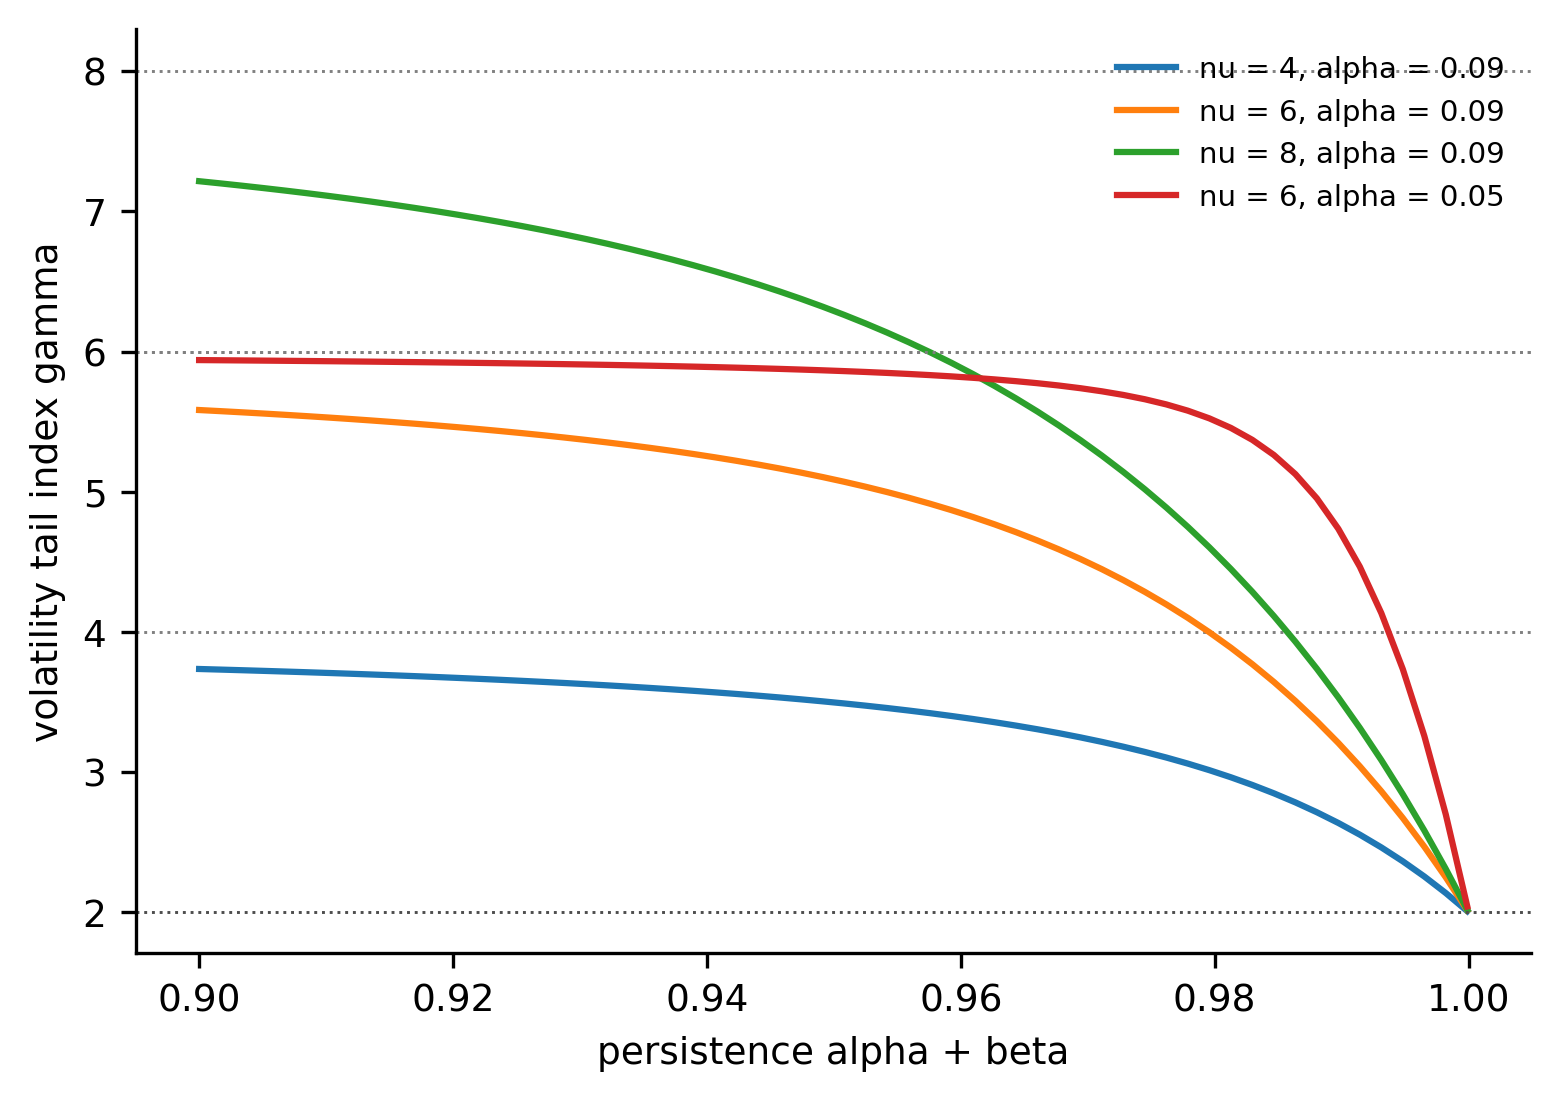

**Figure 3. Exceedance-rate ratios, raw and filtered losses (95% Katz intervals)**

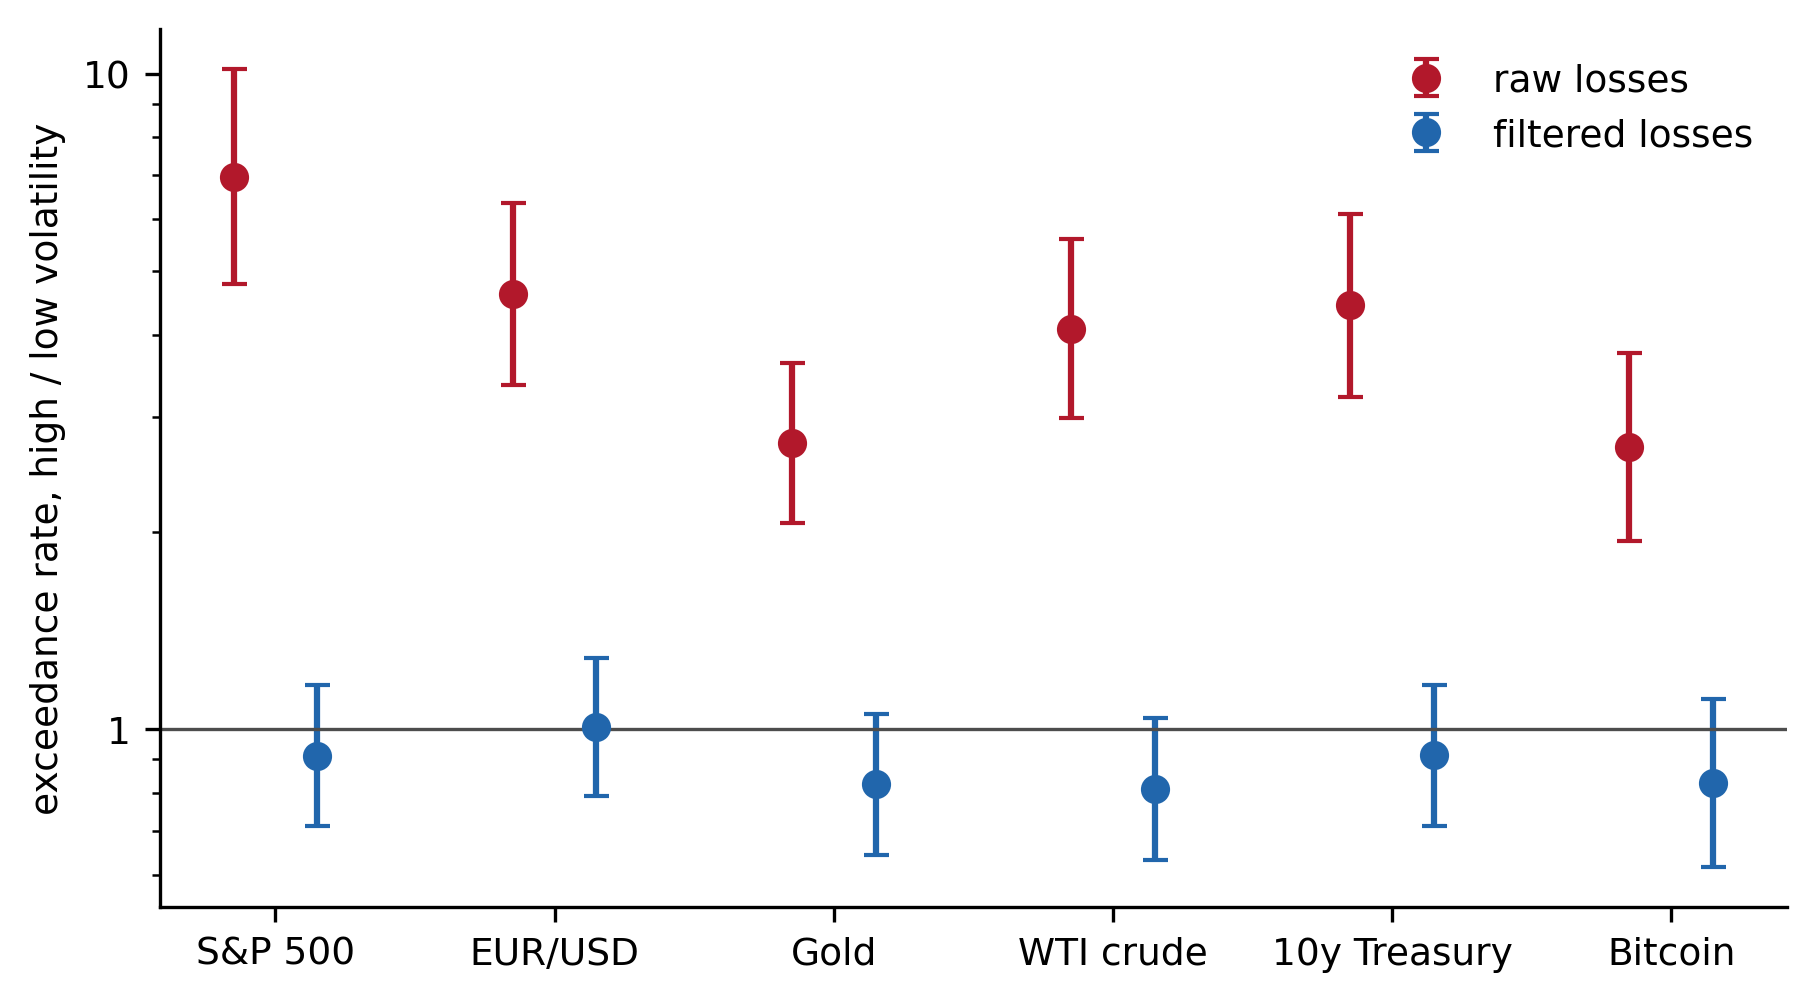

**Figure 4. Regime map: gamma vs nu, every asset x window**

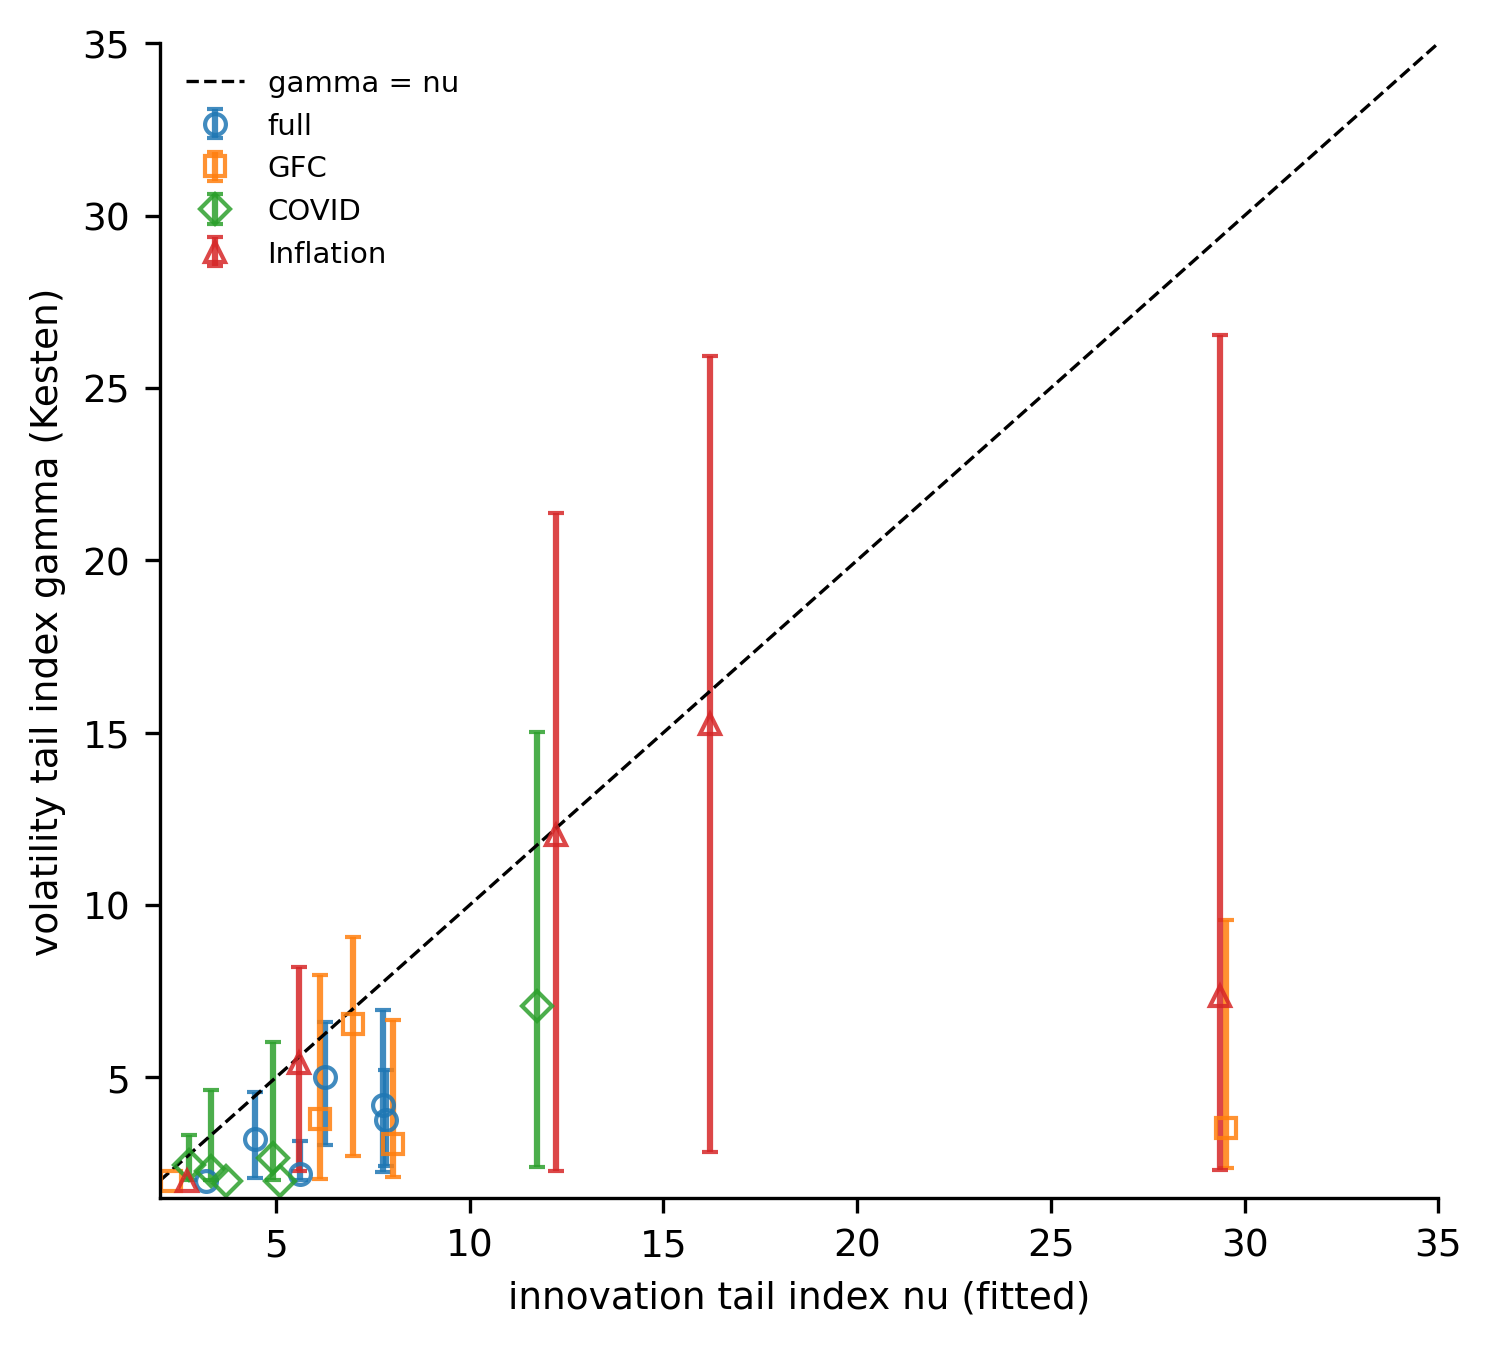

**Figure 5. gamma / nu by asset and window**

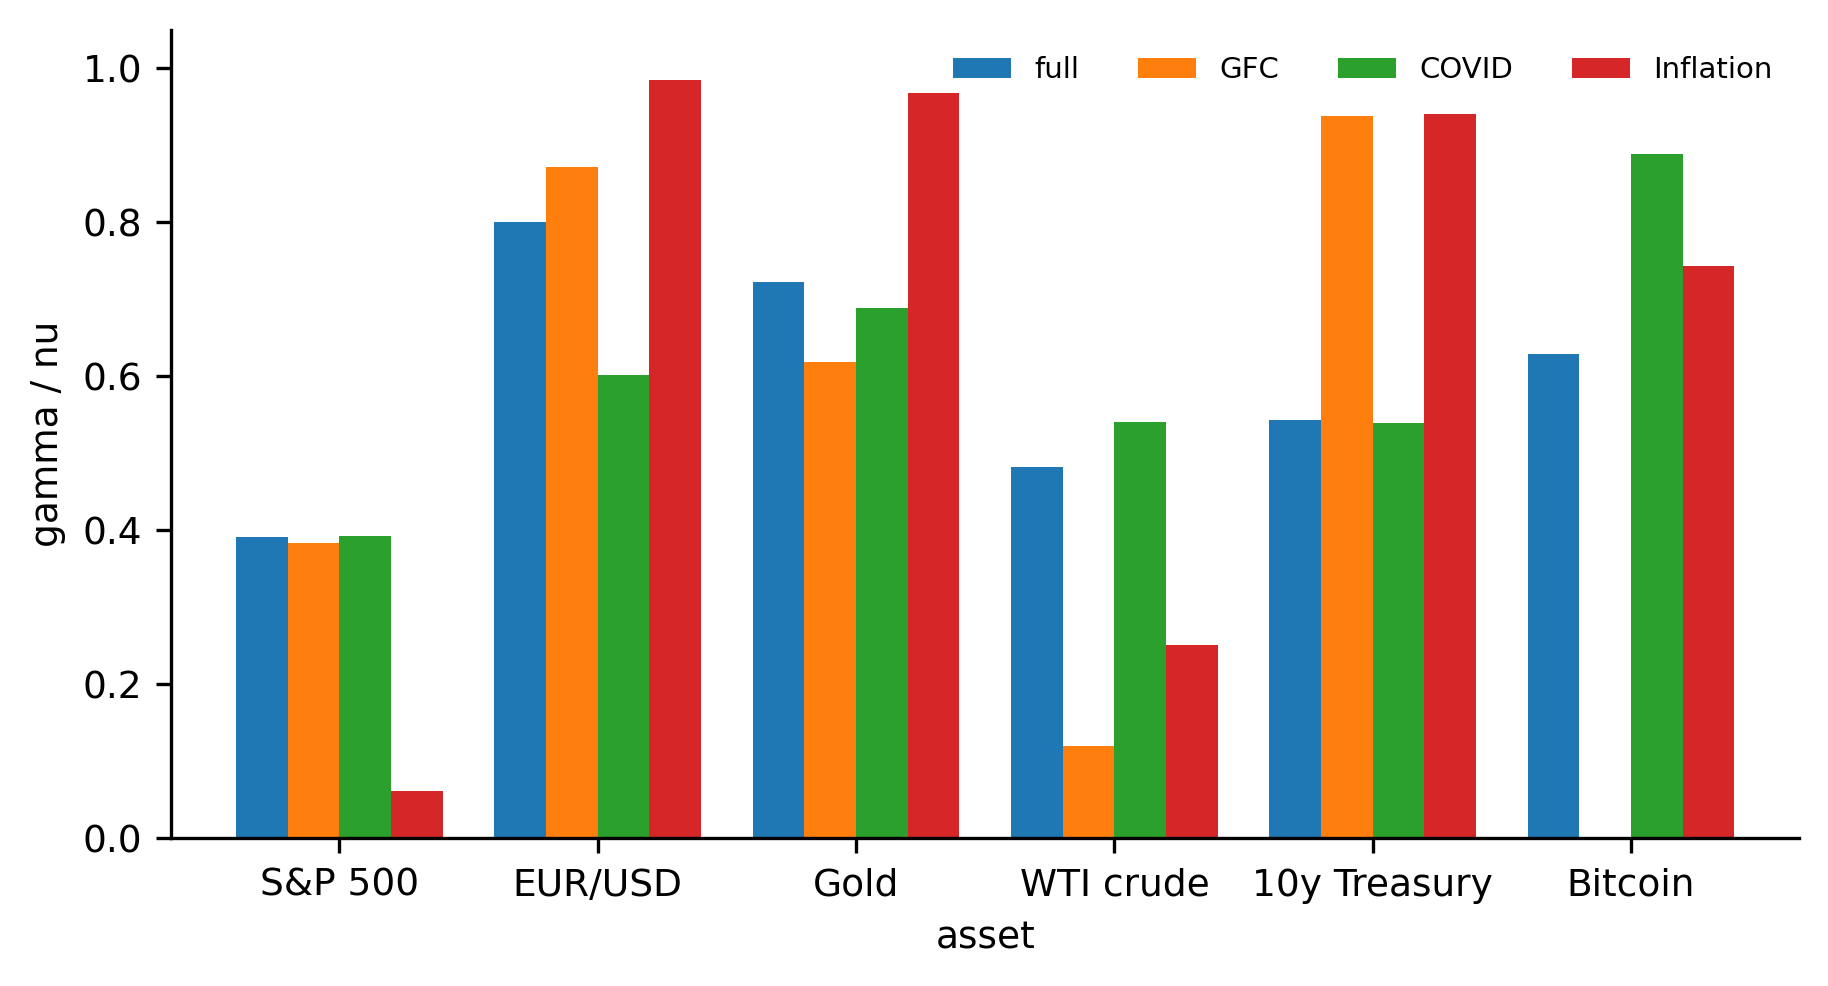

**Figure 6. Empirical survival above the 95% quantile, log-log**

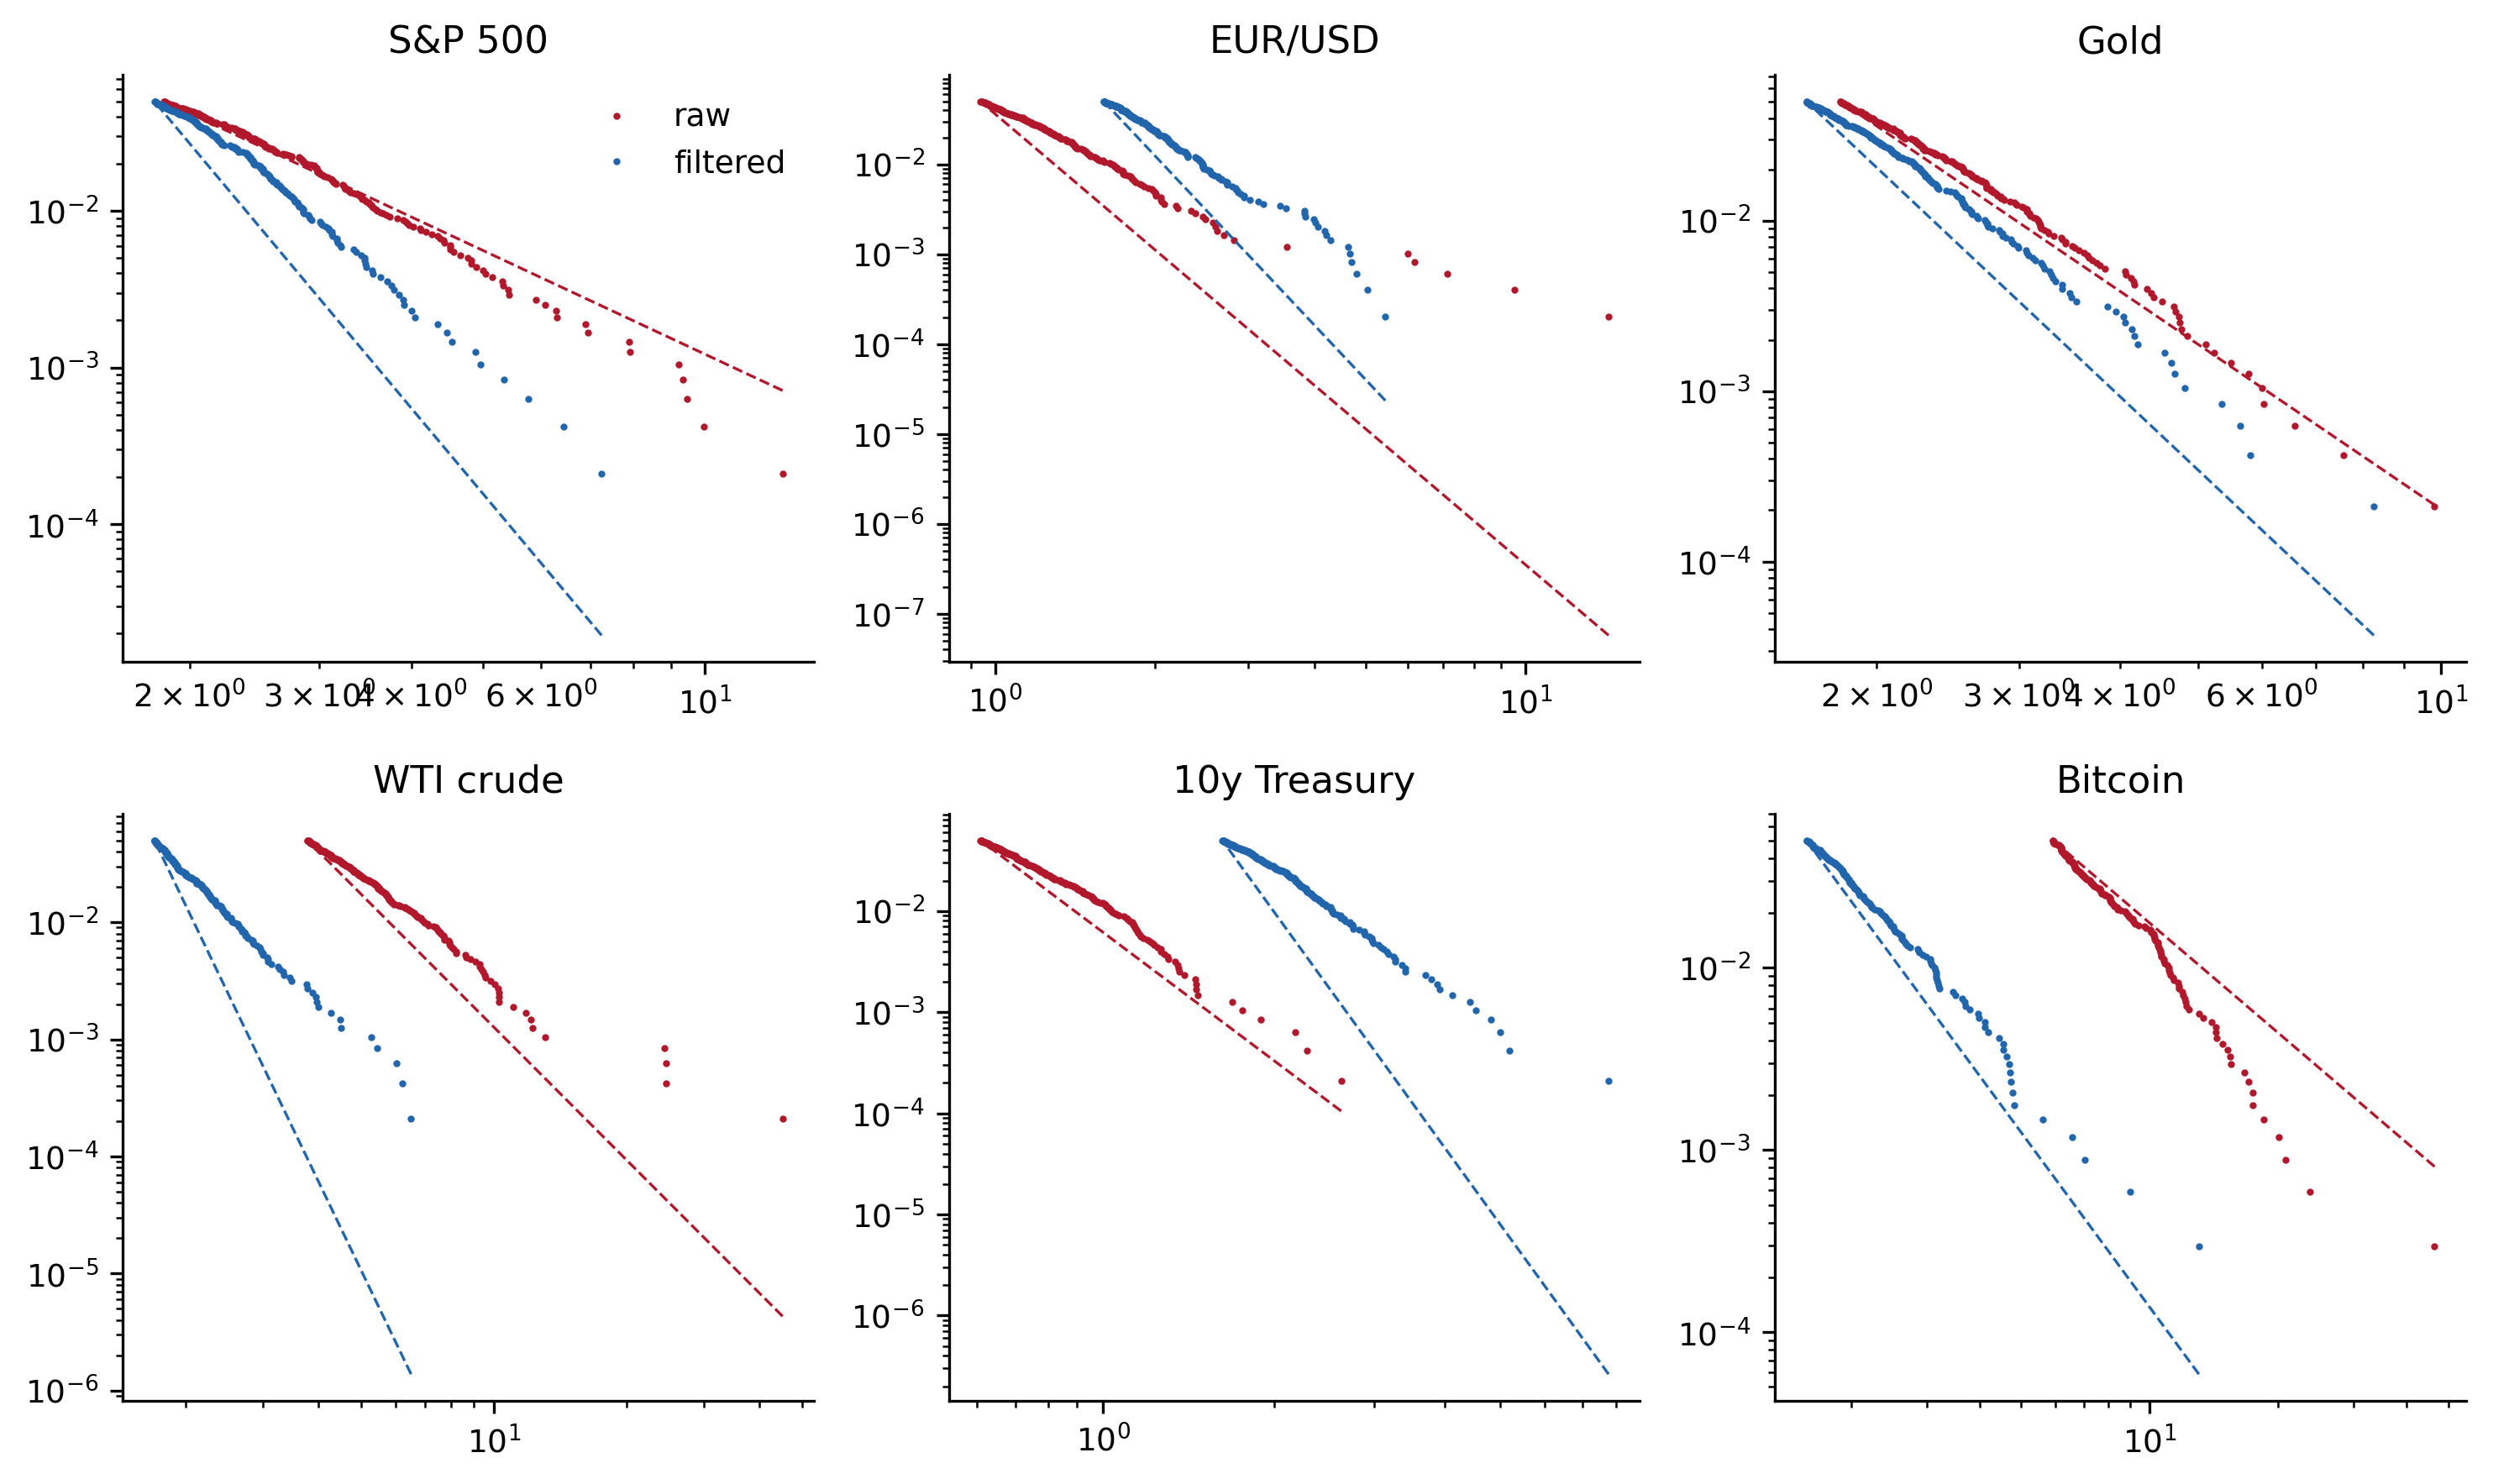

**Figure 7. Hill plots, raw vs filtered losses**

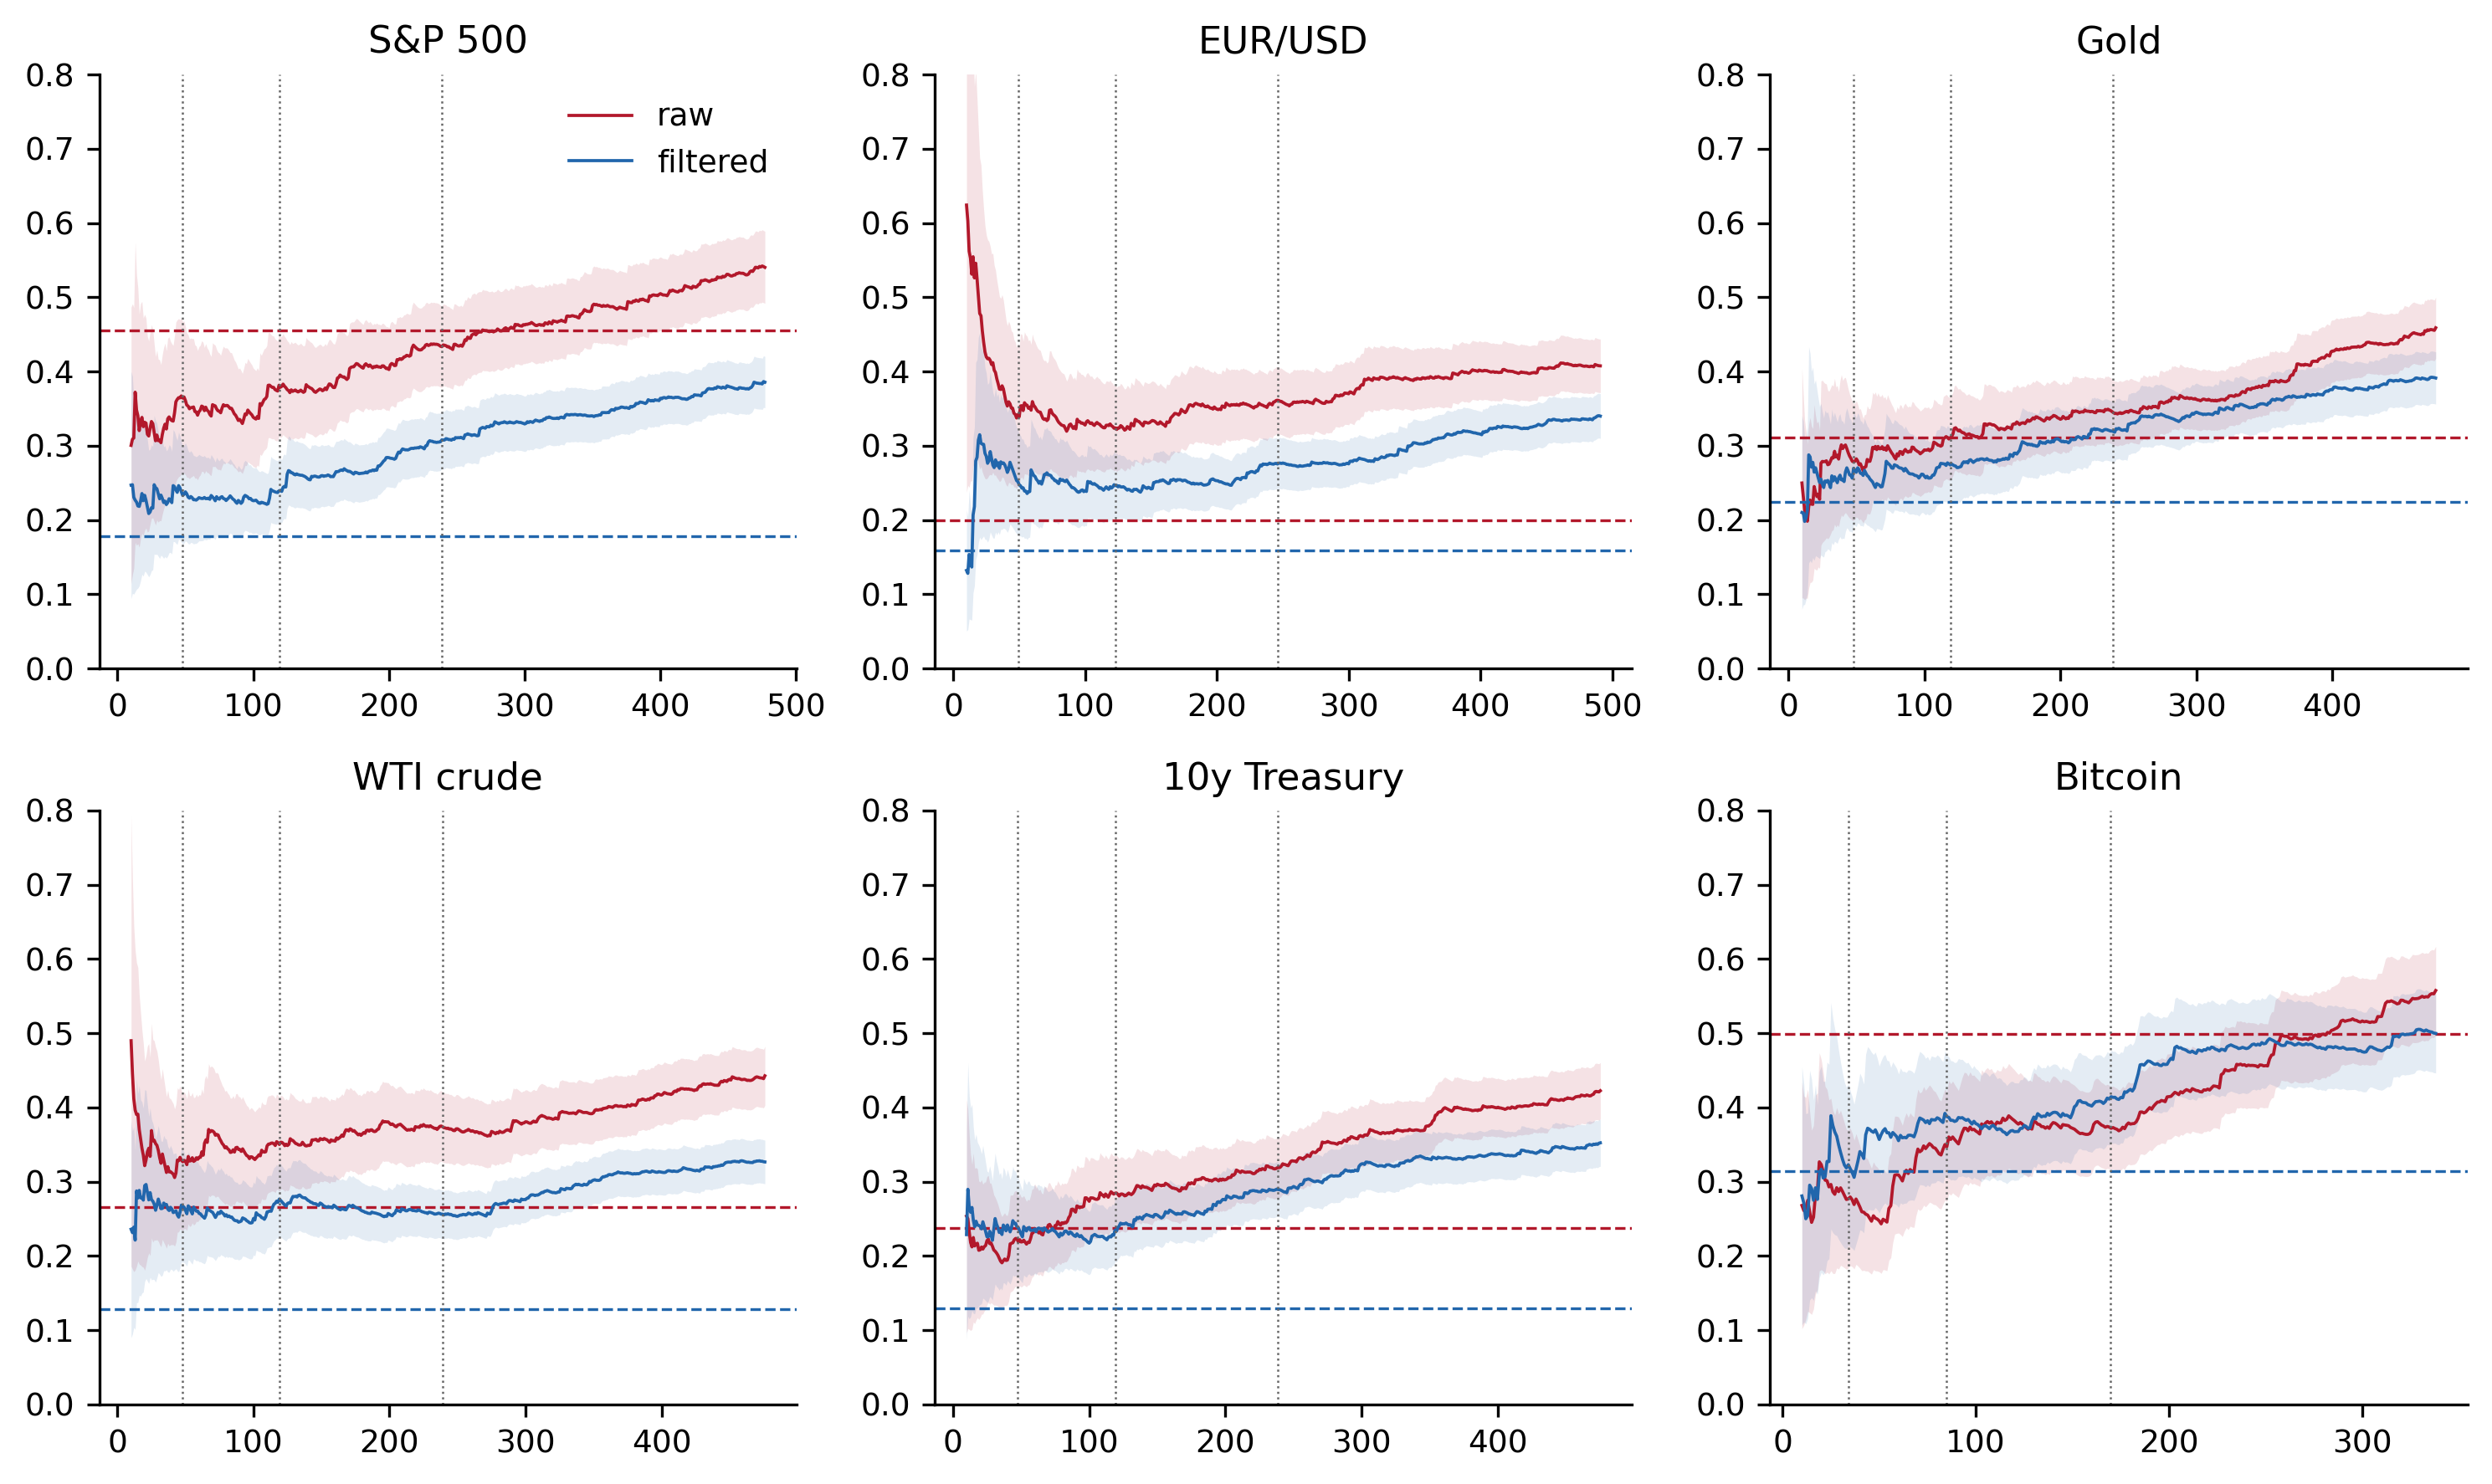

**Figure F1. Mean-excess plots and GPD shape stability**

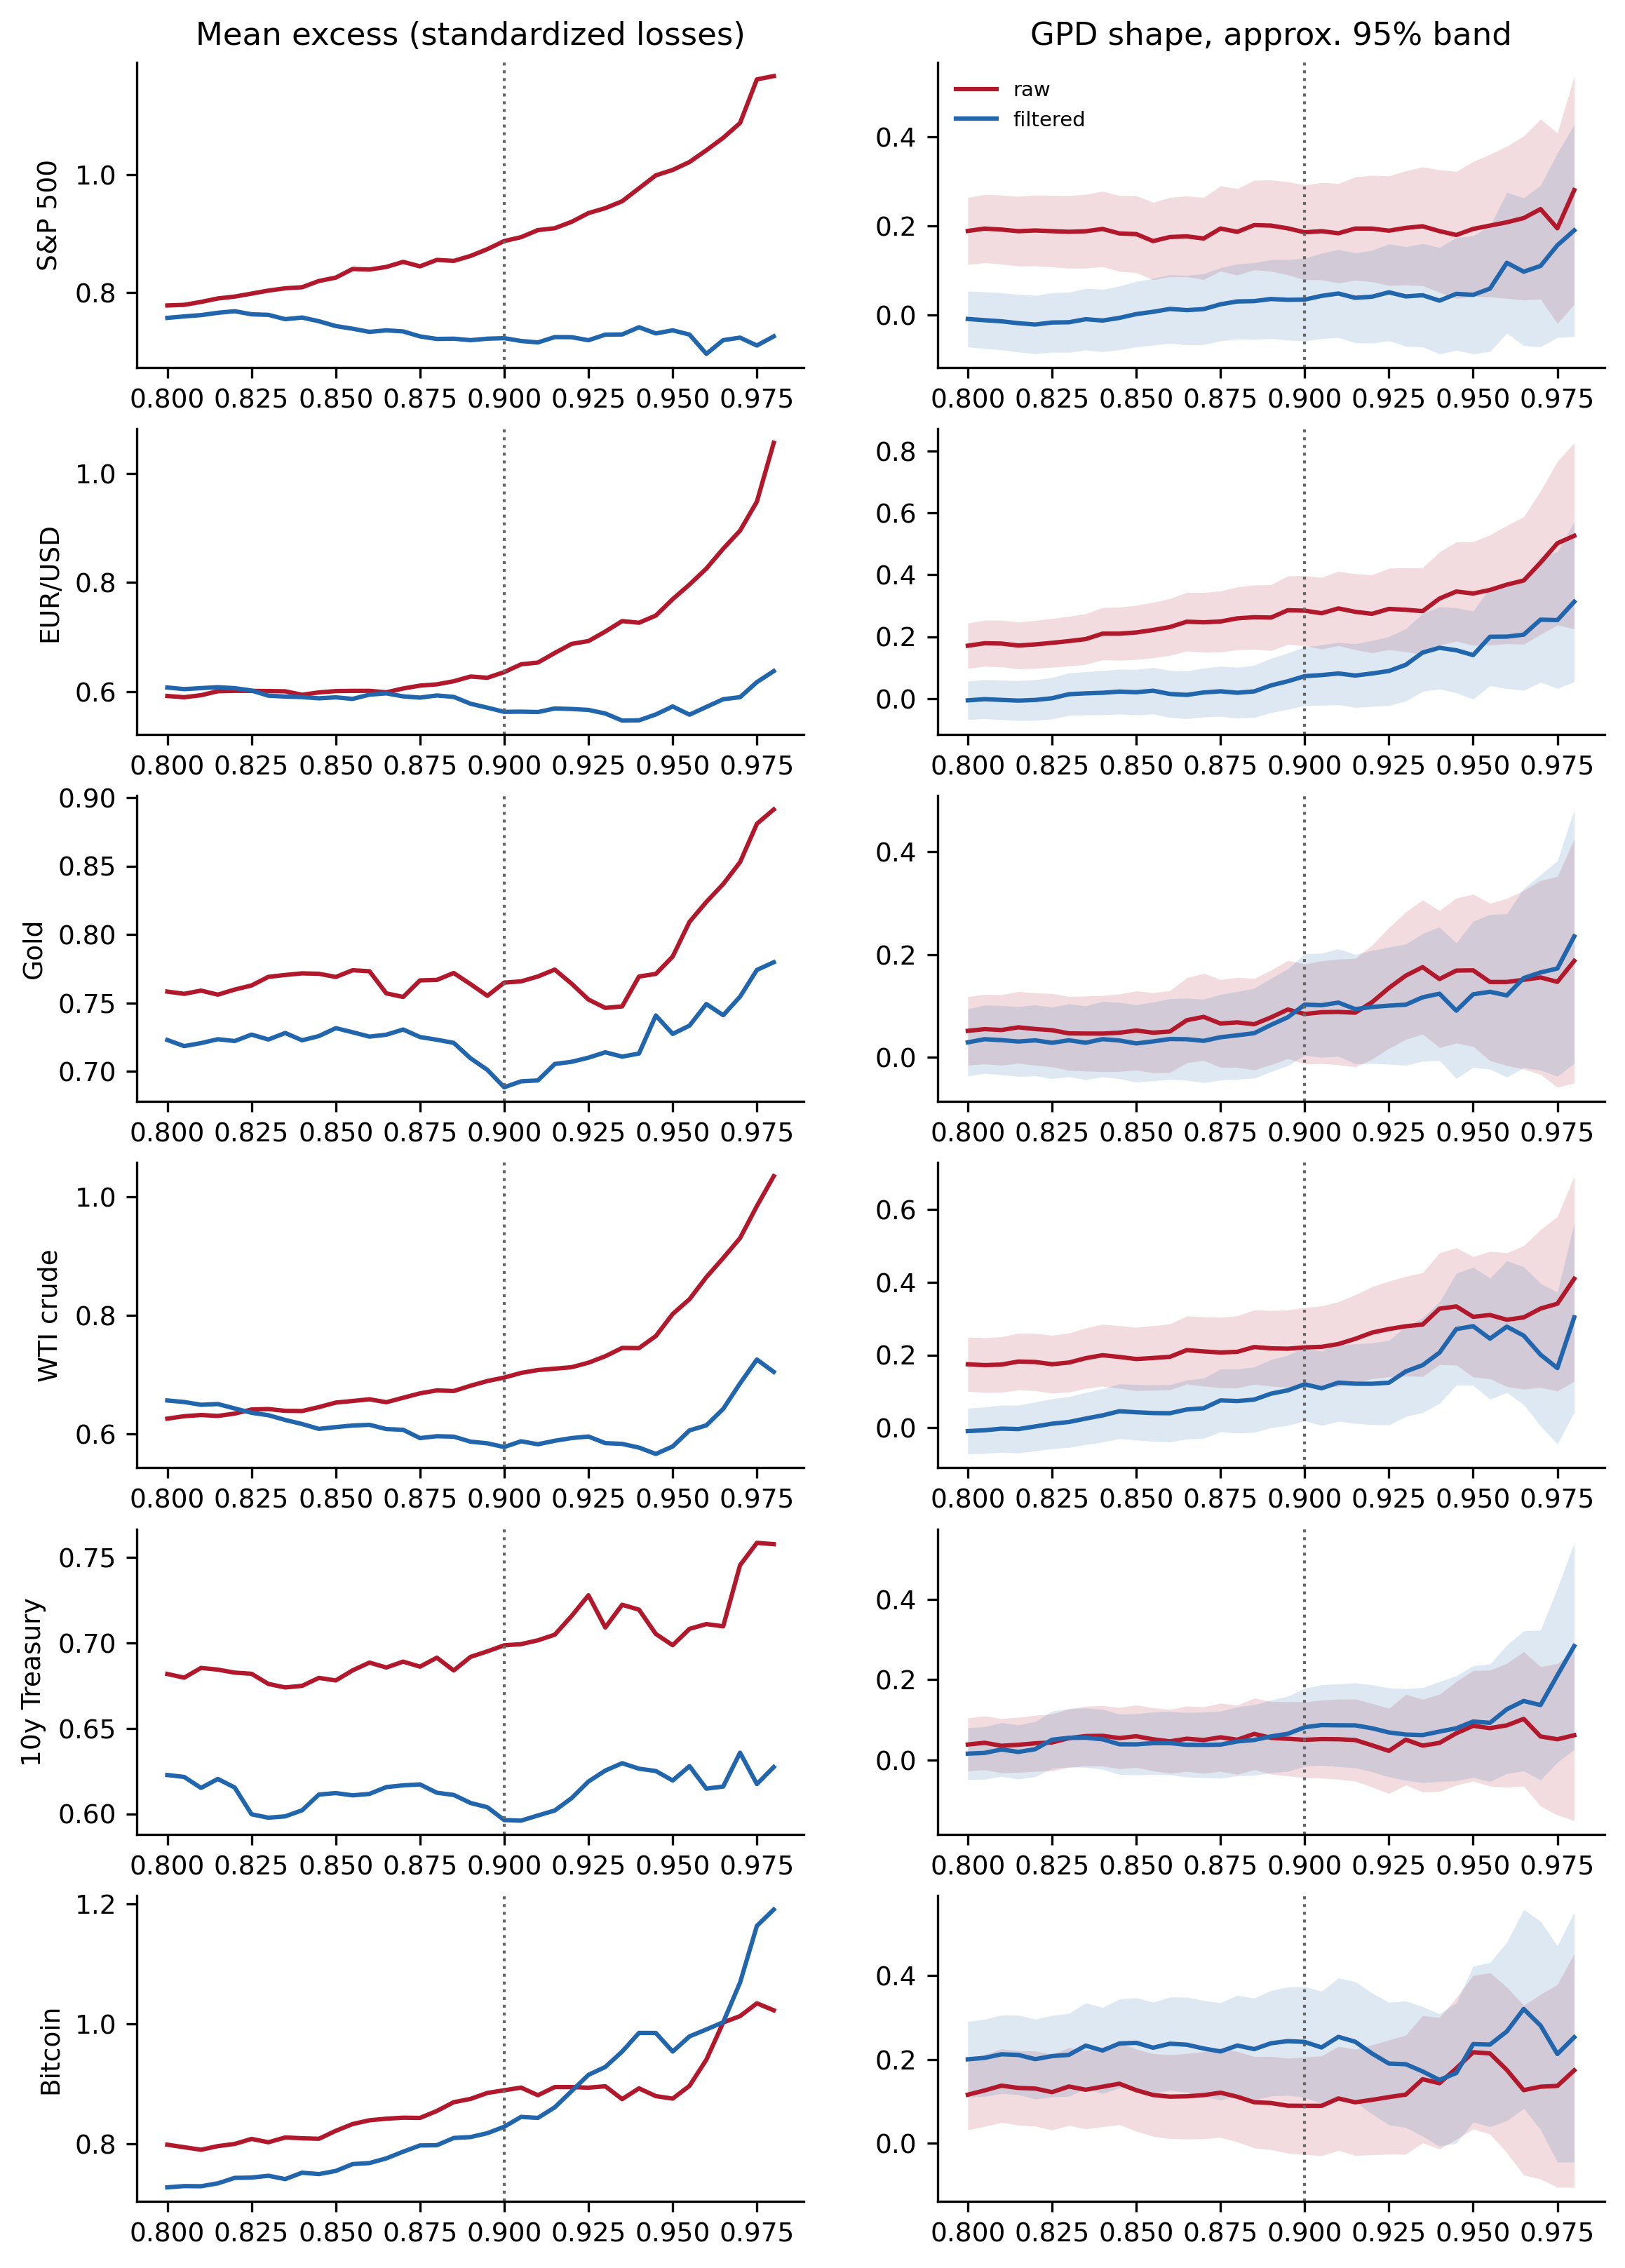

**Editor 2.3. Proposition 3: coefficient convergence and rate**

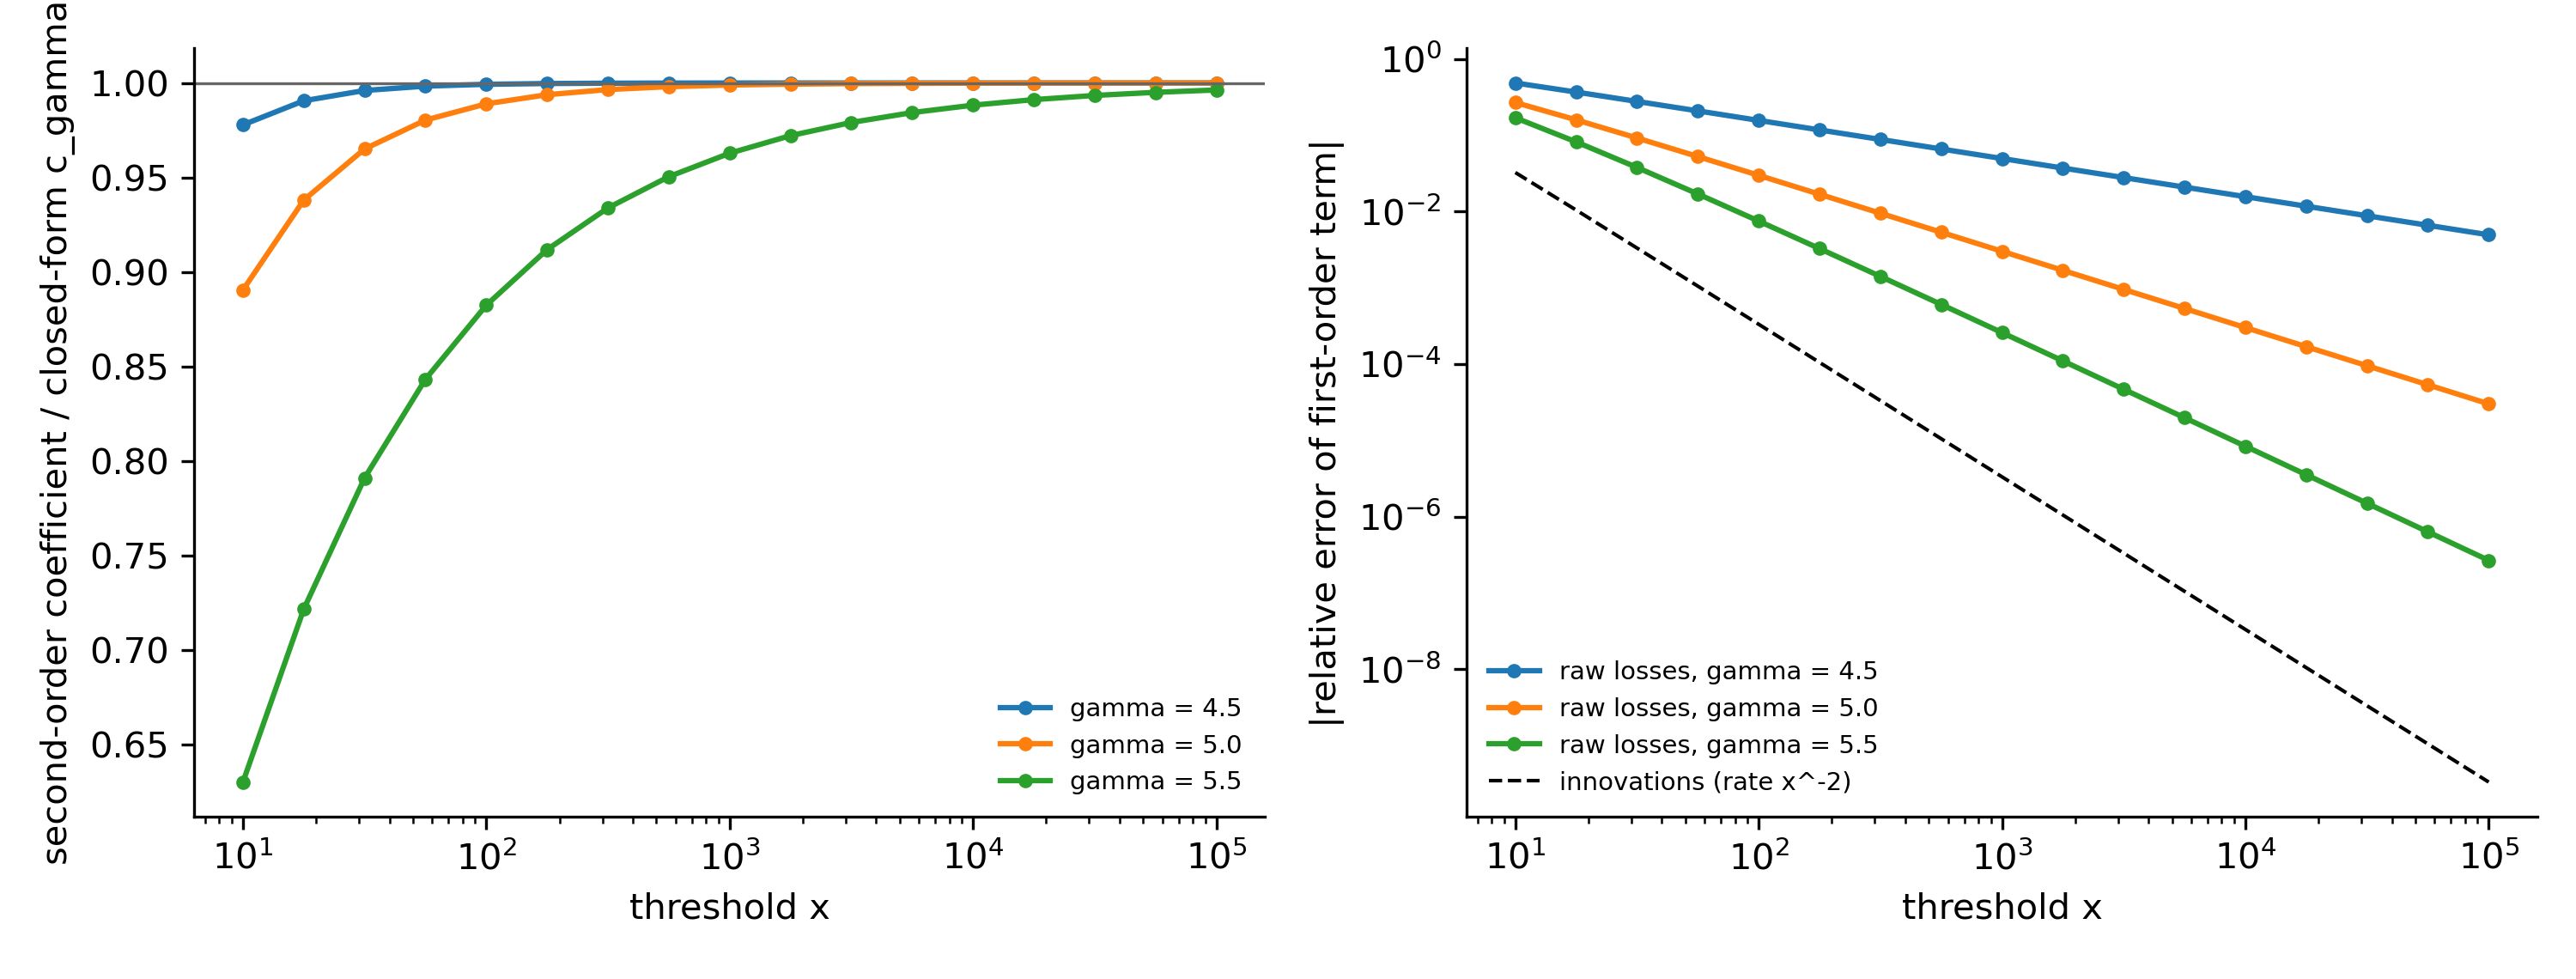

In [14]:
# =====================================================================================
# PART 12 — View every table and figure (in manuscript order) + one HTML report
# -------------------------------------------------------------------------------------
# Works right after Parts 0-11, OR on its own in a fresh kernel: it only reads the
# results folder. Shows each table and figure inline in Jupyter, and writes
# ldrift_results/report.html (all tables + figures embedded, opens in any browser).
# =====================================================================================
import base64
import html as _html
import json as _json
from pathlib import Path

import numpy as np
import pandas as pd

RESULTS_DIR = Path("ldrift_results")          # change if you used another out_dir
TABLES, FIGS = RESULTS_DIR / "tables", RESULTS_DIR / "figures"

try:
    from IPython import get_ipython
    from IPython.display import display, HTML, Image, Markdown
    _IN_NOTEBOOK = get_ipython() is not None and "IPKernelApp" in get_ipython().config
except ImportError:
    _IN_NOTEBOOK = False

# ---- what to show, in manuscript order: (file, title, note) -------------------------
SECTIONS = [
    ("Run checks", [
        ("table_checks", "Consistency checks", "Every row should read True before the results are used."),
        ("table_paper_vs_run", "Submitted manuscript vs this run",
         "Rows with changed = True are numbers to update in the text."),
        ("table_exceptions", "Exceptions to report (editor comment 3.9)",
         "Significant filtered-loss drift, conditional-model rejections and non-green zones."),
        ("table_data_summary", "Data used (Section 4.1)", "Dates are inclusive; SHA-256 identifies the snapshot."),
        ("table_data_checksums", "Archived data files: SHA-256 checksums (Data Availability Statement)", None),
        ("table_download_log", "Latest download vs archived snapshot", "The archive is never overwritten; revisions by Yahoo are reported here."),
    ]),
    ("Section 3 — Theory", [
        ("table1_gamma_grid", "Table 1. Volatility tail index gamma = 2 kappa, GARCH(1,1)-t, alpha = 0.09",
         "Middle row: nu from the 2006-09 S&P 500 fit."),
        ("table_gjr_examples", "Section 3.3. GJR-GARCH examples", "alpha + lambda/2 + beta = 0.98."),
        ("table_phase_grid", "Section 3.3. Parameter grid for nu - gamma", "Full grid; summary in the run log."),
    ]),
    ("Section 5.1 — Where the samples sit", [
        ("table2_full_samples", "Table 2. Full-sample fits, gamma with interval, Hill at k = 2.5% of n",
         "Interval centred on the displayed fit; draws kept/discarded reported."),
        ("tableB1_regimes", "Table B1. Fits for every asset x window", None),
    ]),
    ("Section 5.2 — Drift test", [
        ("table3_drift95", "Table 3. Drift test at the 95% quantile, full samples",
         "Fisher and circular-shift p-values from the same run."),
        ("table4_threshold_profile", "Table 4. Drift ratio by threshold",
         "Log-log slope is descriptive (Appendix C)."),
        ("table_oos_drift", "Section 5.2. Out-of-sample drift tests (forecast and 20-day proxy splits)", None),
        ("table_drift_all", "All drift tests (every asset, window, threshold)", None),
    ]),
    ("Section 5.3 — Tail shape", [
        ("table_hill_all", "Hill estimates (reciprocal tail index) with bootstrap intervals", None),
        ("table5_hill_sim", "Table 5. Simulated Hill estimates, GARCH(1,1)-t long paths",
         "Percentile ranges over few paths are descriptive."),
    ]),
    ("Sections 5.4-5.5 — Backtests", [
        ("table6_7_var_backtests", "Tables 6 and 7. Rolling 99% VaR backtests (one set of forecasts)",
         "Zone = illustrative full-sample traffic-light classification."),
        ("table8_es_backtests", "Table 8. Expected Shortfall backtests at 97.5%",
         "Loss sign: positive Z1, Z2 = ES too small. Z1_sim_p, Z2_sim_p: one-sided simulation p-values "
         "(Acerbi & Szekely 2014) under each model's own predictive distribution; parameters treated as known."),
        ("table_refit_summary", "Rolling refits: failed fits and GPD fits with xi >= 1", None),
        ("table9_single_split", "Table 9. Single crisis split, S&P 500", None),
    ]),
    ("Section 5.6 — Data robustness", [
        ("table_robust_drift", "Robustness: drift tests", None),
        ("table_robust_var_backtests", "Robustness: VaR backtests", None),
        ("table_robust_es_backtests", "Robustness: ES backtests", None),
        ("table_robust_oos_drift", "Robustness: out-of-sample drift tests", None),
    ]),
    ("Editor's suggestions 2.1-2.4", [
        ("table_sensitivity_summary", "2.2 Backtest sensitivity: rejections out of 9 threshold x window settings",
         "Common evaluation sample; thresholds 85/90/95%, windows 1,000/1,500/2,000 days."),
        ("table_sensitivity_backtests", "2.2 Backtest sensitivity: every setting", None),
        ("table_prop3_rates", "2.3 Proposition 3: predicted vs fitted convergence rates",
         "Pareto volatility, standardized t(4) innovations; predicted slope -(gamma - nu)."),
        ("table_prop3_illustration", "2.3 Proposition 3: exact tails, second-order coefficient vs closed form", None),
        ("table_prop3_montecarlo", "2.3 Proposition 3: Monte Carlo check of the exact tails", None),
        ("table_gjr_skewt_fits", "2.4 GJR-GARCH with skewed-t innovations: full-sample fits",
         "gamma_gjr from the Kesten equation under the fitted skewed-t; EA_h1 < 1 = covariance stationary."),
        ("table_gjr_skewt_drift", "2.4 Drift test on GJR-skewed-t filtered losses", None),
        ("table_gjr_skewt_backtests", "2.4 Rolling GJR-skewed-t EVT backtests", None),
    ]),
    ("Appendices", [
        ("table_size_sim", "Size of the drift tests for filtered losses (editor comment 1.4)",
         "Rejection rate at 5% under the null; should be close to 0.05."),
        ("tableC1_profiles", "Table C1. Simulated threshold profiles, GARCH-t vs log-normal SV",
         "Long-path values are Monte Carlo approximations."),
        ("tableC1_notes", "Appendix C. Slopes and share of rising profiles", None),
        ("tableD1", "Table D1. Estimation of gamma and nu in simulated samples", None),
        ("tableE1_egarch_ratios", "Table E1. EGARCH drift ratios", None),
        ("tableE2_egarch_tail_index", "Table E2. EGARCH tail-index estimates (1/Hill)", None),
        ("tableF_threshold_diagnostics", "Appendix F. Mean excess and GPD shape by threshold", None),
    ]),
]
FIGURES = [
    ("fig2_gamma_vs_persistence", "Figure 2. gamma implied by the Kesten equation vs persistence"),
    ("fig3_exceedance_ratios", "Figure 3. Exceedance-rate ratios, raw and filtered losses (95% Katz intervals)"),
    ("fig4_regime_map", "Figure 4. Regime map: gamma vs nu, every asset x window"),
    ("fig5_gamma_over_nu", "Figure 5. gamma / nu by asset and window"),
    ("fig6_tail_survival", "Figure 6. Empirical survival above the 95% quantile, log-log"),
    ("fig7_hill_plots", "Figure 7. Hill plots, raw vs filtered losses"),
    ("figF1_threshold_diagnostics", "Figure F1. Mean-excess plots and GPD shape stability"),
    ("fig_prop3_illustration", "Editor 2.3. Proposition 3: coefficient convergence and rate"),
]
LONG_TABLES = {"table_phase_grid", "table_drift_all", "table_hill_all", "tableF_threshold_diagnostics",
               "table_sensitivity_backtests", "table_prop3_illustration"}
MAX_ROWS = 40          # long tables: first rows shown, full CSV in the tables folder


# ---- formatting -----------------------------------------------------------------------
def _is_p(col: str) -> bool:
    c = col.lower()
    return c.endswith("_p") or c == "p" or "_p_" in c or c.startswith("p_") or c.endswith("pvalue")


def fmt_table(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_bool_dtype(out[c]):
            continue
        if pd.api.types.is_object_dtype(out[c]):
            out[c] = out[c].fillna("")
            continue
        if pd.api.types.is_float_dtype(out[c]):
            vals = out[c].dropna()
            vals = vals[np.isfinite(vals)]
            if len(vals) and not _is_p(c) and np.all(vals == np.round(vals)) and vals.abs().max() >= 10:
                out[c] = out[c].map(lambda v: "" if pd.isna(v) else ("inf" if np.isinf(v) else f"{int(v):,}"))
                continue
            if _is_p(c):
                out[c] = out[c].map(lambda v: "" if pd.isna(v) else ("<0.001" if v < 0.001 else f"{v:.3f}"))
            else:
                out[c] = out[c].map(lambda v: "" if pd.isna(v) else ("inf" if np.isinf(v) else f"{v:,.3f}"))
    return out


def load(name: str):
    f = TABLES / f"{name}.csv"
    return pd.read_csv(f) if f.exists() else None


def fig_path(name: str):
    f = FIGS / f"{name}.png"
    return f if f.exists() else None


# ---- 1) inline view in Jupyter ----------------------------------------------------------
def show_all():
    if not _IN_NOTEBOOK:
        print("Not in Jupyter: open", (RESULTS_DIR / "report.html").resolve())
        return
    for sec, items in SECTIONS:
        display(Markdown(f"## {sec}"))
        for name, title, note in items:
            df = load(name)
            if df is None:
                display(Markdown(f"**{title}** — *not produced in this run* (`{name}.csv` missing)"))
                continue
            display(Markdown(f"**{title}**" + (f"  \n*{note}*" if note else "")))
            shown = df.head(MAX_ROWS) if name in LONG_TABLES else df
            try:
                display(fmt_table(shown).style.hide(axis="index"))
            except Exception:                       # pandas Styler needs jinja2
                display(fmt_table(shown))
            if len(shown) < len(df):
                display(Markdown(f"*First {MAX_ROWS} of {len(df):,} rows; full table: `tables/{name}.csv`*"))
    display(Markdown("## Figures"))
    for name, title in FIGURES:
        p = fig_path(name)
        display(Markdown(f"**{title}**" if p else f"**{title}** — *not produced*"))
        if p:
            display(Image(filename=str(p), width=900))


# ---- 2) one self-contained HTML report ----------------------------------------------------
CSS = """
body{font-family:system-ui,-apple-system,Segoe UI,Roboto,sans-serif;margin:0;background:#fafafa;color:#1d1d1f}
header{background:#1f3a5f;color:#fff;padding:20px 32px}header h1{margin:0;font-size:22px}
header p{margin:6px 0 0;opacity:.85;font-size:13px}
nav{position:sticky;top:0;background:#fff;border-bottom:1px solid #ddd;padding:8px 32px;font-size:13px;z-index:2}
nav a{margin-right:14px;color:#1f3a5f;text-decoration:none}
main{padding:8px 32px 48px;max-width:1400px}
h2{margin-top:36px;border-bottom:2px solid #1f3a5f;padding-bottom:4px;font-size:19px}
h3{font-size:15px;margin:24px 0 4px}.note{color:#555;font-size:12.5px;margin:0 0 8px}
.wrap{overflow-x:auto;background:#fff;border:1px solid #e3e3e3;border-radius:6px}
table{border-collapse:collapse;font-size:12px;width:max-content;min-width:100%}
th{background:#eef2f7;text-align:right;padding:5px 9px;position:sticky;top:0;white-space:nowrap}
td{padding:4px 9px;text-align:right;border-top:1px solid #f0f0f0;white-space:nowrap;font-variant-numeric:tabular-nums}
td:first-child,th:first-child{text-align:left}tr:hover td{background:#f7f9fc}
.missing{color:#a33;font-style:italic}.more{color:#666;font-size:12px;margin-top:4px}
figure{background:#fff;border:1px solid #e3e3e3;border-radius:6px;padding:12px;margin:16px 0}
figure img{max-width:min(100%,900px);height:auto;display:block}figcaption{font-size:13px;font-weight:600;margin-bottom:8px}
td.fail{background:#fde8e8;color:#9b1c1c;font-weight:600}td.pass{color:#1e6b34}
"""


def _table_html(name, df):
    shown = df.head(MAX_ROWS) if name in LONG_TABLES else df
    f = fmt_table(shown)
    h = f.to_html(index=False, escape=True, border=0)
    if name == "table_checks":
        h = h.replace("<td>True</td>", '<td class="pass">True</td>').replace("<td>False</td>", '<td class="fail">False</td>')
    more = (f'<p class="more">First {MAX_ROWS} of {len(df):,} rows; full table in tables/{name}.csv</p>'
            if len(shown) < len(df) else "")
    return f'<div class="wrap">{h}</div>{more}'


def write_report(path=None):
    path = Path(path or RESULTS_DIR / "report.html")
    man = {}
    if (RESULTS_DIR / "manifest.json").exists():
        man = _json.loads((RESULTS_DIR / "manifest.json").read_text(encoding="utf-8"))
    sub = (f"Run finished {man.get('run_finished', '?')} · quick mode: {man.get('quick_mode', '?')} · "
           f"Python {man.get('versions', {}).get('python', '?')}")
    ids = [f"s{i}" for i in range(len(SECTIONS))] + ["figs"]
    nav = "".join(f'<a href="#{i}">{_html.escape(s)}</a>' for i, (s, _) in zip(ids, SECTIONS)) + '<a href="#figs">Figures</a>'
    body = []
    for i, (sec, items) in enumerate(SECTIONS):
        body.append(f'<h2 id="s{i}">{_html.escape(sec)}</h2>')
        for name, title, note in items:
            body.append(f"<h3>{_html.escape(title)}</h3>")
            if note:
                body.append(f'<p class="note">{_html.escape(note)}</p>')
            df = load(name)
            body.append(_table_html(name, df) if df is not None
                        else f'<p class="missing">Not produced in this run ({name}.csv missing).</p>')
    body.append('<h2 id="figs">Figures</h2>')
    for name, title in FIGURES:
        p = fig_path(name)
        if p:
            b64 = base64.b64encode(p.read_bytes()).decode()
            body.append(f'<figure><figcaption>{_html.escape(title)}</figcaption>'
                        f'<img alt="{_html.escape(title)}" src="data:image/png;base64,{b64}"></figure>')
        else:
            body.append(f'<p class="missing">{_html.escape(title)}: not produced.</p>')
    page = (f'<!doctype html><html lang="en"><head><meta charset="utf-8">'
            f'<meta name="viewport" content="width=device-width,initial-scale=1">'
            f'<title>Latent Boundary Drift Results</title><style>{CSS}</style></head><body>'
            f'<header><h1>Latent Boundary Drift — results</h1><p>{_html.escape(sub)}</p></header>'
            f'<nav>{nav}</nav><main>{"".join(body)}</main></body></html>')
    path.write_text(page, encoding="utf-8")
    print("Report written:", path.resolve())
    return path


write_report()
show_all()

In [15]:
   import sys, numpy, pandas, scipy, matplotlib
   print("Python", sys.version.split()[0])
   for m in (numpy, pandas, scipy, matplotlib):
       print(m.__name__, m.__version__)

Python 3.12.7
numpy 1.26.4
pandas 2.2.2
scipy 1.13.1
matplotlib 3.9.2


In [16]:
import hashlib
from pathlib import Path

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

# Use the pipeline's data folder if CFG exists, otherwise the default
try:
    data_dir = Path(CFG["data_dir"])
except NameError:
    data_dir = Path("data/clean")

files = sorted(data_dir.glob("*_clean.csv")) or sorted(data_dir.glob("*.csv"))
if not files:
    print(f"No CSV files found in {data_dir.resolve()}")

rows = []
for f in files:
    digest = sha256_file(f)
    rows.append((f.name, digest))
    print(f"{f.name:<25} {digest}")

# Save a copy for the replication package
out = data_dir / "CHECKSUMS_sha256.csv"
with open(out, "w") as fh:
    fh.write("file,sha256\n")
    for name, digest in rows:
        fh.write(f"{name},{digest}\n")
print(f"\nSaved to {out}")

BTC_clean.csv             79a65ebd28b618b418142267a21e2a55cb23763872418dce04c3f2f527f88529
EURUSD_clean.csv          d05da6bf8ec016c9df87f350d2d81509548bbed26362926cefadeaa18653c5e1
GLD_clean.csv             56207f9591af599a0b780bd7dcb321994c89bb6f1b7ed4bd3fb546c8df81b8ef
GOLD_clean.csv            f4746cb467b46865ca5bd9b8d3b090aa6735bd9550252118985435178e48809b
IEF_clean.csv             8da867b83d829adca6109126781fb044a60a74c5f69f5746972ae01daedc9922
SP500_clean.csv           ec2f485bc8e2ae785a4246ba88e8d5524b3d38c1da3b21ad9ddde7181d113ff2
USO_clean.csv             26cbf7a5dcdc3dc984018b59246bf21fb10fcfcb98a9ca10bc02fe807cc004a3
UST10Y_clean.csv          ef788867ed2202c37dbe90cf9f62287f44ff160063d4620a28aa04258957ec94
WTI_clean.csv             3d1be91bba256bdb30eabac1050ebf2720a079a8d2dfeaa74955df7ca533f54a

Saved to data\clean\CHECKSUMS_sha256.csv


In [17]:
import pandas as pd
import numpy as np
from pathlib import Path

# Folder with the pipeline's output tables; change it if yours is elsewhere
T = Path("ldrift_results/tables")
if not (T / "table_drift_all.csv").exists():
    T = Path(".")

drift = pd.read_csv(T / "table_drift_all.csv")
hill  = pd.read_csv(T / "table_hill_all.csv")

def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

# ---------------------------------------------------------------
# Table B1: WTI window cells marked ‡
#   Hill filt.        = hill estimate, filtered losses, k = 2.5% of n
#   Drift ratio, raw  = ratio at the 95% quantile (Fisher p), raw losses
#   Drift ratio, filt = ratio at the 95% quantile (Fisher p), filtered losses
# ---------------------------------------------------------------
print("TABLE B1 - WTI rows")
print(f"{'Window':<10}{'Hill raw':>10}{'Hill filt.':>12}{'Drift raw (p)':>20}{'Drift filt. (p)':>20}")
for w in ["full", "GFC", "COVID", "Inflation"]:
    h = hill[(hill.asset == "WTI") & (hill.window == w) & np.isclose(hill.k_frac, 0.025)]
    d = drift[(drift.asset == "WTI") & (drift.window == w) & np.isclose(drift.q, 0.95)]
    if h.empty or d.empty:
        print(f"{w:<10} no rows found")
        continue
    h_raw  = h.loc[h.losses == "raw", "hill"].iloc[0]
    h_filt = h.loc[h.losses == "filtered", "hill"].iloc[0]
    dr = d[d.losses == "raw"].iloc[0]
    df = d[d.losses == "filtered"].iloc[0]
    raw_cell  = f"{dr.ratio:.2f} ({fmt_p(dr.fisher_p)})"
    filt_cell = f"{df.ratio:.2f} ({fmt_p(df.fisher_p)})"
    print(f"{w:<10}{h_raw:>10.3f}{h_filt:>12.3f}{raw_cell:>20}{filt_cell:>20}")

# ---------------------------------------------------------------
# Table H1: gamma = 5.5, coefficient at x = 10^3
# ---------------------------------------------------------------
P3 = T / "table_prop3_illustration.csv"
if P3.exists():
    p3 = pd.read_csv(P3)
    print("\nTABLE H1 - second-order coefficient")
    for g in [4.5, 5.0, 5.5]:
        vals = []
        for x in [1e1, 1e2, 1e3, 1e5]:
            r = p3[np.isclose(p3.gamma, g) & np.isclose(p3.x, x)]
            vals.append(f"{r.second_order_coef.iloc[0]:.3f}" if len(r) else "n/a")
        print(f"gamma = {g}:  x=10: {vals[0]}  x=10^2: {vals[1]}  x=10^3: {vals[2]}  x=10^5: {vals[3]}")
else:
    print("\ntable_prop3_illustration.csv not found in", T.resolve())

TABLE B1 - WTI rows
Window      Hill raw  Hill filt.       Drift raw (p)     Drift filt. (p)
full           0.350       0.277       4.09 (<0.001)        0.81 (0.111)
GFC            0.216       0.147      15.00 (<0.001)        0.68 (0.365)
COVID          0.610       0.446        inf (<0.001)        0.62 (0.571)
Inflation      0.201       0.165        1.78 (0.157)        0.93 (1.000)

TABLE H1 - second-order coefficient
gamma = 4.5:  x=10: -10.344  x=10^2: -10.571  x=10^3: -10.579  x=10^5: -10.579
gamma = 5.0:  x=10: -10.074  x=10^2: -11.189  x=10^3: -11.301  x=10^5: -11.314
gamma = 5.5:  x=10: -14.735  x=10^2: -20.636  x=10^3: -22.517  x=10^5: -23.299
